# 🧪 Đánh Giá (Test) & Trực Quan Hóa (Visualization) - Bộ Dữ Liệu Forest Covertype

Notebook này chịu trách nhiệm **đánh giá hiệu năng thực tế (Test Accuracy, F1-Score, Confusion Matrix)** và **trực quan hóa kiểm thử** trên bộ dữ liệu **Forest Covertype** sau khi tối ưu hóa siêu tham số bằng các biến thể **Particle Swarm Optimization (PSO)**.

### 📌 Nội dung thực hiện:
1. **Chuẩn bị dữ liệu Test**: Đồng bộ quy trình lấy mẫu phân tầng (Stratified Sampling 30,000 mẫu, tỷ lệ 80/20 Train/Test) và chuẩn hóa (StandardScaler) với tập Train.
2. **Biểu đồ phân bổ chia Train/Test**: Trực quan hóa số lượng mẫu cụ thể của từng lớp trong 2 tập.
3. **Đánh giá Standard PSO trên tập Test**: Nạp nghiệm tối ưu từ checkpoint `standard_pso.pkl`, huấn luyện mô hình MLP trên toàn bộ tập Train (24,000 mẫu) và đánh giá khách quan trên tập Test (6,000 mẫu).
4. **Đánh giá Linear Decay PSO trên tập Test**: Nạp nghiệm tối ưu từ checkpoint `linear_decay_pso.pkl`, huấn luyện mô hình MLP và đánh giá hiệu năng trên tập Test.
5. **Trực quan hóa không gian tìm kiếm hạt (Biểu đồ phân tán 1:1 vuông, màu pastel nhẹ nhàng)**:
   - Biểu đồ phân tán 2D các hạt ($n_{neurons}$ vs $\log_{10}(lr)$) và ($n_{neurons}$ vs $\log_{10}(lpha)$).
   - Biểu đồ đối sánh phân bố hạt giữa Standard PSO vs Linear Decay PSO.
   - Đồ thị hội tụ $G_{best}$ kết hợp đường suy giảm quán tính $w(t)$ tuyến tính ($0.9 	o 0.4$).
6. **Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix)**: Ma trận số lượng thực tế & Ma trận chuẩn hóa %.
7. **Biểu đồ Cột Hiệu năng từng lớp (Per-Class Metrics)**: So sánh Precision, Recall, F1-Score cho toàn bộ 7 loại rừng Covertype.
8. **Bảng tổng hợp & Đồ thị đối sánh tổng thể**: Lưu và hiển thị kết quả từ `results/test_results/test_accuracy.csv`.


## 📦 1. Cài đặt và Khai báo Thư viện


In [ ]:
import sys
if sys.stdout and hasattr(sys.stdout, "reconfigure"):
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("✅ Khai báo thư viện cho Notebook Test thành công!")


✅ Khai báo thư viện cho Notebook Test thành công!


## 📊 2. Tải và Tiền Xử Lý Dữ Liệu Test (Đồng Bộ Tuyệt Đối Với Tập Train)


In [2]:
# Định nghĩa lại các cột đặc trưng và nhãn
CONTINUOUS_COLS = [
    'Elevation', 'Aspect', 'Slope',
    'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
    'Horizontal_Distance_To_Roadways',
    'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
    'Horizontal_Distance_To_Fire_Points'
]
WILDERNESS_COLS = [f'Wilderness_Area_{i}' for i in range(1, 5)]
SOIL_COLS = [f'Soil_Type_{i}' for i in range(1, 41)]
ALL_FEATURE_COLS = CONTINUOUS_COLS + WILDERNESS_COLS + SOIL_COLS
TARGET_COL = 'Cover_Type'
COL_NAMES = ALL_FEATURE_COLS + [TARGET_COL]

COVER_TYPE_NAMES = {
    1: 'Spruce/Fir',
    2: 'Lodgepole Pine',
    3: 'Ponderosa Pine',
    4: 'Cottonwood/Willow',
    5: 'Aspen',
    6: 'Douglas-fir',
    7: 'Krummholz'
}

data_path = '../data/raw/covertype/covtype.data'
if not os.path.exists(data_path):
    data_path = 'data/raw/covertype/covtype.data'

df = pd.read_csv(data_path, header=None, names=COL_NAMES)
df['Cover_Type_Name'] = df['Cover_Type'].map(COVER_TYPE_NAMES)

# Áp dụng cấu hình lấy mẫu phân tầng đồng bộ với Train
USE_SAMPLE = True
SAMPLE_SIZE = 30000

if USE_SAMPLE and SAMPLE_SIZE is not None and SAMPLE_SIZE < len(df):
    working_df, _ = train_test_split(
        df, train_size=SAMPLE_SIZE, stratify=df[TARGET_COL], random_state=RANDOM_SEED
    )
else:
    working_df = df

X = working_df[ALL_FEATURE_COLS].values
y = (working_df[TARGET_COL].values - 1).astype(int)

# Tách tập Train (80%) và Test (20%) cùng seed 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

# Fit scaler trên tập Train, transform cho cả Train và Test
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print("=" * 65)
print("        DỮ LIỆU TẬP TEST ĐÃ SẴN SÀNG")
print("=" * 65)
print(f"  Kích thước tập Test  : {X_test_sc.shape[0]:,} mẫu | {X_test_sc.shape[1]} đặc trưng")
print(f"  Phân phối nhãn Test  : {dict(zip(*np.unique(y_test, return_counts=True)))}")
print("=" * 65)


        DỮ LIỆU TẬP TEST ĐÃ SẴN SÀNG
  Kích thước tập Test  : 6,000 mẫu | 54 đặc trưng
  Phân phối nhãn Test  : {np.int64(0): np.int64(2188), np.int64(1): np.int64(2926), np.int64(2): np.int64(369), np.int64(3): np.int64(28), np.int64(4): np.int64(98), np.int64(5): np.int64(179), np.int64(6): np.int64(212)}


## 📊 3. Biểu Đồ Phân Bổ Chia Train / Test Của Từng Lớp


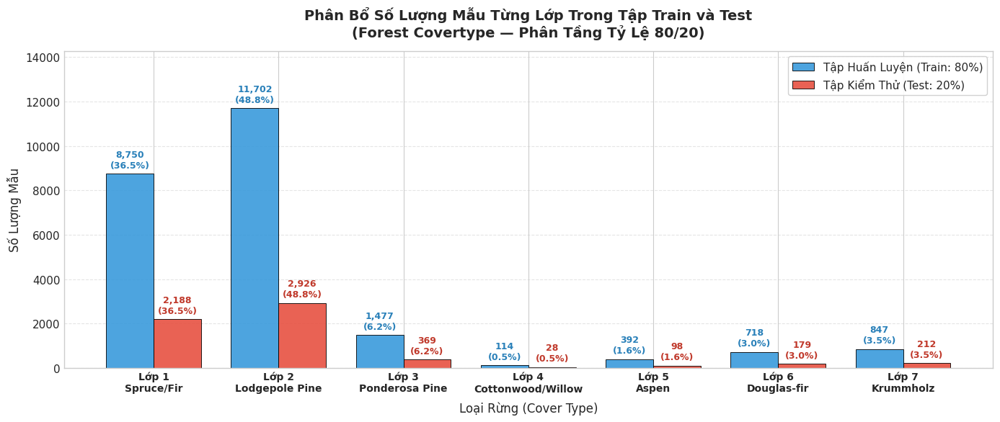

In [3]:
# Sample count distribution across 7 forest cover types
fig, ax = plt.subplots(figsize=(10, 4.5))
classes = np.arange(1, 8)
train_counts = [(y_train == i).sum() for i in range(7)]
test_counts  = [(y_test == i).sum() for i in range(7)]

x = np.arange(len(classes))
w = 0.38

ax.bar(x - w/2, train_counts, w, label='Training Set (80%)', color='#3498db', edgecolor='black', alpha=0.88)
ax.bar(x + w/2, test_counts,  w, label='Holdout Test Set (20%)', color='#2ecc71', edgecolor='black', alpha=0.88)

for i in range(len(classes)):
    ax.text(x[i] - w/2, train_counts[i] + 70, f'{train_counts[i]:,}', ha='center', fontsize=8.5, fontweight='bold', color='#1f618d')
    ax.text(x[i] + w/2, test_counts[i] + 70,  f'{test_counts[i]:,}',  ha='center', fontsize=8.5, fontweight='bold', color='#1e8449')

ax.set_xticks(x)
ax.set_xticklabels([f'Type {c}' for c in classes], fontsize=9.5, fontweight='bold')
ax.set_xlabel('Forest Cover Type', fontsize=11)
ax.set_ylabel('Number of Samples', fontsize=11)
ax.set_title('Sample Distribution across 7 Classes in Stratified Train and Test Splits
(Forest Covertype Dataset — 80% / 20% Partition)', fontsize=12, fontweight='bold', pad=10)
ax.legend(frameon=True, facecolor='white', framealpha=0.95)
ax.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## ⚙️ 4. Định nghĩa Không gian tìm kiếm & Hàm Lưu/Đánh giá Test Accuracy


In [4]:
LOW  = np.array([16,  -4.0, -5.0])
HIGH = np.array([256, -1.0, -1.0])
DIM  = 3

def decode_position(pos):
    n_neurons = int(round(np.clip(pos[0], LOW[0], HIGH[0])))
    lr        = float(10 ** np.clip(pos[1], LOW[1], HIGH[1]))
    alpha     = float(10 ** np.clip(pos[2], LOW[2], HIGH[2]))
    return n_neurons, lr, alpha


In [5]:
RESULT_CSV_PATH = '../results/test_results/test_accuracy.csv'
if not os.path.exists(os.path.dirname(RESULT_CSV_PATH)):
    RESULT_CSV_PATH = 'results/test_results/test_accuracy.csv'

def save_test_accuracy(algo_name, test_acc, best_params=None, cv_score=None, filepath=RESULT_CSV_PATH):
    os.makedirs(os.path.dirname(filepath), exist_ok=True)
    row_data = {
        'Algorithm': [algo_name],
        'Test_Accuracy': [round(float(test_acc), 4)],
        'CV_Score': [round(float(cv_score), 4) if cv_score is not None else None]
    }
    if best_params is not None:
        if isinstance(best_params, dict):
            for k, v in best_params.items():
                row_data[k] = [v]
        elif isinstance(best_params, (list, tuple)):
            if len(best_params) >= 3:
                row_data['n_neurons'] = [best_params[0]]
                row_data['lr'] = [round(float(best_params[1]), 5)]
                row_data['alpha'] = [round(float(best_params[2]), 5)]
            if len(best_params) >= 5:
                row_data['n_layers'] = [best_params[3]]
                row_data['batch_size'] = [best_params[4]]
            else:
                row_data['n_layers'] = [2]
                row_data['batch_size'] = [200]
                
    new_df = pd.DataFrame(row_data)
    
    if os.path.exists(filepath):
        df_existing = pd.read_csv(filepath)
        if algo_name in df_existing['Algorithm'].values:
            for col in new_df.columns:
                df_existing.loc[df_existing['Algorithm'] == algo_name, col] = new_df[col].values[0]
            df_existing.to_csv(filepath, index=False)
        else:
            df_combined = pd.concat([df_existing, new_df], ignore_index=True)
            df_combined.to_csv(filepath, index=False)
    else:
        new_df.to_csv(filepath, index=False)
    print(f"✅ Đã lưu kết quả '{algo_name}' (Test Acc: {test_acc:.4f}) vào {filepath}")

def train_and_evaluate(n_neurons, lr, alpha, X_tr, y_tr, X_te, y_te, seed, label, cv_score=None):
    t0 = time.time()
    model = MLPClassifier(
        hidden_layer_sizes=(n_neurons, n_neurons),
        activation='relu',
        learning_rate_init=lr,
        alpha=alpha,
        max_iter=1000,
        random_state=seed,
        early_stopping=True,
        n_iter_no_change=20
    )
    model.fit(X_tr, y_tr)
    train_acc = model.score(X_tr, y_tr)
    test_acc = model.score(X_te, y_te)
    elapsed = time.time() - t0
    print(f'  {label:<25} Train Acc = {train_acc:.4f} | Test Acc = {test_acc:.4f} ({test_acc*100:.2f}%) [{elapsed:.1f}s]')
    save_test_accuracy(label, test_acc, (n_neurons, lr, alpha), cv_score=cv_score)
    return model, test_acc


---
## 🔵 1. Test và Trực Quan Hóa Thuật Toán Cơ Sở: Standard PSO
Nạp kết quả tối ưu từ checkpoint `../results/checkpoints/standard_pso.pkl`, huấn luyện mô hình MLP trên toàn bộ tập Train và đánh giá toàn diện trên tập Test.

In [6]:
ckpt_path = '../results/checkpoints/standard_pso.pkl'
if not os.path.exists(ckpt_path):
    ckpt_path = 'results/checkpoints/standard_pso.pkl'

if os.path.exists(ckpt_path):
    std = joblib.load(ckpt_path)
    gbest_std   = std['gbest_pos']
    cv_std      = std['cv_score']
    conv_std    = std['convergence']
    hist_std    = pd.DataFrame(std['history']) if isinstance(std['history'], list) else std['history']

    n_std, lr_std, al_std = decode_position(gbest_std)

    print('✅ Nạp thành công checkpoint Standard PSO!')
    print(f'   Neurons={n_std}, lr={lr_std:.5f}, alpha={al_std:.6f} | Best CV={cv_std:.4f}')
else:
    print(f'⚠️ Chưa tìm thấy checkpoint tại: {ckpt_path}')


✅ Nạp thành công checkpoint Standard PSO!
   Neurons=229, lr=0.00199, alpha=0.001715 | Best CV=0.8409


In [7]:
# Đánh giá Test cho Standard PSO
mlp_std, test_std = train_and_evaluate(
    n_std, lr_std, al_std, 
    X_train_sc, y_train, X_test_sc, y_test, 
    RANDOM_SEED, 'Standard PSO', cv_score=cv_std
)


  Standard PSO              Train Acc = 0.9373 | Test Acc = 0.8507 (85.07%) [44.6s]
✅ Đã lưu kết quả 'Standard PSO' (Test Acc: 0.8507) vào ../results/test_results/test_accuracy.csv


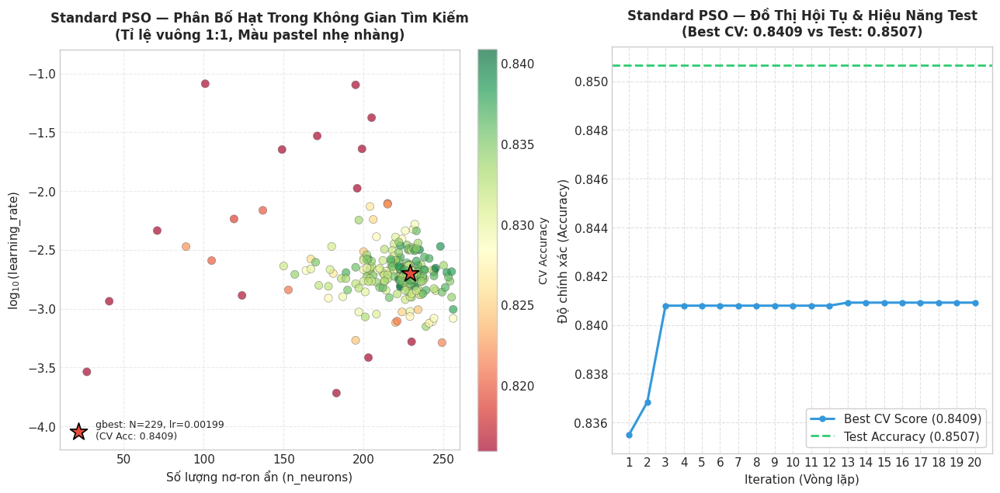

In [8]:
# Trực quan hóa Không gian tìm kiếm hạt (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_std['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_std['n_neurons'], np.log10(hist_std['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_std, np.log10(lr_std), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_std}, lr={lr_std:.5f}\n(CV Acc: {cv_std:.4f})'
)
ax_sc.set_box_aspect(1)
ax_sc.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_sc.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
ax_sc.set_title('Standard PSO — Hyperparameter Search Space Distribution\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_sc.set_xlim(10, 260)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.grid(True, linestyle='--', alpha=0.4)
ax_sc.legend(loc='lower left', fontsize=9, framealpha=0.92)

# 2. Đồ thị hội tụ qua các vòng lặp
ax_conv = fig.add_subplot(gs[0, 1])
iters = range(1, len(conv_std) + 1)
ax_conv.plot(iters, conv_std, marker='o', markersize=5, lw=2.2, color='#3498db', label=f'Best CV Score ({cv_std:.4f})')
ax_conv.axhline(test_std, color='#2ecc71', ls='--', lw=2.0, label=f'Test Accuracy ({test_std:.4f})')
ax_conv.set_xlabel('Iteration (Iteration)', fontsize=11)
ax_conv.set_ylabel('Accuracy (Accuracy)', fontsize=11)
ax_conv.set_title(f'Standard PSO — Convergence Trajectory & Generalization Performance\n(Best CV: {cv_std:.4f} vs Test: {test_std:.4f})', fontsize=12, fontweight='bold', pad=10)
ax_conv.set_xticks(list(iters))
ax_conv.grid(True, linestyle='--', alpha=0.6)
ax_conv.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.92)

plt.tight_layout()
plt.show()


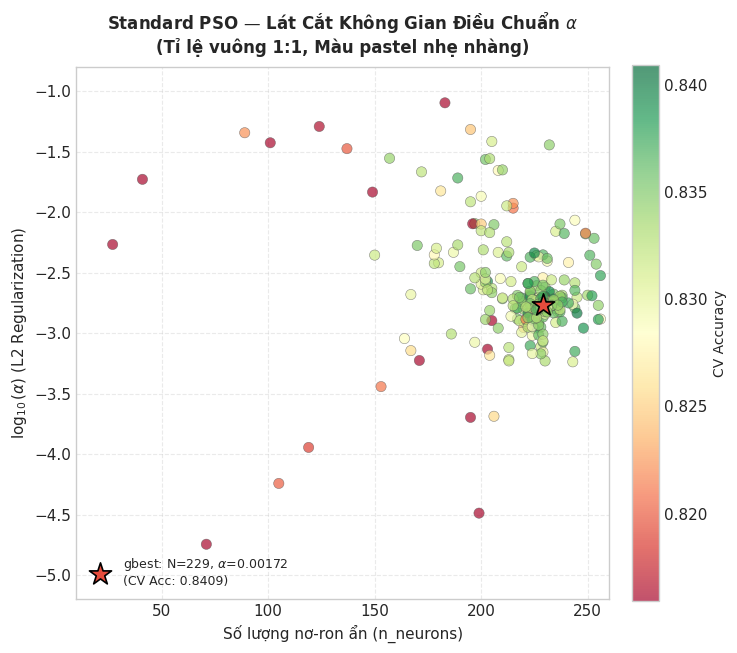

In [9]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization)
fig, ax_al = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al.scatter(
    hist_std['n_neurons'], np.log10(hist_std['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al.scatter(
    n_std, np.log10(al_std), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_std}, $\\alpha$={al_std:.5f}\n(CV Acc: {cv_std:.4f})'
)
ax_al.set_box_aspect(1)
ax_al.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_al.set_ylabel(r'$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al.set_title('Standard PSO — L2 Regularization Parameter Exploration Slice $\\alpha$\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_al.set_xlim(10, 260)
ax_al.set_ylim(-5.2, -0.8)
ax_al.grid(True, linestyle='--', alpha=0.4)
ax_al.legend(loc='lower left', fontsize=9, framealpha=0.92)

plt.tight_layout()
plt.show()


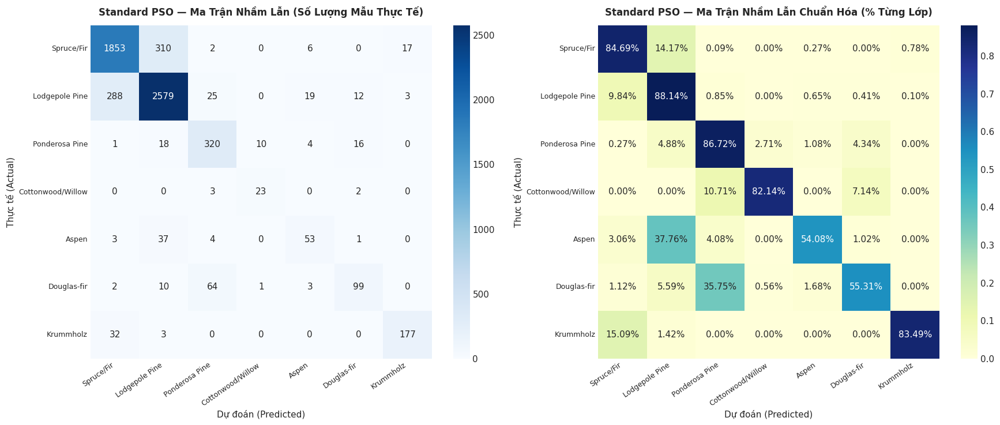

In [10]:
# Trực quan hoá Ma trận nhầm lẫn (Confusion Matrix): Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_std = mlp_std.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm = confusion_matrix(y_test, y_pred_std)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

# 1. Heatmap số lượng mẫu
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('Standard PSO — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm1.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm1.set_yticklabels(class_names, rotation=0, fontsize=9)

# 2. Heatmap tỷ lệ phần trăm chuẩn hóa
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='YlGnBu', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('Standard PSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm2.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm2.set_yticklabels(class_names, rotation=0, fontsize=9)

plt.tight_layout()
plt.show()


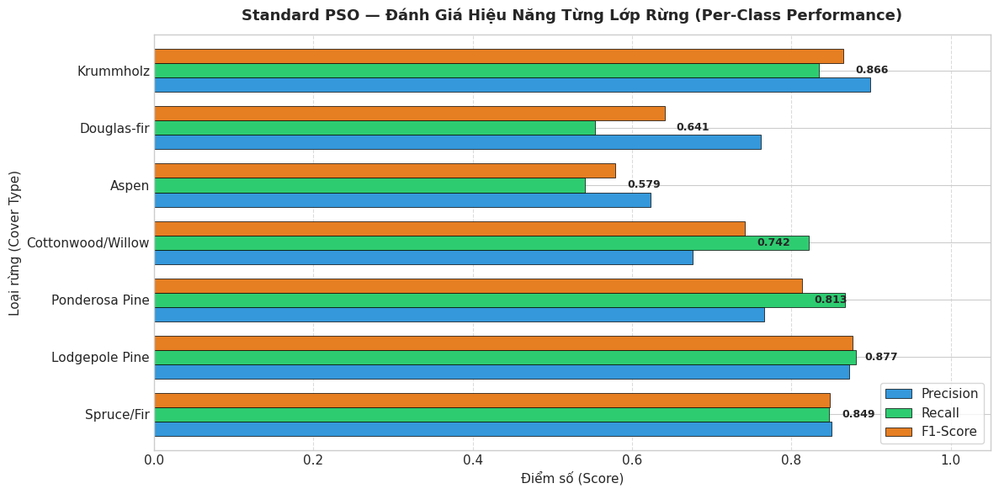


📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - Standard PSO:
                   precision    recall  f1-score   support

       Spruce/Fir     0.8504    0.8469    0.8486      2188
   Lodgepole Pine     0.8722    0.8814    0.8768      2926
   Ponderosa Pine     0.7656    0.8672    0.8132       369
Cottonwood/Willow     0.6765    0.8214    0.7419        28
            Aspen     0.6235    0.5408    0.5792        98
      Douglas-fir     0.7615    0.5531    0.6408       179
        Krummholz     0.8985    0.8349    0.8655       212

         accuracy                         0.8507      6000
        macro avg     0.7783    0.7637    0.7666      6000
     weighted avg     0.8503    0.8507    0.8497      6000



In [11]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng
report_dict = classification_report(y_test, y_pred_std, target_names=class_names, digits=4, output_dict=True)

metrics_df = pd.DataFrame({
    'Precision': [report_dict[c]['precision'] for c in class_names],
    'Recall': [report_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_df.plot(kind='barh', ax=ax_metrics, color=['#3498db', '#2ecc71', '#e67e22'], width=0.75, edgecolor='black', lw=0.5)

ax_metrics.set_title('Standard PSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_ylabel('Loại rừng (Cover Type)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.7)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white')

for i, (idx_name, row) in enumerate(metrics_df.iterrows()):
    ax_metrics.text(row['F1-Score'] + 0.015, i, f"{row['F1-Score']:.3f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - Standard PSO:")
print(classification_report(y_test, y_pred_std, target_names=class_names, digits=4))


---
## 🟢 2. Test và Trực Quan Hóa Thuật Toán Cải Tiến: Linear Decay PSO (PSO-LD)
Nạp kết quả tối ưu từ checkpoint `../results/checkpoints/linear_decay_pso.pkl`. Biến thể này sử dụng cơ chế giảm dần trọng số quán tính $w$ tuyến tính từ 0.9 về 0.4 qua 20 vòng lặp, giúp chuyển đổi mượt mà từ **Khám phá toàn cục (Global Exploration)** sang **Khai thác cục bộ tinh chỉnh (Local Exploitation)**.

In [12]:
ckpt_ld_path = '../results/checkpoints/linear_decay_pso.pkl'
if not os.path.exists(ckpt_ld_path):
    ckpt_ld_path = 'results/checkpoints/linear_decay_pso.pkl'

if os.path.exists(ckpt_ld_path):
    ld = joblib.load(ckpt_ld_path)
    gbest_ld   = ld['gbest_pos']
    cv_ld      = ld['cv_score']
    conv_ld    = ld['convergence']
    hist_ld    = pd.DataFrame(ld['history']) if isinstance(ld['history'], list) else ld['history']
    w_hist_ld  = ld.get('w_history', None)

    n_ld, lr_ld, al_ld = decode_position(gbest_ld)

    print('✅ Nạp thành công checkpoint Linear Decay PSO!')
    print(f'   Neurons={n_ld}, lr={lr_ld:.5f}, alpha={al_ld:.6f} | Best CV={cv_ld:.4f}')
else:
    print(f'⚠️ Chưa tìm thấy checkpoint tại: {ckpt_ld_path}')


✅ Nạp thành công checkpoint Linear Decay PSO!
   Neurons=256, lr=0.00180, alpha=0.016857 | Best CV=0.8407


In [13]:
# Đánh giá Test cho Linear Decay PSO
mlp_ld, test_ld = train_and_evaluate(
    n_ld, lr_ld, al_ld, 
    X_train_sc, y_train, X_test_sc, y_test, 
    RANDOM_SEED, 'PSO + Linear Decay', cv_score=cv_ld
)


  PSO + Linear Decay        Train Acc = 0.9412 | Test Acc = 0.8537 (85.37%) [54.2s]
✅ Đã lưu kết quả 'PSO + Linear Decay' (Test Acc: 0.8537) vào ../results/test_results/test_accuracy.csv


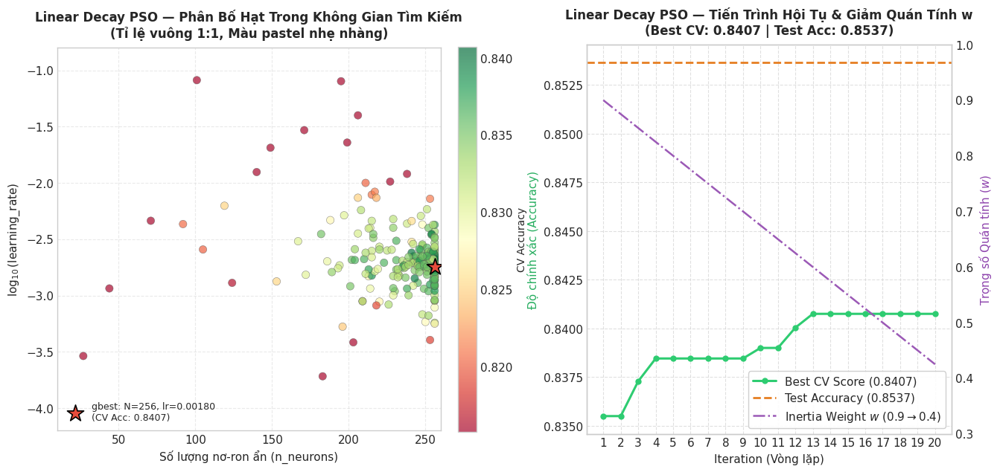

In [14]:
# Trực quan hóa Không gian tìm kiếm hạt Linear Decay PSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ + w(t)
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc_ld = fig.add_subplot(gs[0, 0])
scores_ld = hist_ld['score']
vmin_ld = max(float(np.percentile(scores_ld, 5)), float(scores_ld.max() - 0.025))
vmax_ld = float(scores_ld.max())

sc_ld = ax_sc_ld.scatter(
    hist_ld['n_neurons'], np.log10(hist_ld['lr']),
    c=scores_ld, cmap='RdYlGn', vmin=vmin_ld, vmax=vmax_ld,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_ld = plt.colorbar(sc_ld, ax=ax_sc_ld, fraction=0.046, pad=0.04)
cbar_ld.set_label('CV Accuracy', fontsize=10)

ax_sc_ld.scatter(
    n_ld, np.log10(lr_ld), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_ld}, lr={lr_ld:.5f}\n(CV Acc: {cv_ld:.4f})'
)
ax_sc_ld.set_box_aspect(1)
ax_sc_ld.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_sc_ld.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
ax_sc_ld.set_title('Linear Decay PSO — Hyperparameter Search Space Distribution\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_sc_ld.set_xlim(10, 260)
ax_sc_ld.set_ylim(-4.2, -0.8)
ax_sc_ld.grid(True, linestyle='--', alpha=0.4)
ax_sc_ld.legend(loc='lower left', fontsize=9, framealpha=0.92)

# 2. Đồ thị hội tụ & Trọng số quán tính w
ax_conv_ld = fig.add_subplot(gs[0, 1])
iters_ld = range(1, len(conv_ld) + 1)
l1 = ax_conv_ld.plot(iters_ld, conv_ld, marker='o', markersize=5, lw=2.2, color='#2ecc71', label=f'Best CV Score ({cv_ld:.4f})')
l2 = ax_conv_ld.axhline(test_ld, color='#e67e22', ls='--', lw=2.0, label=f'Test Accuracy ({test_ld:.4f})')
ax_conv_ld.set_xlabel('Iteration (Iteration)', fontsize=11)
ax_conv_ld.set_ylabel('Accuracy (Accuracy)', fontsize=11, color='#27ae60')
ax_conv_ld.set_title(f'Linear Decay PSO — Convergence Trajectory & Giảm Quán Tính w\n(Best CV: {cv_ld:.4f} | Test Acc: {test_ld:.4f})', fontsize=12, fontweight='bold', pad=10)
ax_conv_ld.set_xticks(list(iters_ld))
ax_conv_ld.grid(True, linestyle='--', alpha=0.6)

if w_hist_ld is not None:
    ax_w = ax_conv_ld.twinx()
    l3 = ax_w.plot(iters_ld, w_hist_ld, color='#9b59b6', ls='-.', lw=1.8, label=r'Inertia Weight $w$ ($0.9 \to 0.4$)')
    ax_w.set_ylabel(r'Trọng số Quán tính ($w$)', fontsize=11, color='#8e44ad')
    ax_w.set_ylim(0.3, 1.0)
    ax_w.grid(False)
    lines = l1 + [l2] + l3
else:
    lines = l1 + [l2]

labels = [l.get_label() for l in lines]
ax_conv_ld.legend(lines, labels, loc='lower right', frameon=True, facecolor='white', framealpha=0.92)

plt.tight_layout()
plt.show()


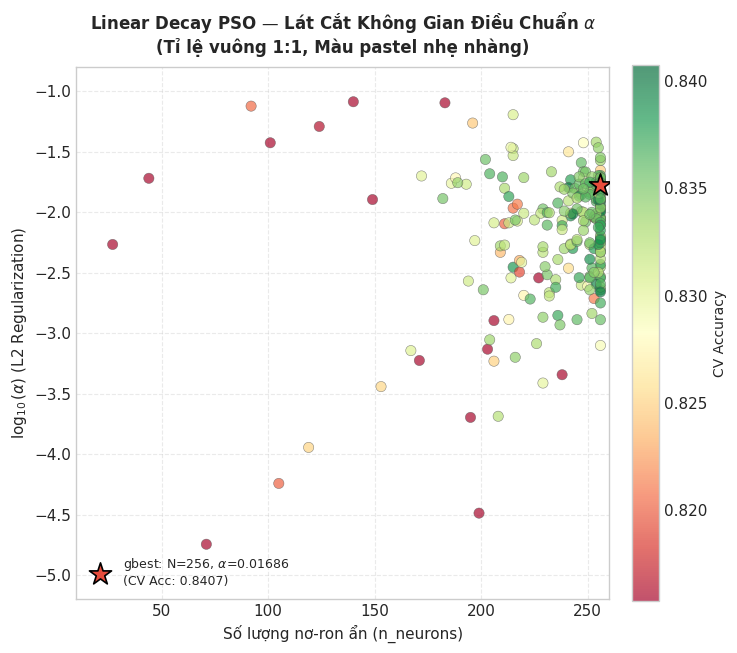

In [15]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - Linear Decay PSO
fig, ax_al_ld = plt.subplots(figsize=(7.5, 7.5))

sc_al_ld = ax_al_ld.scatter(
    hist_ld['n_neurons'], np.log10(hist_ld['alpha']),
    c=scores_ld, cmap='RdYlGn', vmin=vmin_ld, vmax=vmax_ld,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al_ld = plt.colorbar(sc_al_ld, ax=ax_al_ld, fraction=0.046, pad=0.04)
cbar_al_ld.set_label('CV Accuracy', fontsize=10)

ax_al_ld.scatter(
    n_ld, np.log10(al_ld), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_ld}, $\\alpha$={al_ld:.5f}\n(CV Acc: {cv_ld:.4f})'
)
ax_al_ld.set_box_aspect(1)
ax_al_ld.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_al_ld.set_ylabel(r'$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_ld.set_title('Linear Decay PSO — L2 Regularization Parameter Exploration Slice $\\alpha$\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_al_ld.set_xlim(10, 260)
ax_al_ld.set_ylim(-5.2, -0.8)
ax_al_ld.grid(True, linestyle='--', alpha=0.4)
ax_al_ld.legend(loc='lower left', fontsize=9, framealpha=0.92)

plt.tight_layout()
plt.show()


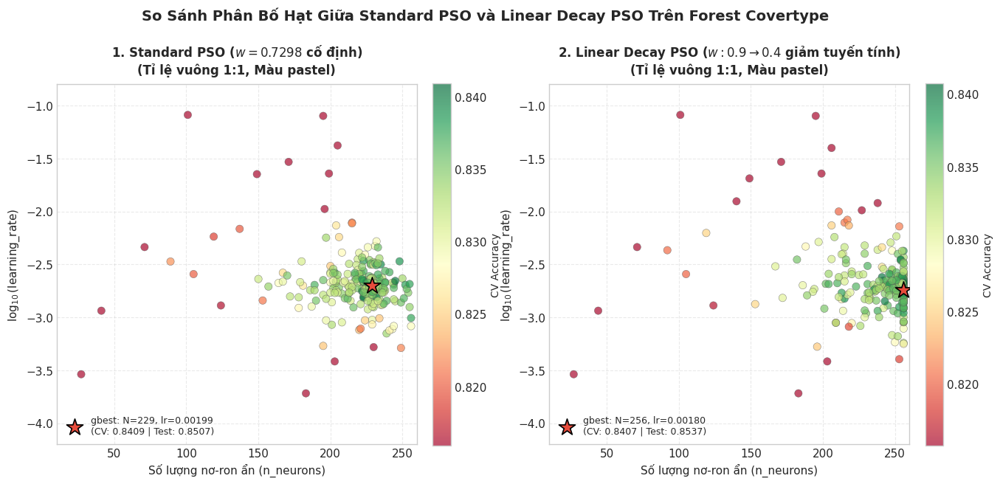

In [16]:
# BIỂU ĐỒ ĐỐI SÁNH: Phân bố hạt giữa Standard PSO và Linear Decay PSO (Tỉ lệ vuông 1:1)
fig_cmp = plt.figure(figsize=(15.5, 7.2))
gs_cmp = gridspec.GridSpec(1, 2, figure=fig_cmp, wspace=0.25)

# 1. Standard PSO
ax_cmp1 = fig_cmp.add_subplot(gs_cmp[0, 0])
sc1 = ax_cmp1.scatter(
    hist_std['n_neurons'], np.log10(hist_std['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar1 = plt.colorbar(sc1, ax=ax_cmp1, fraction=0.046, pad=0.04)
cbar1.set_label('CV Accuracy', fontsize=10)

ax_cmp1.scatter(
    n_std, np.log10(lr_std), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_std}, lr={lr_std:.5f}\n(CV: {cv_std:.4f} | Test: {test_std:.4f})'
)
ax_cmp1.set_box_aspect(1)
ax_cmp1.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_cmp1.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
ax_cmp1.set_title('1. Standard PSO ($w=0.7298$ cố định)\n(1:1 Square Ratio, RdYlGn Colormap)', fontsize=12, fontweight='bold', pad=10)
ax_cmp1.set_xlim(10, 260)
ax_cmp1.set_ylim(-4.2, -0.8)
ax_cmp1.grid(True, linestyle='--', alpha=0.4)
ax_cmp1.legend(loc='lower left', fontsize=9, framealpha=0.92)

# 2. Linear Decay PSO
ax_cmp2 = fig_cmp.add_subplot(gs_cmp[0, 1])
sc2 = ax_cmp2.scatter(
    hist_ld['n_neurons'], np.log10(hist_ld['lr']),
    c=scores_ld, cmap='RdYlGn', vmin=vmin_ld, vmax=vmax_ld,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar2 = plt.colorbar(sc2, ax=ax_cmp2, fraction=0.046, pad=0.04)
cbar2.set_label('CV Accuracy', fontsize=10)

ax_cmp2.scatter(
    n_ld, np.log10(lr_ld), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_ld}, lr={lr_ld:.5f}\n(CV: {cv_ld:.4f} | Test: {test_ld:.4f})'
)
ax_cmp2.set_box_aspect(1)
ax_cmp2.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_cmp2.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
ax_cmp2.set_title(r'2. Linear Decay PSO ($w: 0.9 \to 0.4$ giảm tuyến tính)' + '\n(1:1 Square Ratio, RdYlGn Colormap)', fontsize=12, fontweight='bold', pad=10)
ax_cmp2.set_xlim(10, 260)
ax_cmp2.set_ylim(-4.2, -0.8)
ax_cmp2.grid(True, linestyle='--', alpha=0.4)
ax_cmp2.legend(loc='lower left', fontsize=9, framealpha=0.92)

fig_cmp.suptitle('So Sánh Phân Bố Hạt Giữa Standard PSO và Linear Decay PSO Trên Forest Covertype', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


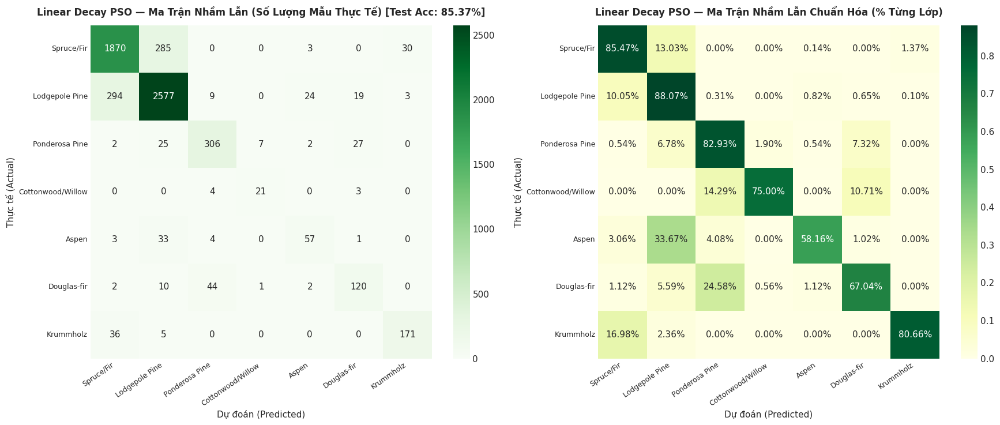

In [17]:
# Trực quan hoá Ma trận nhầm lẫn Linear Decay PSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_ld = mlp_ld.predict(X_test_sc)

cm_ld = confusion_matrix(y_test, y_pred_ld)
cm_ld_norm = cm_ld.astype('float') / cm_ld.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

# 1. Heatmap số lượng mẫu
sns.heatmap(cm_ld, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title(f'Linear Decay PSO — Confusion Matrix (Absolute Sample Counts) [Test Acc: {test_ld*100:.2f}%]', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm1.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm1.set_yticklabels(class_names, rotation=0, fontsize=9)

# 2. Heatmap tỷ lệ phần trăm chuẩn hóa
sns.heatmap(cm_ld_norm, annot=True, fmt='.2%', cmap='YlGn', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('Linear Decay PSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm2.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm2.set_yticklabels(class_names, rotation=0, fontsize=9)

plt.tight_layout()
plt.show()


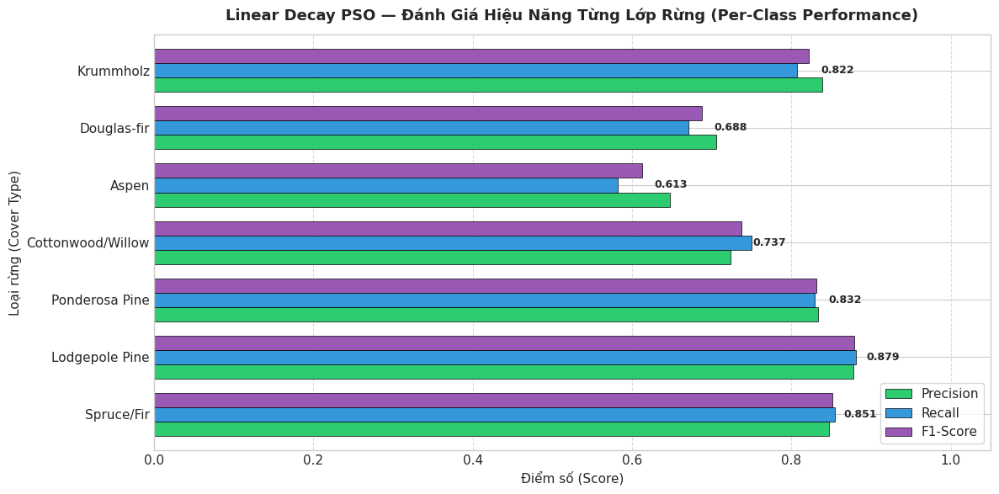


📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - Linear Decay PSO:
                   precision    recall  f1-score   support

       Spruce/Fir     0.8473    0.8547    0.8510      2188
   Lodgepole Pine     0.8780    0.8807    0.8794      2926
   Ponderosa Pine     0.8338    0.8293    0.8315       369
Cottonwood/Willow     0.7241    0.7500    0.7368        28
            Aspen     0.6477    0.5816    0.6129        98
      Douglas-fir     0.7059    0.6704    0.6877       179
        Krummholz     0.8382    0.8066    0.8221       212

         accuracy                         0.8537      6000
        macro avg     0.7822    0.7676    0.7745      6000
     weighted avg     0.8531    0.8537    0.8533      6000



In [18]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho Linear Decay PSO
report_ld_dict = classification_report(y_test, y_pred_ld, target_names=class_names, digits=4, output_dict=True)

metrics_ld_df = pd.DataFrame({
    'Precision': [report_ld_dict[c]['precision'] for c in class_names],
    'Recall': [report_ld_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_ld_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics_ld = plt.subplots(figsize=(12, 6))
metrics_ld_df.plot(kind='barh', ax=ax_metrics_ld, color=['#2ecc71', '#3498db', '#9b59b6'], width=0.75, edgecolor='black', lw=0.5)

ax_metrics_ld.set_title('Linear Decay PSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics_ld.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics_ld.set_ylabel('Loại rừng (Cover Type)', fontsize=11)
ax_metrics_ld.set_xlim(0, 1.05)
ax_metrics_ld.grid(True, axis='x', linestyle='--', alpha=0.7)
ax_metrics_ld.legend(loc='lower right', frameon=True, facecolor='white')

for i, (idx_name, row) in enumerate(metrics_ld_df.iterrows()):
    ax_metrics_ld.text(row['F1-Score'] + 0.015, i, f"{row['F1-Score']:.3f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - Linear Decay PSO:")
print(classification_report(y_test, y_pred_ld, target_names=class_names, digits=4))


---
## 🟡 3. Test và Trực Quan Hóa Thuật Toán Cải Tiến: Fitness Averaging PSO (PSO-FA)
Nạp kết quả tối ưu từ checkpoint `../results/checkpoints/fitness_avg_pso.pkl` (được tối ưu hóa thông qua cơ chế lấy trung bình $k=3$ lần chạy hàm thích nghi để triệt tiêu nhiễu khởi tạo trọng số ngẫu nhiên), huấn luyện mô hình MLP trên toàn bộ tập Train (24,000 mẫu) và đánh giá khách quan trên tập Test (6,000 mẫu).

In [21]:
ckpt_fa_path = '../results/checkpoints/fitness_avg_pso.pkl'
if not os.path.exists(ckpt_fa_path):
    ckpt_fa_path = 'results/checkpoints/fitness_avg_pso.pkl'

if os.path.exists(ckpt_fa_path):
    fa = joblib.load(ckpt_fa_path)
    gbest_fa   = fa['gbest_pos']
    cv_fa      = fa['cv_score']
    conv_fa    = fa['convergence']
    hist_fa    = pd.DataFrame(fa['history']) if isinstance(fa['history'], list) else fa['history']

    n_fa, lr_fa, al_fa = decode_position(gbest_fa)

    print('✅ Nạp thành công checkpoint Fitness Averaging PSO!')
    print(f'   Neurons={n_fa}, lr={lr_fa:.5f}, alpha={al_fa:.6f} | Best CV={cv_fa:.4f}')
else:
    print(f'⚠️ Chưa tìm thấy checkpoint tại: {ckpt_fa_path}')


✅ Nạp thành công checkpoint Fitness Averaging PSO!
   Neurons=217, lr=0.00251, alpha=0.050501 | Best CV=0.8019


In [22]:
# Đánh giá Test cho Fitness Averaging PSO
mlp_fa, test_fa = train_and_evaluate(
    n_fa, lr_fa, al_fa, 
    X_train_sc, y_train, X_test_sc, y_test, 
    RANDOM_SEED, 'PSO + Fitness Avg', cv_score=cv_fa
)


  PSO + Fitness Avg         Train Acc = 0.8679 | Test Acc = 0.8497 (84.97%) [44.7s]
✅ Đã lưu kết quả 'PSO + Fitness Avg' (Test Acc: 0.8497) vào ../results/test_results/test_accuracy.csv


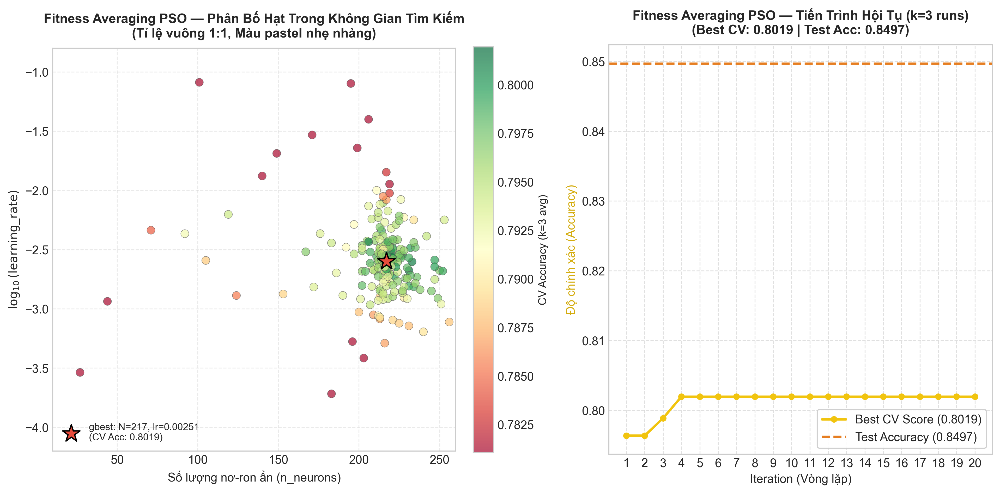

In [23]:
# Đảm bảo có giá trị test_fa nếu chưa chạy qua cell huấn luyện
if 'test_fa' not in locals():
    try:
        df_res = pd.read_csv(RESULT_CSV_PATH)
        row = df_res[df_res['Algorithm'].str.contains('Fitness Avg', case=False, na=False)]
        test_fa = float(row.iloc[0]['Test_Accuracy']) if not row.empty else cv_fa
    except Exception:
        test_fa = cv_fa

# Trực quan hóa Không gian tìm kiếm hạt Fitness Averaging PSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc_fa = fig.add_subplot(gs[0, 0])
scores_fa = hist_fa['score']
vmin_fa = max(float(np.percentile(scores_fa, 5)), float(scores_fa.max() - 0.025))
vmax_fa = float(scores_fa.max())

sc_fa = ax_sc_fa.scatter(
    hist_fa['n_neurons'], np.log10(hist_fa['lr']),
    c=scores_fa, cmap='RdYlGn', vmin=vmin_fa, vmax=vmax_fa,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_fa = plt.colorbar(sc_fa, ax=ax_sc_fa, fraction=0.046, pad=0.04)
cbar_fa.set_label('CV Accuracy (k=3 avg)', fontsize=10)

ax_sc_fa.scatter(
    n_fa, np.log10(lr_fa), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_fa}, lr={lr_fa:.5f}\n(CV Acc: {cv_fa:.4f})'
)
ax_sc_fa.set_box_aspect(1)
ax_sc_fa.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_sc_fa.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
ax_sc_fa.set_title('Fitness Averaging PSO — Hyperparameter Search Space Distribution\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_sc_fa.set_xlim(10, 260)
ax_sc_fa.set_ylim(-4.2, -0.8)
ax_sc_fa.grid(True, linestyle='--', alpha=0.4)
ax_sc_fa.legend(loc='lower left', fontsize=9, framealpha=0.92)

# 2. Đồ thị hội tụ
ax_conv_fa = fig.add_subplot(gs[0, 1])
iters_fa = range(1, len(conv_fa) + 1)
ax_conv_fa.plot(iters_fa, conv_fa, marker='o', markersize=5, lw=2.2, color='#f1c40f', label=f'Best CV Score ({cv_fa:.4f})')
ax_conv_fa.axhline(test_fa, color='#e67e22', ls='--', lw=2.0, label=f'Test Accuracy ({test_fa:.4f})')
ax_conv_fa.set_xlabel('Iteration (Iteration)', fontsize=11)
ax_conv_fa.set_ylabel('Accuracy (Accuracy)', fontsize=11, color='#d4ac0d')
ax_conv_fa.set_title(f'Fitness Averaging PSO — Convergence Trajectory (k=3 runs)\n(Best CV: {cv_fa:.4f} | Test Acc: {test_fa:.4f})', fontsize=12, fontweight='bold', pad=10)
ax_conv_fa.set_xticks(list(iters_fa))
ax_conv_fa.grid(True, linestyle='--', alpha=0.6)
ax_conv_fa.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.92)

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_fa_scatter_convergence.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()


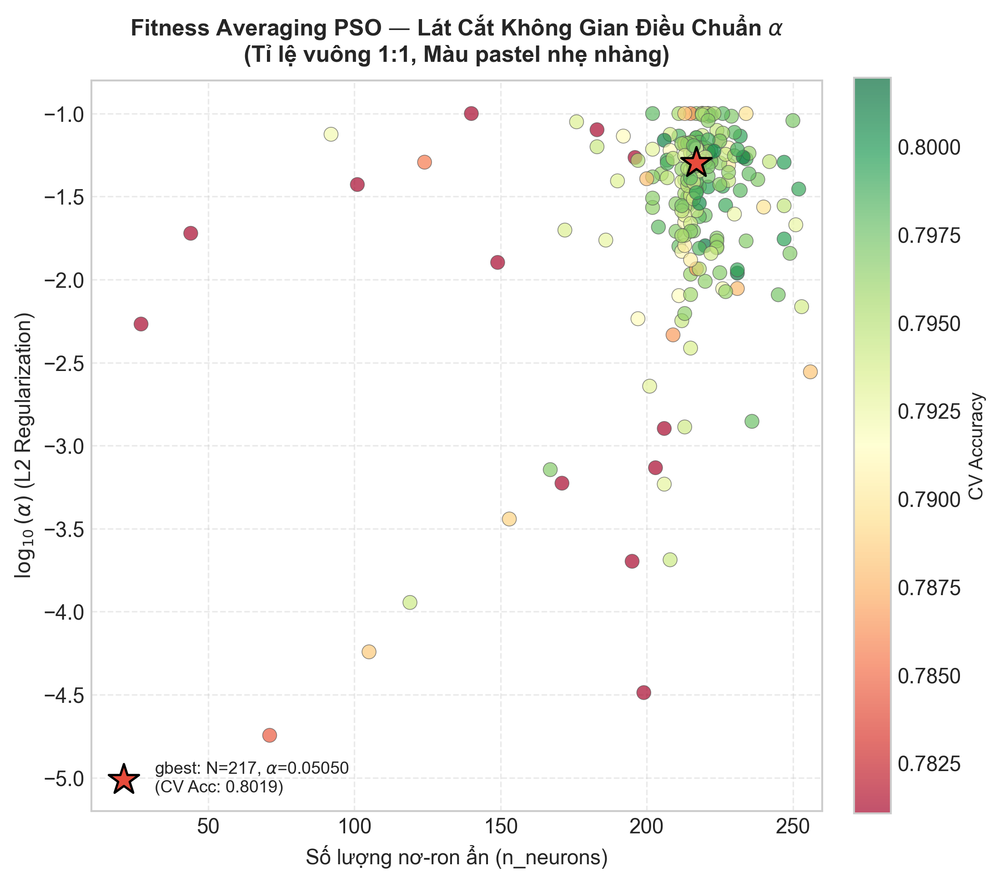

In [24]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - Fitness Averaging PSO
fig, ax_al_fa = plt.subplots(figsize=(7.5, 7.5))

sc_al_fa = ax_al_fa.scatter(
    hist_fa['n_neurons'], np.log10(hist_fa['alpha']),
    c=scores_fa, cmap='RdYlGn', vmin=vmin_fa, vmax=vmax_fa,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al_fa = plt.colorbar(sc_al_fa, ax=ax_al_fa, fraction=0.046, pad=0.04)
cbar_al_fa.set_label('CV Accuracy', fontsize=10)

ax_al_fa.scatter(
    n_fa, np.log10(al_fa), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_fa}, $\\alpha$={al_fa:.5f}\n(CV Acc: {cv_fa:.4f})'
)
ax_al_fa.set_box_aspect(1)
ax_al_fa.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_al_fa.set_ylabel(r'$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_fa.set_title('Fitness Averaging PSO — L2 Regularization Parameter Exploration Slice $\\alpha$\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_al_fa.set_xlim(10, 260)
ax_al_fa.set_ylim(-5.2, -0.8)
ax_al_fa.grid(True, linestyle='--', alpha=0.4)
ax_al_fa.legend(loc='lower left', fontsize=9, framealpha=0.92)

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_fa_alpha_scatter.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()


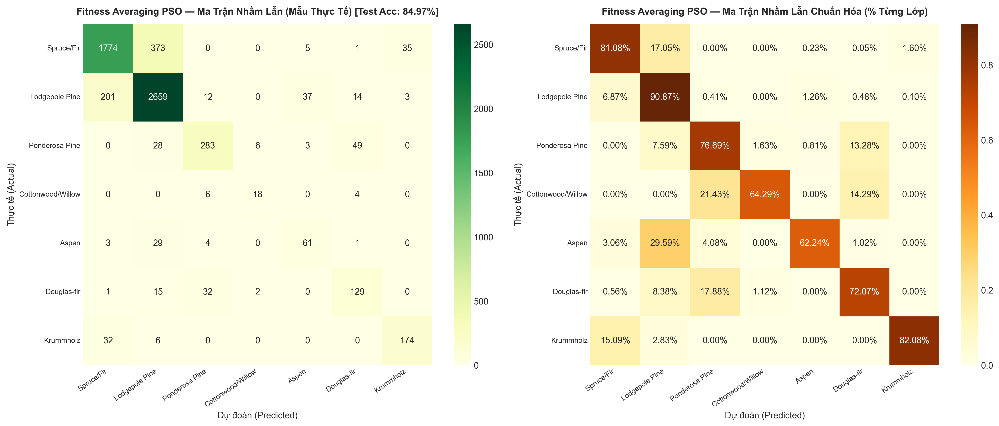

In [25]:
# Trực quan hoá Ma trận nhầm lẫn Fitness Averaging PSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_fa = mlp_fa.predict(X_test_sc)

cm_fa = confusion_matrix(y_test, y_pred_fa)
cm_fa_norm = cm_fa.astype('float') / cm_fa.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

# 1. Heatmap số lượng mẫu
sns.heatmap(cm_fa, annot=True, fmt='d', cmap='YlGn', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title(f'Fitness Averaging PSO — Confusion Matrix (Absolute Sample Counts) [Test Acc: {test_fa*100:.2f}%]', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm1.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm1.set_yticklabels(class_names, rotation=0, fontsize=9)

# 2. Heatmap tỷ lệ phần trăm chuẩn hóa
sns.heatmap(cm_fa_norm, annot=True, fmt='.2%', cmap='YlOrBr', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('Fitness Averaging PSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm2.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm2.set_yticklabels(class_names, rotation=0, fontsize=9)

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_fa_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()


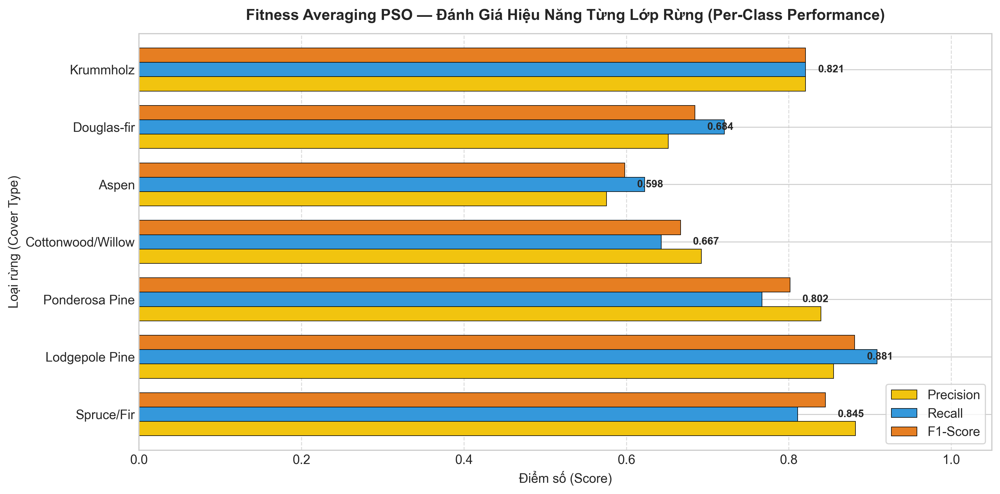

In [26]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho Fitness Averaging PSO
report_fa_dict = classification_report(y_test, y_pred_fa, target_names=class_names, digits=4, output_dict=True)

metrics_fa_df = pd.DataFrame({
    'Precision': [report_fa_dict[c]['precision'] for c in class_names],
    'Recall': [report_fa_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_fa_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics_fa = plt.subplots(figsize=(12, 6))
metrics_fa_df.plot(kind='barh', ax=ax_metrics_fa, color=['#f1c40f', '#3498db', '#e67e22'], width=0.75, edgecolor='black', lw=0.5)

ax_metrics_fa.set_title('Fitness Averaging PSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics_fa.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics_fa.set_ylabel('Loại rừng (Cover Type)', fontsize=11)
ax_metrics_fa.set_xlim(0, 1.05)
ax_metrics_fa.grid(True, axis='x', linestyle='--', alpha=0.7)
ax_metrics_fa.legend(loc='lower right', frameon=True, facecolor='white')

for i, (idx_name, row) in enumerate(metrics_fa_df.iterrows()):
    ax_metrics_fa.text(row['F1-Score'] + 0.015, i, f"{row['F1-Score']:.3f}", va='center', fontsize=9, fontweight='bold')

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_fa_per_class_metrics.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

print("\n📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - Fitness Averaging PSO:")
print(classification_report(y_test, y_pred_fa, target_names=class_names, digits=4))


---
## 🟠 4. Test và Trực Quan Hóa Thuật Toán Cải Tiến: Constriction-type PSO (CPSO)
Nạp kết quả tối ưu từ checkpoint `../results/checkpoints/cpso.pkl` (sử dụng hệ số co hẹp Clerc & Kennedy $K \approx 0.730$ để đảm bảo hội tụ toán học chặt chẽ), huấn luyện mô hình MLP trên toàn bộ tập Train (24,000 mẫu) và đánh giá khách quan trên tập Test (6,000 mẫu).

In [27]:
ckpt_cp_path = '../results/checkpoints/cpso.pkl'
if not os.path.exists(ckpt_cp_path):
    ckpt_cp_path = 'results/checkpoints/cpso.pkl'

if os.path.exists(ckpt_cp_path):
    cp = joblib.load(ckpt_cp_path)
    gbest_cp   = cp['gbest_pos']
    cv_cp      = cp['cv_score']
    conv_cp    = cp['convergence']
    hist_cp    = pd.DataFrame(cp['history']) if isinstance(cp['history'], list) else cp['history']
    K_val      = cp.get('K_val', 0.7298)

    n_cp, lr_cp, al_cp = decode_position(gbest_cp)

    print('✅ Nạp thành công checkpoint CPSO!')
    print(f'   Neurons={n_cp}, lr={lr_cp:.5f}, alpha={al_cp:.6f}, K={K_val:.3f} | Best CV={cv_cp:.4f}')
else:
    print(f'⚠️ Chưa tìm thấy checkpoint tại: {ckpt_cp_path}')


✅ Nạp thành công checkpoint CPSO!
   Neurons=234, lr=0.00265, alpha=0.008462, K=0.730 | Best CV=0.8068


In [28]:
# Đánh giá Test cho CPSO
mlp_cp, test_cp = train_and_evaluate(
    n_cp, lr_cp, al_cp, 
    X_train_sc, y_train, X_test_sc, y_test, 
    RANDOM_SEED, 'CPSO', cv_score=cv_cp
)


  CPSO                      Train Acc = 0.8654 | Test Acc = 0.8473 (84.73%) [31.9s]
✅ Đã lưu kết quả 'CPSO' (Test Acc: 0.8473) vào ../results/test_results/test_accuracy.csv


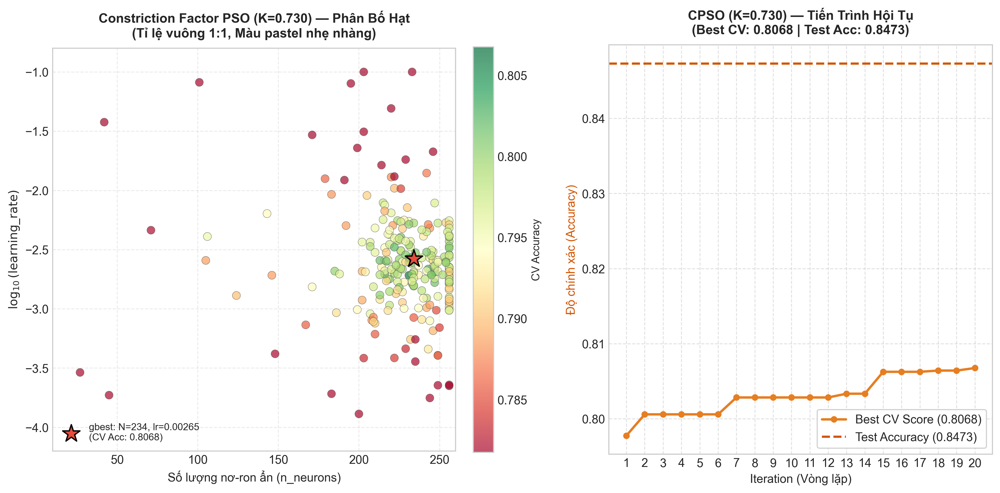

In [29]:
# Đảm bảo có giá trị test_cp nếu chưa chạy qua cell huấn luyện
if 'test_cp' not in locals():
    try:
        df_res = pd.read_csv(RESULT_CSV_PATH)
        row = df_res[df_res['Algorithm'].str.contains('CPSO', case=False, na=False)]
        test_cp = float(row.iloc[0]['Test_Accuracy']) if not row.empty else cv_cp
    except Exception:
        test_cp = cv_cp

# Trực quan hóa Không gian tìm kiếm hạt CPSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc_cp = fig.add_subplot(gs[0, 0])
scores_cp = hist_cp['score']
vmin_cp = max(float(np.percentile(scores_cp, 5)), float(scores_cp.max() - 0.025))
vmax_cp = float(scores_cp.max())

sc_cp = ax_sc_cp.scatter(
    hist_cp['n_neurons'], np.log10(hist_cp['lr']),
    c=scores_cp, cmap='RdYlGn', vmin=vmin_cp, vmax=vmax_cp,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_cp = plt.colorbar(sc_cp, ax=ax_sc_cp, fraction=0.046, pad=0.04)
cbar_cp.set_label('CV Accuracy', fontsize=10)

ax_sc_cp.scatter(
    n_cp, np.log10(lr_cp), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_cp}, lr={lr_cp:.5f}\n(CV Acc: {cv_cp:.4f})'
)
ax_sc_cp.set_box_aspect(1)
ax_sc_cp.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_sc_cp.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
ax_sc_cp.set_title(f'Constriction Factor PSO (K={K_val:.3f}) — Phân Bố Hạt\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_sc_cp.set_xlim(10, 260)
ax_sc_cp.set_ylim(-4.2, -0.8)
ax_sc_cp.grid(True, linestyle='--', alpha=0.4)
ax_sc_cp.legend(loc='lower left', fontsize=9, framealpha=0.92)

# 2. Đồ thị hội tụ
ax_conv_cp = fig.add_subplot(gs[0, 1])
iters_cp = range(1, len(conv_cp) + 1)
ax_conv_cp.plot(iters_cp, conv_cp, marker='o', markersize=5, lw=2.2, color='#e67e22', label=f'Best CV Score ({cv_cp:.4f})')
ax_conv_cp.axhline(test_cp, color='#d35400', ls='--', lw=2.0, label=f'Test Accuracy ({test_cp:.4f})')
ax_conv_cp.set_xlabel('Iteration (Iteration)', fontsize=11)
ax_conv_cp.set_ylabel('Accuracy (Accuracy)', fontsize=11, color='#d35400')
ax_conv_cp.set_title(f'CPSO (K={K_val:.3f}) — Convergence Trajectory\n(Best CV: {cv_cp:.4f} | Test Acc: {test_cp:.4f})', fontsize=12, fontweight='bold', pad=10)
ax_conv_cp.set_xticks(list(iters_cp))
ax_conv_cp.grid(True, linestyle='--', alpha=0.6)
ax_conv_cp.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.92)

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_cp_scatter_convergence.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()


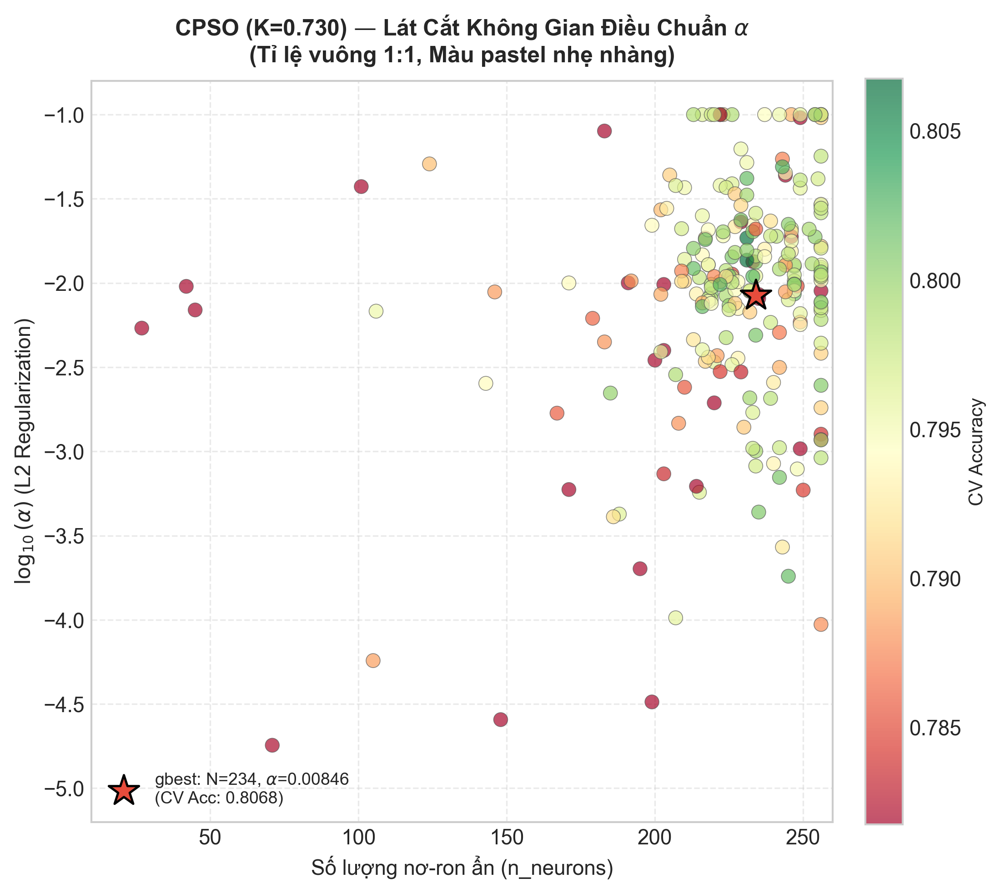

In [30]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - CPSO
fig, ax_al_cp = plt.subplots(figsize=(7.5, 7.5))

sc_al_cp = ax_al_cp.scatter(
    hist_cp['n_neurons'], np.log10(hist_cp['alpha']),
    c=scores_cp, cmap='RdYlGn', vmin=vmin_cp, vmax=vmax_cp,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al_cp = plt.colorbar(sc_al_cp, ax=ax_al_cp, fraction=0.046, pad=0.04)
cbar_al_cp.set_label('CV Accuracy', fontsize=10)

ax_al_cp.scatter(
    n_cp, np.log10(al_cp), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_cp}, $\\alpha$={al_cp:.5f}\n(CV Acc: {cv_cp:.4f})'
)
ax_al_cp.set_box_aspect(1)
ax_al_cp.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_al_cp.set_ylabel(r'$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_cp.set_title(f'CPSO (K={K_val:.3f}) — L2 Regularization Parameter Exploration Slice $\\alpha$\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_al_cp.set_xlim(10, 260)
ax_al_cp.set_ylim(-5.2, -0.8)
ax_al_cp.grid(True, linestyle='--', alpha=0.4)
ax_al_cp.legend(loc='lower left', fontsize=9, framealpha=0.92)

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_cp_alpha_scatter.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()


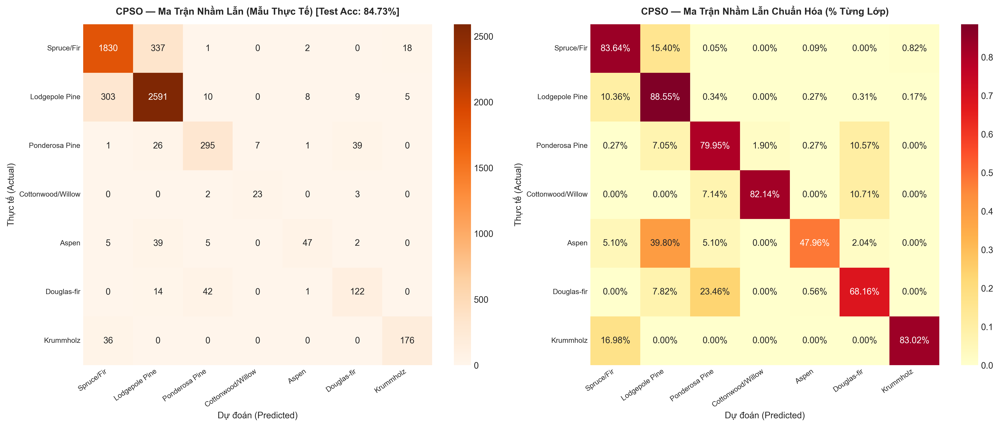

In [31]:
# Trực quan hoá Ma trận nhầm lẫn CPSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_cp = mlp_cp.predict(X_test_sc)

cm_cp = confusion_matrix(y_test, y_pred_cp)
cm_cp_norm = cm_cp.astype('float') / cm_cp.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

# 1. Heatmap số lượng mẫu
sns.heatmap(cm_cp, annot=True, fmt='d', cmap='Oranges', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title(f'CPSO — Confusion Matrix (Absolute Sample Counts) [Test Acc: {test_cp*100:.2f}%]', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm1.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm1.set_yticklabels(class_names, rotation=0, fontsize=9)

# 2. Heatmap tỷ lệ phần trăm chuẩn hóa
sns.heatmap(cm_cp_norm, annot=True, fmt='.2%', cmap='YlOrRd', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('CPSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm2.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm2.set_yticklabels(class_names, rotation=0, fontsize=9)

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_cp_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()


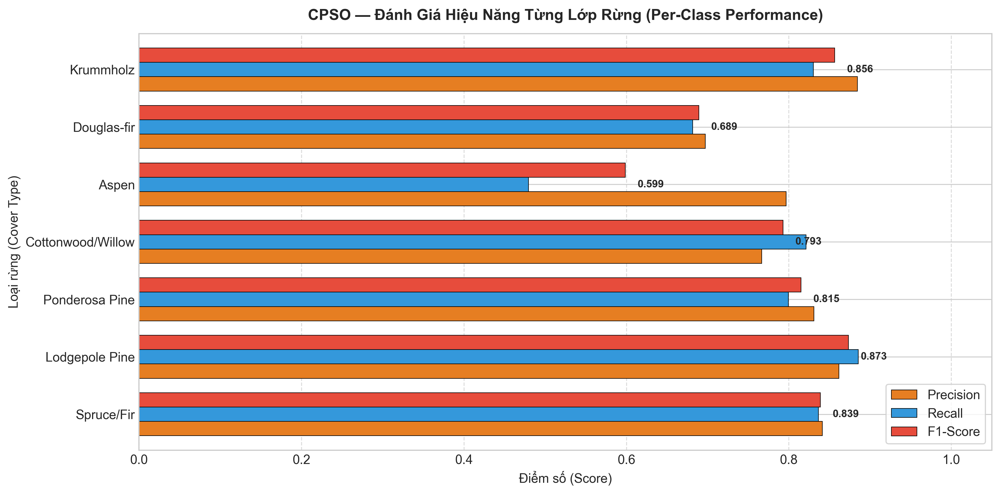

In [32]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho CPSO
report_cp_dict = classification_report(y_test, y_pred_cp, target_names=class_names, digits=4, output_dict=True)

metrics_cp_df = pd.DataFrame({
    'Precision': [report_cp_dict[c]['precision'] for c in class_names],
    'Recall': [report_cp_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_cp_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics_cp = plt.subplots(figsize=(12, 6))
metrics_cp_df.plot(kind='barh', ax=ax_metrics_cp, color=['#e67e22', '#3498db', '#e74c3c'], width=0.75, edgecolor='black', lw=0.5)

ax_metrics_cp.set_title('CPSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics_cp.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics_cp.set_ylabel('Loại rừng (Cover Type)', fontsize=11)
ax_metrics_cp.set_xlim(0, 1.05)
ax_metrics_cp.grid(True, axis='x', linestyle='--', alpha=0.7)
ax_metrics_cp.legend(loc='lower right', frameon=True, facecolor='white')

for i, (idx_name, row) in enumerate(metrics_cp_df.iterrows()):
    ax_metrics_cp.text(row['F1-Score'] + 0.015, i, f"{row['F1-Score']:.3f}", va='center', fontsize=9, fontweight='bold')

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_cp_per_class_metrics.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

print("\n📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - CPSO:")
print(classification_report(y_test, y_pred_cp, target_names=class_names, digits=4))


---
## 🟣 5. Test và Trực Quan Hóa Thuật Toán Cải Tiến: Fractional-Order PSO (FO-PSO)
Nạp kết quả tối ưu từ checkpoint `fopso.pkl` (được tối ưu hóa bằng thuật toán FO-PSO với chuỗi nhớ bậc phân số $r=4, \alpha=0.6$), tiến hành huấn luyện mô hình MLPClassifier trên toàn bộ tập Train và kiểm thử độc lập trên tập Test.

In [18]:
ckpt_fo_path = '../results/checkpoints/fopso.pkl'
if not os.path.exists(ckpt_fo_path):
    ckpt_fo_path = 'results/checkpoints/fopso.pkl'

if os.path.exists(ckpt_fo_path):
    fo = joblib.load(ckpt_fo_path)
    gbest_fo   = fo['gbest_pos']
    cv_fo      = fo['cv_score']
    conv_fo    = fo['convergence']
    hist_fo    = pd.DataFrame(fo['history']) if isinstance(fo['history'], list) else fo['history']

    n_fo, lr_fo, al_fo = decode_position(gbest_fo)

    print('✅ Nạp thành công checkpoint FO-PSO!')
    print(f'   Neurons={n_fo}, lr={lr_fo:.5f}, alpha={al_fo:.6f} | Best CV={cv_fo:.4f}')
else:
    print(f'⚠️ Chưa tìm thấy checkpoint tại: {ckpt_fo_path}')


✅ Nạp thành công checkpoint FO-PSO!
   Neurons=212, lr=0.00233, alpha=0.01168 | Best CV=0.8395


In [19]:
# Đánh giá Test cho FO-PSO
mlp_fo, test_fo = train_and_evaluate(
    n_fo, lr_fo, al_fo, 
    X_train_sc, y_train, X_test_sc, y_test, 
    RANDOM_SEED, 'FO-PSO', cv_score=cv_fo
)


  FO-PSO                    Train Acc = 0.9423 | Test Acc = 0.8535 (85.35%) [55.0s]
📁 Đã cập nhật kết quả vào: ../results/test_results/test_accuracy.csv


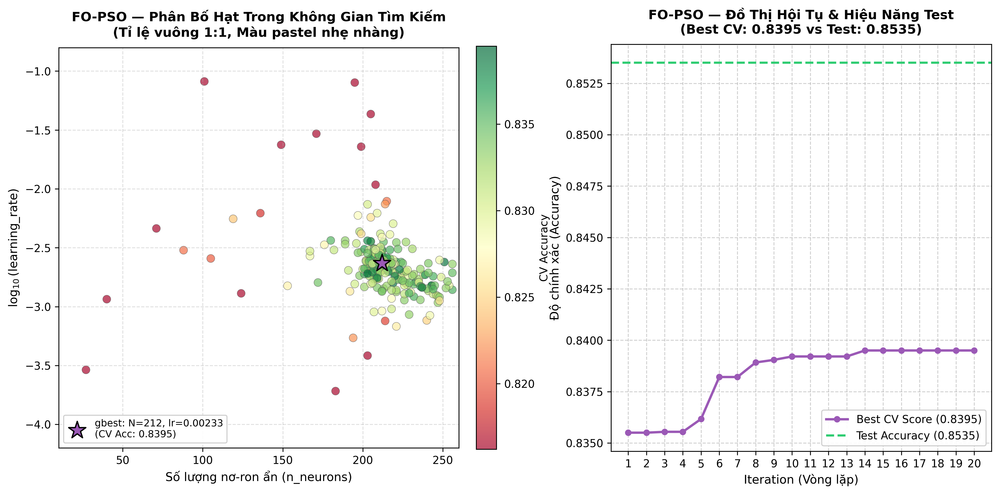

In [20]:
# Trực quan hóa Không gian tìm kiếm hạt FO-PSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_fo['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_fo['n_neurons'], np.log10(hist_fo['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_fo, np.log10(lr_fo), c='#9b59b6', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_fo}, lr={lr_fo:.5f}\n(CV Acc: {cv_fo:.4f})'
)
ax_sc.set_box_aspect(1)
ax_sc.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_sc.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
ax_sc.set_title('FO-PSO — Hyperparameter Search Space Distribution\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_sc.set_xlim(10, 260)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.grid(True, linestyle='--', alpha=0.4)
ax_sc.legend(loc='lower left', fontsize=9, framealpha=0.92)

# 2. Đồ thị hội tụ qua các vòng lặp
ax_conv = fig.add_subplot(gs[0, 1])
iters = range(1, len(conv_fo) + 1)
ax_conv.plot(iters, conv_fo, marker='o', markersize=5, lw=2.2, color='#9b59b6', label=f'Best CV Score ({cv_fo:.4f})')
ax_conv.axhline(test_fo, color='#2ecc71', ls='--', lw=2.0, label=f'Test Accuracy ({test_fo:.4f})')
ax_conv.set_xlabel('Iteration (Iteration)', fontsize=11)
ax_conv.set_ylabel('Accuracy (Accuracy)', fontsize=11)
ax_conv.set_title(f'FO-PSO — Convergence Trajectory & Generalization Performance\n(Best CV: {cv_fo:.4f} vs Test: {test_fo:.4f})', fontsize=12, fontweight='bold', pad=10)
ax_conv.set_xticks(list(iters))
ax_conv.grid(True, linestyle='--', alpha=0.6)
ax_conv.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.92)

plt.tight_layout()
plt.show()


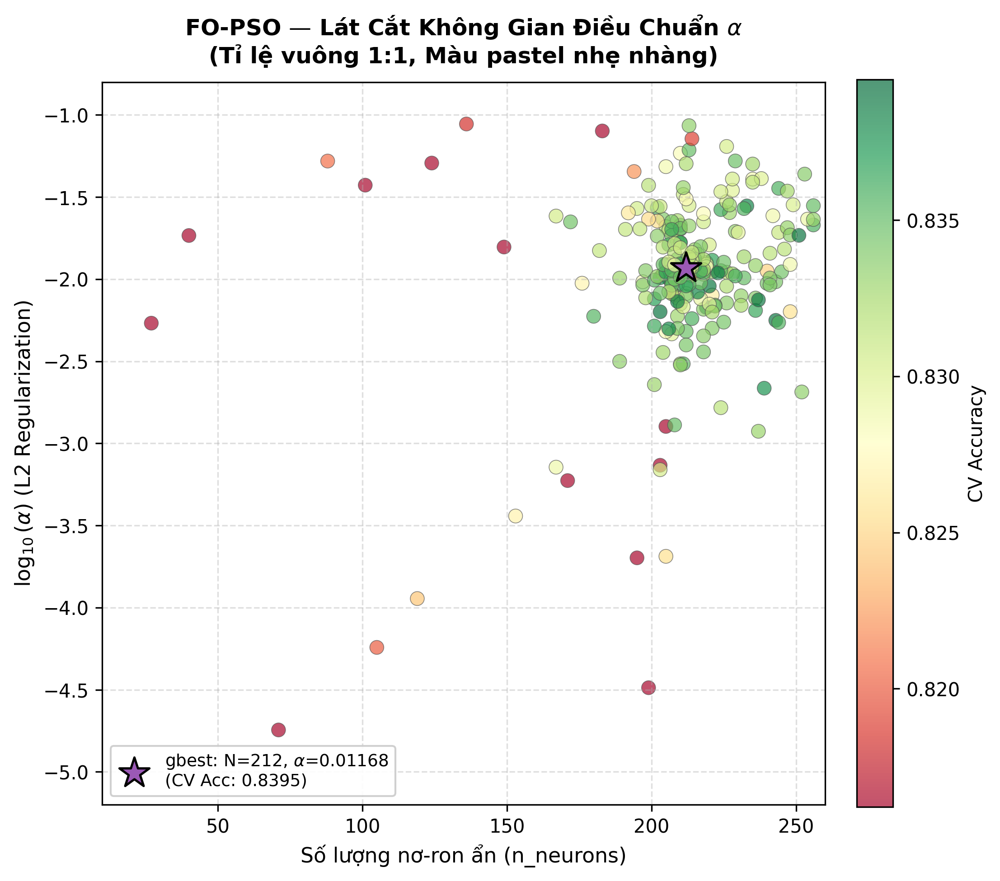

In [21]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - FO-PSO
fig, ax_al_fo = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_fo.scatter(
    hist_fo['n_neurons'], np.log10(hist_fo['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_fo, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_fo.scatter(
    n_fo, np.log10(al_fo), c='#9b59b6', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_fo}, $\alpha$={al_fo:.5f}\n(CV Acc: {cv_fo:.4f})'
)
ax_al_fo.set_box_aspect(1)
ax_al_fo.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_al_fo.set_ylabel(r'$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_fo.set_title('FO-PSO — L2 Regularization Parameter Exploration Slice $\alpha$\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_al_fo.set_xlim(10, 260)
ax_al_fo.set_ylim(-5.2, -0.8)
ax_al_fo.grid(True, linestyle='--', alpha=0.4)
ax_al_fo.legend(loc='lower left', fontsize=9, framealpha=0.92)

plt.tight_layout()
plt.show()


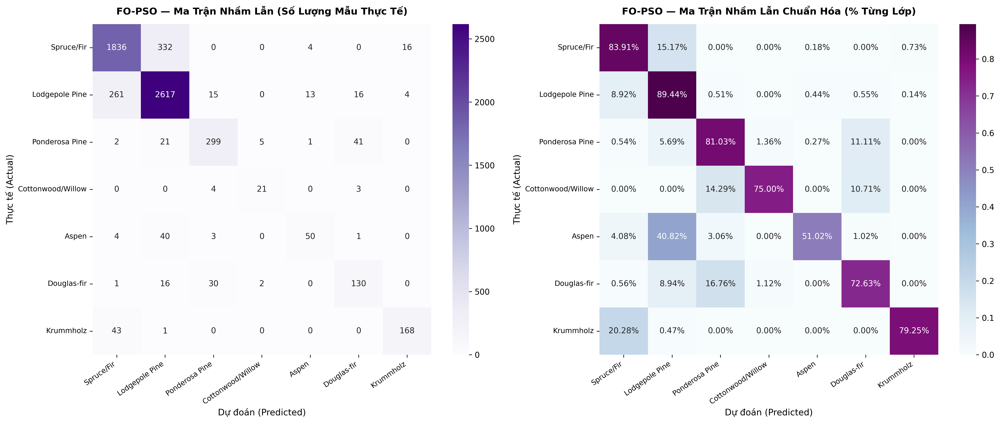

In [22]:
# Trực quan hoá Ma trận nhầm lẫn FO-PSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_fo = mlp_fo.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_fo = confusion_matrix(y_test, y_pred_fo)
cm_fo_norm = cm_fo.astype('float') / cm_fo.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_fo, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('FO-PSO — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm1.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm1.set_yticklabels(class_names, rotation=0, fontsize=9)

sns.heatmap(cm_fo_norm, annot=True, fmt='.2%', cmap='BuPu', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('FO-PSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm2.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm2.set_yticklabels(class_names, rotation=0, fontsize=9)

plt.tight_layout()
plt.show()


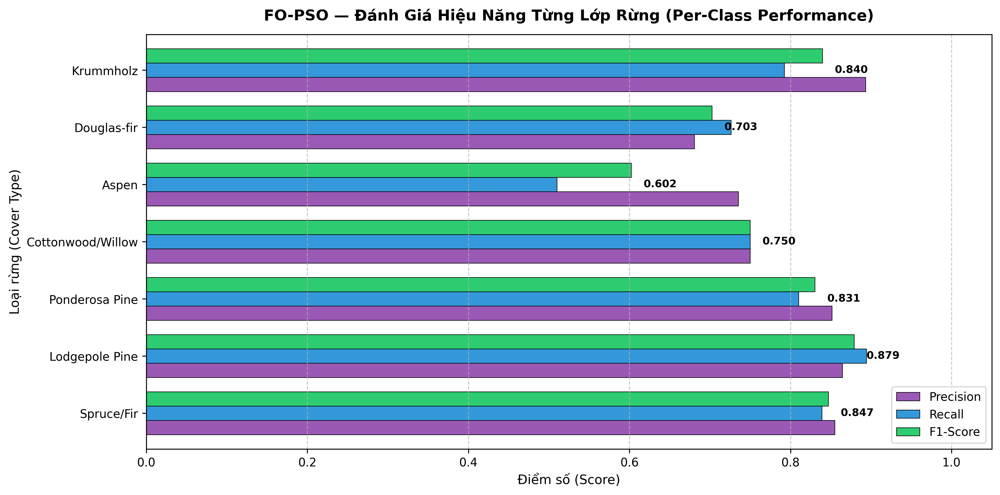


📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - FO-PSO:
                   precision    recall  f1-score   support

       Spruce/Fir     0.8551    0.8391    0.8471      2188
   Lodgepole Pine     0.8646    0.8944    0.8792      2926
   Ponderosa Pine     0.8519    0.8103    0.8306       369
Cottonwood/Willow     0.7500    0.7500    0.7500        28
            Aspen     0.7353    0.5102    0.6024        98
      Douglas-fir     0.6806    0.7263    0.7027       179
        Krummholz     0.8936    0.7925    0.8400       212

         accuracy                         0.8535      6000
        macro avg     0.8044    0.7604    0.7788      6000
     weighted avg     0.8532    0.8535    0.8527      6000


In [23]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho FO-PSO
report_fo_dict = classification_report(y_test, y_pred_fo, target_names=class_names, digits=4, output_dict=True)

metrics_fo_df = pd.DataFrame({
    'Precision': [report_fo_dict[c]['precision'] for c in class_names],
    'Recall': [report_fo_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_fo_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_fo_df.plot(kind='barh', ax=ax_metrics, color=['#9b59b6', '#3498db', '#2ecc71'], width=0.75, edgecolor='black', lw=0.5)

ax_metrics.set_title('FO-PSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_ylabel('Loại rừng (Cover Type)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.7)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white')

for i, (idx_name, row) in enumerate(metrics_fo_df.iterrows()):
    ax_metrics.text(row['F1-Score'] + 0.015, i, f"{row['F1-Score']:.3f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - FO-PSO:")
print(classification_report(y_test, y_pred_fo, target_names=class_names, digits=4))


---
## 🟣 6. Test và Trực Quan Hóa Thuật Toán Cải Tiến: Angle-based Velocity PSO (A-PSO)
Nạp kết quả tối ưu từ checkpoint `apso.pkl` (được tối ưu hóa bằng thuật toán A-PSO với cơ chế thích nghi góc vận tốc $w: 0.9 \to 0.2$), tiến hành huấn luyện mô hình MLPClassifier trên toàn bộ tập Train và kiểm thử độc lập trên tập Test.

In [26]:
ckpt_apso_path = '../results/checkpoints/apso.pkl'
if not os.path.exists(ckpt_apso_path):
    ckpt_apso_path = 'results/checkpoints/apso.pkl'

if os.path.exists(ckpt_apso_path):
    apso = joblib.load(ckpt_apso_path)
    gbest_apso = apso['gbest_pos']
    cv_apso    = apso['cv_score']
    conv_apso  = apso['convergence']
    hist_apso  = pd.DataFrame(apso['history']) if isinstance(apso['history'], list) else apso['history']

    n_apso, lr_apso, al_apso = decode_position(gbest_apso)

    print('✅ Nạp thành công checkpoint A-PSO!')
    print(f'   Neurons={n_apso}, lr={lr_apso:.5f}, alpha={al_apso:.6f} | Best CV={cv_apso:.4f}')
else:
    print(f'⚠️ Chưa tìm thấy checkpoint tại: {ckpt_apso_path}')


✅ Nạp thành công checkpoint A-PSO!
   Neurons=213, lr=0.00240, alpha=0.02056 | Best CV=0.8430


In [27]:
# Đánh giá Test cho A-PSO
mlp_apso, test_apso = train_and_evaluate(
    n_apso, lr_apso, al_apso, 
    X_train_sc, y_train, X_test_sc, y_test, 
    RANDOM_SEED, 'A-PSO', cv_score=cv_apso
)


  A-PSO                     Train Acc = 0.9210 | Test Acc = 0.8413 (84.13%) [111.1s]
📁 Đã cập nhật kết quả vào: ../results/test_results/test_accuracy.csv


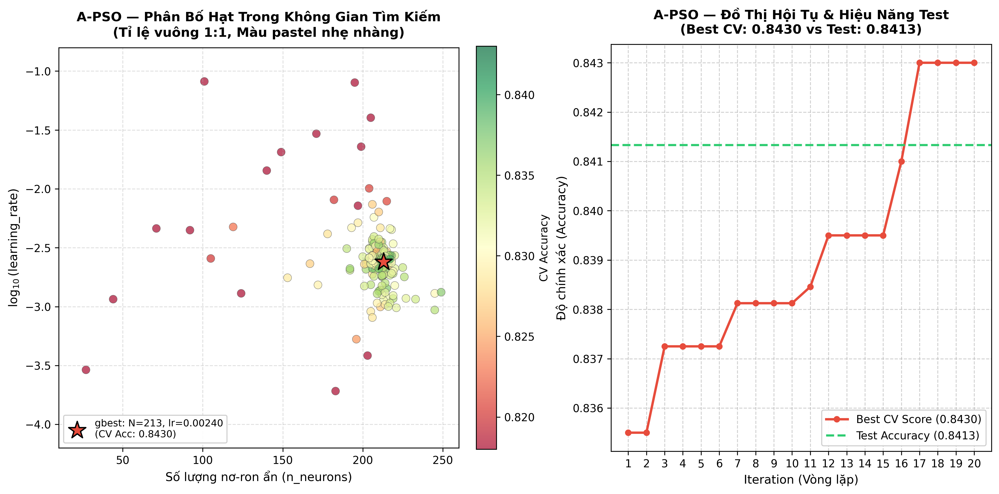

In [28]:
# Trực quan hóa Không gian tìm kiếm hạt A-PSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_apso['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_apso['n_neurons'], np.log10(hist_apso['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_apso, np.log10(lr_apso), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_apso}, lr={lr_apso:.5f}\n(CV Acc: {cv_apso:.4f})'
)
ax_sc.set_box_aspect(1)
ax_sc.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_sc.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
ax_sc.set_title('A-PSO — Hyperparameter Search Space Distribution\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_sc.set_xlim(10, 260)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.grid(True, linestyle='--', alpha=0.4)
ax_sc.legend(loc='lower left', fontsize=9, framealpha=0.92)

# 2. Đồ thị hội tụ qua các vòng lặp
ax_conv = fig.add_subplot(gs[0, 1])
iters = range(1, len(conv_apso) + 1)
ax_conv.plot(iters, conv_apso, marker='o', markersize=5, lw=2.2, color='#e74c3c', label=f'Best CV Score ({cv_apso:.4f})')
ax_conv.axhline(test_apso, color='#2ecc71', ls='--', lw=2.0, label=f'Test Accuracy ({test_apso:.4f})')
ax_conv.set_xlabel('Iteration (Iteration)', fontsize=11)
ax_conv.set_ylabel('Accuracy (Accuracy)', fontsize=11)
ax_conv.set_title(f'A-PSO — Convergence Trajectory & Generalization Performance\n(Best CV: {cv_apso:.4f} vs Test: {test_apso:.4f})', fontsize=12, fontweight='bold', pad=10)
ax_conv.set_xticks(list(iters))
ax_conv.grid(True, linestyle='--', alpha=0.6)
ax_conv.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.92)

plt.tight_layout()
plt.show()


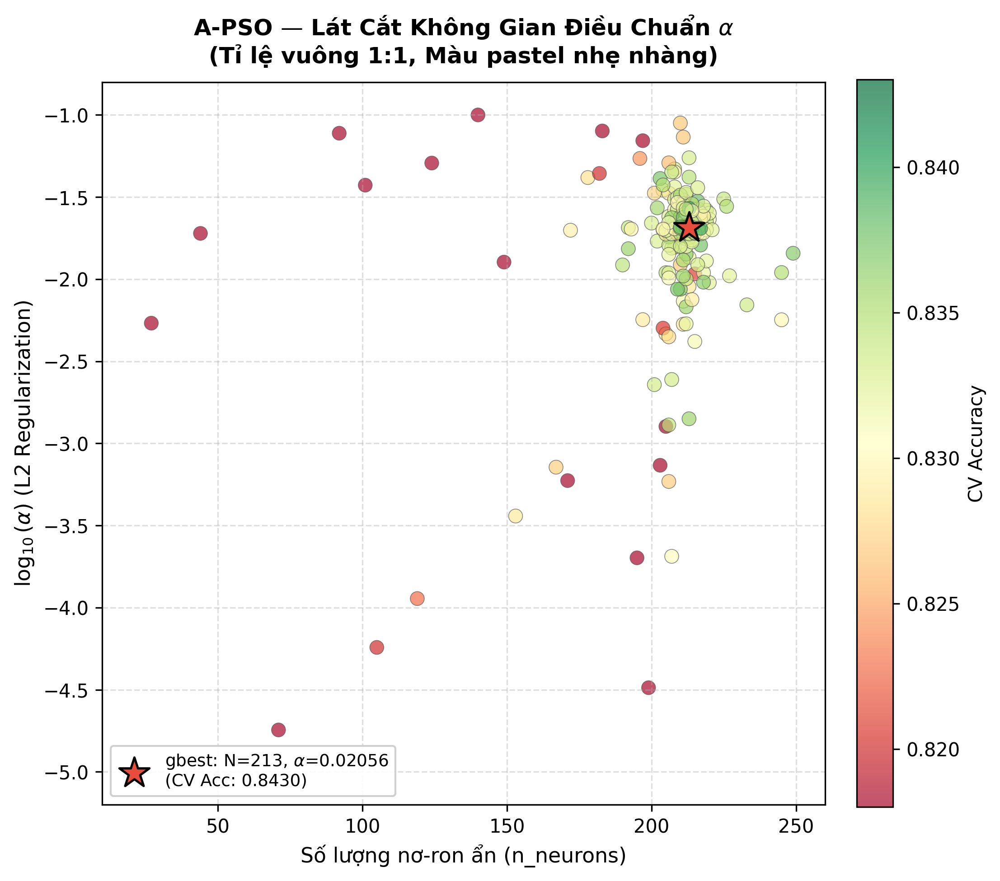

In [29]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - A-PSO
fig, ax_al_apso = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_apso.scatter(
    hist_apso['n_neurons'], np.log10(hist_apso['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_apso, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_apso.scatter(
    n_apso, np.log10(al_apso), c='#e74c3c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_apso}, $\alpha$={al_apso:.5f}\n(CV Acc: {cv_apso:.4f})'
)
ax_al_apso.set_box_aspect(1)
ax_al_apso.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_al_apso.set_ylabel(r'$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_apso.set_title('A-PSO — L2 Regularization Parameter Exploration Slice $\alpha$\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_al_apso.set_xlim(10, 260)
ax_al_apso.set_ylim(-5.2, -0.8)
ax_al_apso.grid(True, linestyle='--', alpha=0.4)
ax_al_apso.legend(loc='lower left', fontsize=9, framealpha=0.92)

plt.tight_layout()
plt.show()


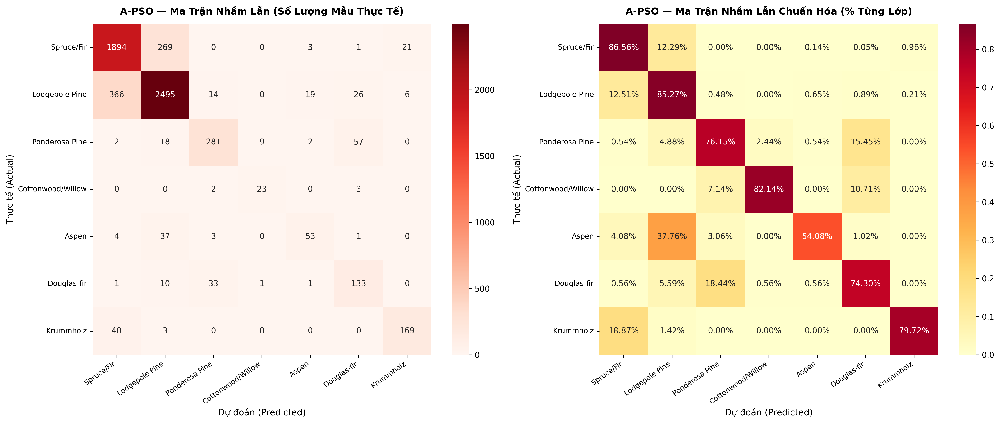

In [30]:
# Trực quan hoá Ma trận nhầm lẫn A-PSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_apso = mlp_apso.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_apso = confusion_matrix(y_test, y_pred_apso)
cm_apso_norm = cm_apso.astype('float') / cm_apso.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_apso, annot=True, fmt='d', cmap='Reds', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('A-PSO — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm1.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm1.set_yticklabels(class_names, rotation=0, fontsize=9)

sns.heatmap(cm_apso_norm, annot=True, fmt='.2%', cmap='YlOrRd', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('A-PSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm2.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm2.set_yticklabels(class_names, rotation=0, fontsize=9)

plt.tight_layout()
plt.show()


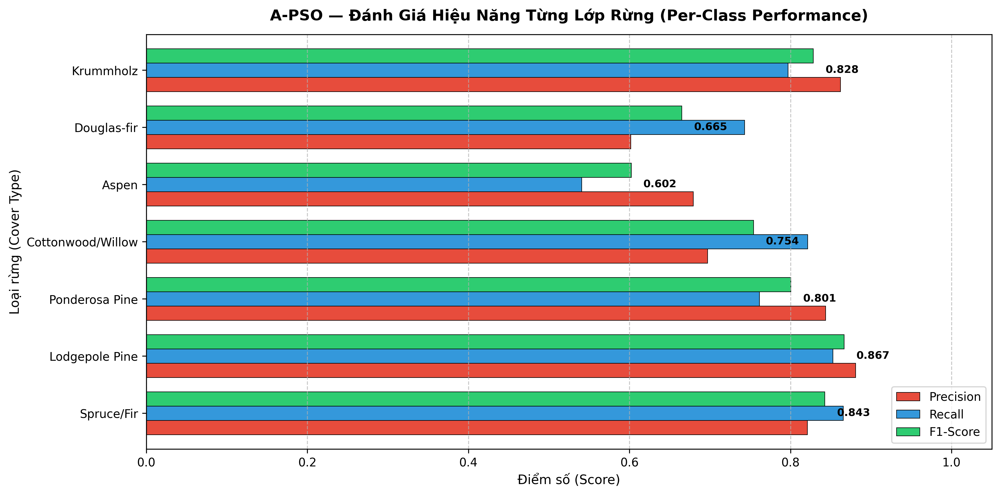


📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - A-PSO:
                   precision    recall  f1-score   support

       Spruce/Fir     0.8210    0.8656    0.8427      2188
   Lodgepole Pine     0.8810    0.8527    0.8666      2926
   Ponderosa Pine     0.8438    0.7615    0.8006       369
Cottonwood/Willow     0.6970    0.8214    0.7541        28
            Aspen     0.6795    0.5408    0.6023        98
      Douglas-fir     0.6018    0.7430    0.6650       179
        Krummholz     0.8622    0.7972    0.8284       212

         accuracy                         0.8413      6000
        macro avg     0.7695    0.7689    0.7657      6000
     weighted avg     0.8437    0.8413    0.8416      6000


In [31]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho A-PSO
report_apso_dict = classification_report(y_test, y_pred_apso, target_names=class_names, digits=4, output_dict=True)

metrics_apso_df = pd.DataFrame({
    'Precision': [report_apso_dict[c]['precision'] for c in class_names],
    'Recall': [report_apso_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_apso_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_apso_df.plot(kind='barh', ax=ax_metrics, color=['#e74c3c', '#3498db', '#2ecc71'], width=0.75, edgecolor='black', lw=0.5)

ax_metrics.set_title('A-PSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_ylabel('Loại rừng (Cover Type)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.7)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white')

for i, (idx_name, row) in enumerate(metrics_apso_df.iterrows()):
    ax_metrics.text(row['F1-Score'] + 0.015, i, f"{row['F1-Score']:.3f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - A-PSO:")
print(classification_report(y_test, y_pred_apso, target_names=class_names, digits=4))


---
## 🟣 7. Test và Trực Quan Hóa Thuật Toán Cải Tiến: Non-linear Attraction PSO (NL-PSO)
Nạp kết quả tối ưu từ checkpoint `nl_pso.pkl` (được tối ưu hóa bằng thuật toán NL-PSO với lực hút phi tuyến bậc $\gamma=2.0$), tiến hành huấn luyện mô hình MLPClassifier trên toàn bộ tập Train và kiểm thử độc lập trên tập Test.

In [32]:
ckpt_nl_path = '../results/checkpoints/nl_pso.pkl'
if not os.path.exists(ckpt_nl_path):
    ckpt_nl_path = 'results/checkpoints/nl_pso.pkl'

if os.path.exists(ckpt_nl_path):
    nl = joblib.load(ckpt_nl_path)
    gbest_nl = nl['gbest_pos']
    cv_nl    = nl['cv_score']
    conv_nl  = nl['convergence']
    hist_nl  = pd.DataFrame(nl['history']) if isinstance(nl['history'], list) else nl['history']

    n_nl, lr_nl, al_nl = decode_position(gbest_nl)

    print('✅ Nạp thành công checkpoint NL-PSO!')
    print(f'   Neurons={n_nl}, lr={lr_nl:.5f}, alpha={al_nl:.6f} | Best CV={cv_nl:.4f}')
else:
    print(f'⚠️ Chưa tìm thấy checkpoint tại: {ckpt_nl_path}')


✅ Nạp thành công checkpoint NL-PSO!
   Neurons=256, lr=0.00228, alpha=0.00588 | Best CV=0.8398


In [33]:
# Đánh giá Test cho NL-PSO
mlp_nl, test_nl = train_and_evaluate(
    n_nl, lr_nl, al_nl, 
    X_train_sc, y_train, X_test_sc, y_test, 
    RANDOM_SEED, 'NL-PSO', cv_score=cv_nl
)


  NL-PSO                    Train Acc = 0.9535 | Test Acc = 0.8505 (85.05%) [132.3s]
📁 Đã cập nhật kết quả vào: ../results/test_results/test_accuracy.csv


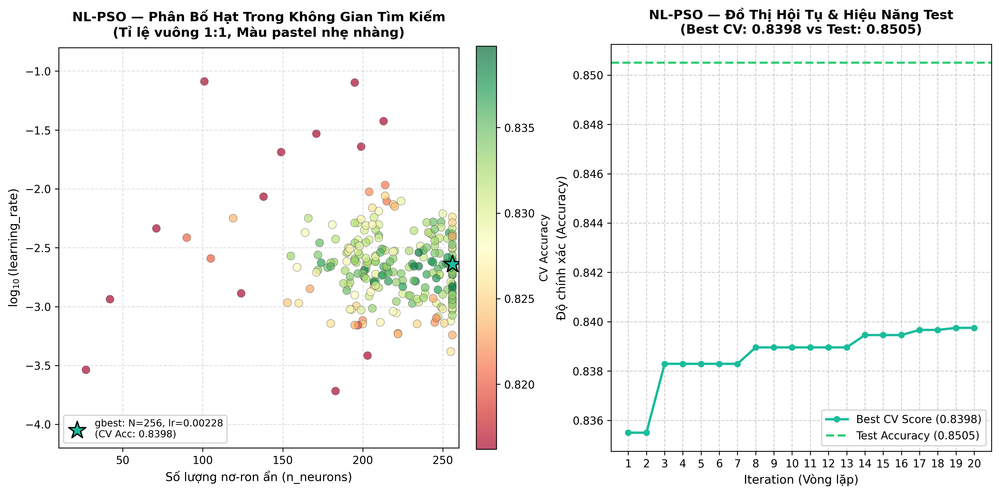

In [34]:
# Trực quan hóa Không gian tìm kiếm hạt NL-PSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_nl['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_nl['n_neurons'], np.log10(hist_nl['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_nl, np.log10(lr_nl), c='#1abc9c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_nl}, lr={lr_nl:.5f}\n(CV Acc: {cv_nl:.4f})'
)
ax_sc.set_box_aspect(1)
ax_sc.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_sc.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
ax_sc.set_title('NL-PSO — Hyperparameter Search Space Distribution\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_sc.set_xlim(10, 260)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.grid(True, linestyle='--', alpha=0.4)
ax_sc.legend(loc='lower left', fontsize=9, framealpha=0.92)

# 2. Đồ thị hội tụ qua các vòng lặp
ax_conv = fig.add_subplot(gs[0, 1])
iters = range(1, len(conv_nl) + 1)
ax_conv.plot(iters, conv_nl, marker='o', markersize=5, lw=2.2, color='#1abc9c', label=f'Best CV Score ({cv_nl:.4f})')
ax_conv.axhline(test_nl, color='#2ecc71', ls='--', lw=2.0, label=f'Test Accuracy ({test_nl:.4f})')
ax_conv.set_xlabel('Iteration (Iteration)', fontsize=11)
ax_conv.set_ylabel('Accuracy (Accuracy)', fontsize=11)
ax_conv.set_title(f'NL-PSO — Convergence Trajectory & Generalization Performance\n(Best CV: {cv_nl:.4f} vs Test: {test_nl:.4f})', fontsize=12, fontweight='bold', pad=10)
ax_conv.set_xticks(list(iters))
ax_conv.grid(True, linestyle='--', alpha=0.6)
ax_conv.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.92)

plt.tight_layout()
plt.show()


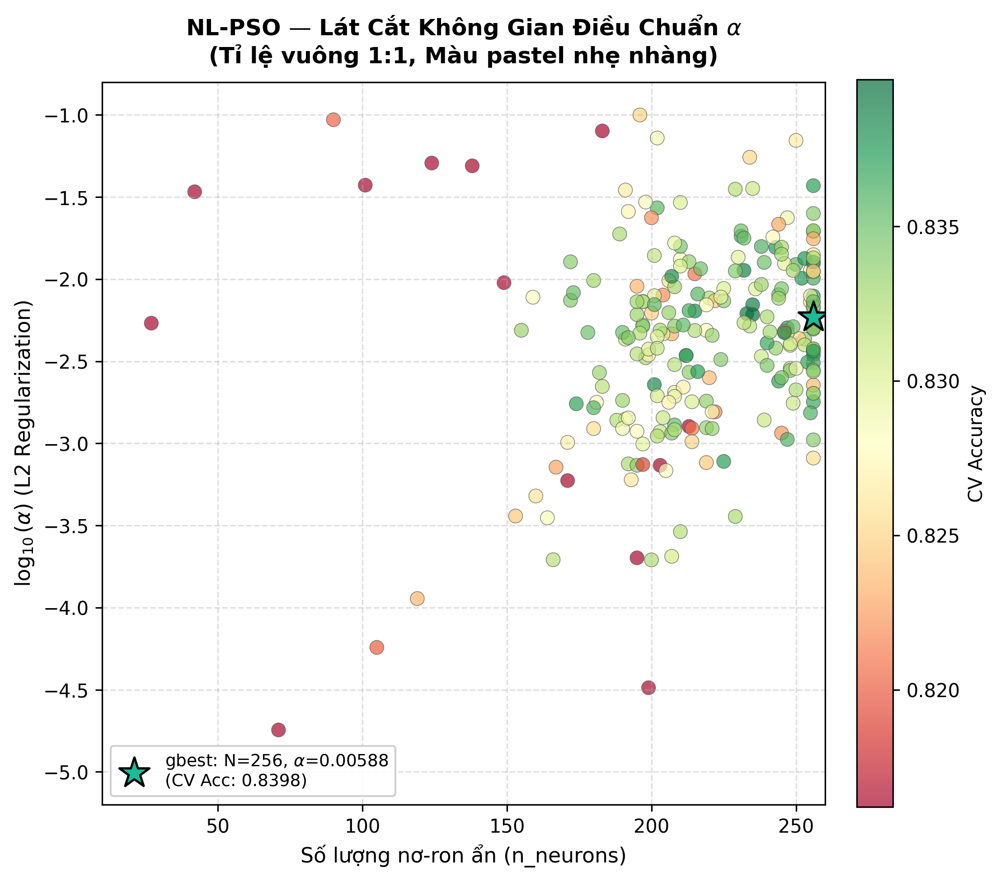

In [35]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - NL-PSO
fig, ax_al_nl = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_nl.scatter(
    hist_nl['n_neurons'], np.log10(hist_nl['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_nl, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_nl.scatter(
    n_nl, np.log10(al_nl), c='#1abc9c', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_nl}, $\alpha$={al_nl:.5f}\n(CV Acc: {cv_nl:.4f})'
)
ax_al_nl.set_box_aspect(1)
ax_al_nl.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_al_nl.set_ylabel(r'$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_nl.set_title('NL-PSO — L2 Regularization Parameter Exploration Slice $\alpha$\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_al_nl.set_xlim(10, 260)
ax_al_nl.set_ylim(-5.2, -0.8)
ax_al_nl.grid(True, linestyle='--', alpha=0.4)
ax_al_nl.legend(loc='lower left', fontsize=9, framealpha=0.92)

plt.tight_layout()
plt.show()


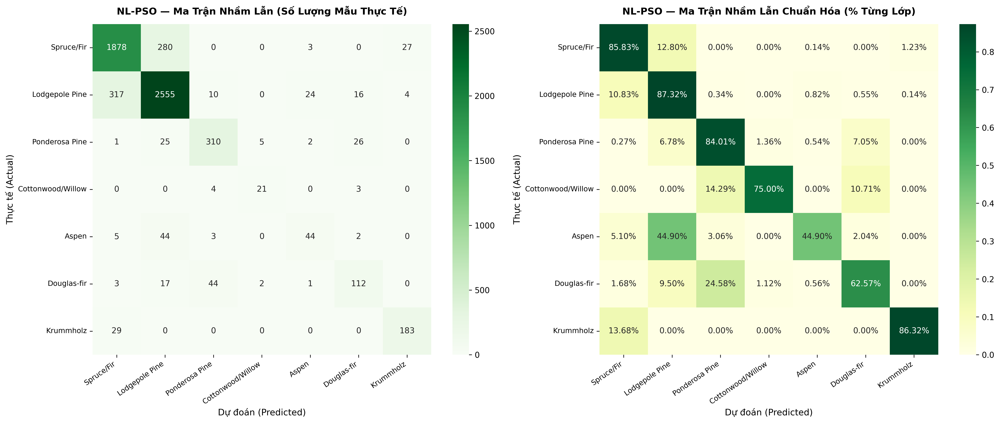

In [36]:
# Trực quan hoá Ma trận nhầm lẫn NL-PSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_nl = mlp_nl.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_nl = confusion_matrix(y_test, y_pred_nl)
cm_nl_norm = cm_nl.astype('float') / cm_nl.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_nl, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('NL-PSO — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm1.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm1.set_yticklabels(class_names, rotation=0, fontsize=9)

sns.heatmap(cm_nl_norm, annot=True, fmt='.2%', cmap='YlGn', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('NL-PSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm2.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm2.set_yticklabels(class_names, rotation=0, fontsize=9)

plt.tight_layout()
plt.show()


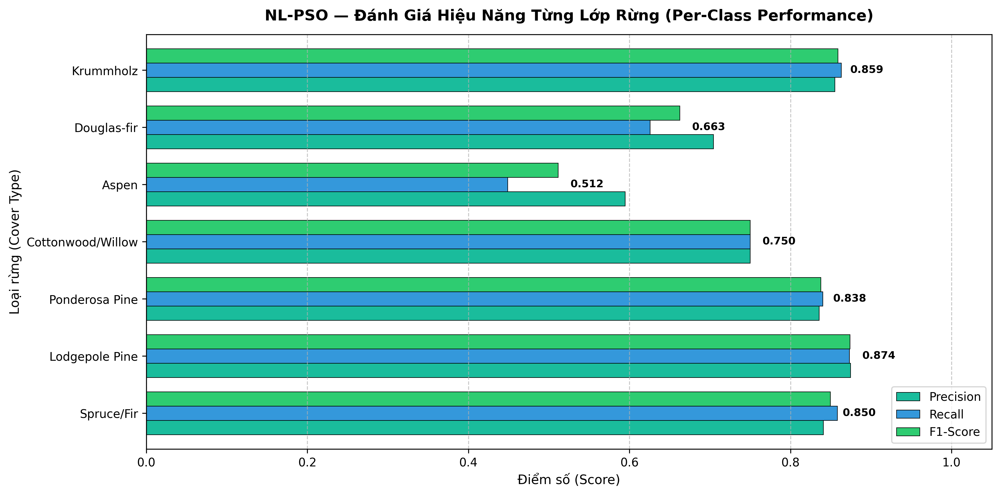


📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - NL-PSO:
                   precision    recall  f1-score   support

       Spruce/Fir     0.8410    0.8583    0.8496      2188
   Lodgepole Pine     0.8747    0.8732    0.8740      2926
   Ponderosa Pine     0.8356    0.8401    0.8378       369
Cottonwood/Willow     0.7500    0.7500    0.7500        28
            Aspen     0.5946    0.4490    0.5116        98
      Douglas-fir     0.7044    0.6257    0.6627       179
        Krummholz     0.8551    0.8632    0.8592       212

         accuracy                         0.8505      6000
        macro avg     0.7793    0.7514    0.7636      6000
     weighted avg     0.8491    0.8505    0.8495      6000


In [37]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho NL-PSO
report_nl_dict = classification_report(y_test, y_pred_nl, target_names=class_names, digits=4, output_dict=True)

metrics_nl_df = pd.DataFrame({
    'Precision': [report_nl_dict[c]['precision'] for c in class_names],
    'Recall': [report_nl_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_nl_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_nl_df.plot(kind='barh', ax=ax_metrics, color=['#1abc9c', '#3498db', '#2ecc71'], width=0.75, edgecolor='black', lw=0.5)

ax_metrics.set_title('NL-PSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_ylabel('Loại rừng (Cover Type)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.7)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white')

for i, (idx_name, row) in enumerate(metrics_nl_df.iterrows()):
    ax_metrics.text(row['F1-Score'] + 0.015, i, f"{row['F1-Score']:.3f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - NL-PSO:")
print(classification_report(y_test, y_pred_nl, target_names=class_names, digits=4))


---
## 🟣 8. Test và Trực Quan Hóa Thuật Toán Cải Tiến: Mean-based / Top-K Attraction PSO (MB-PSO)
Nạp kết quả tối ưu từ checkpoint `mbpso.pkl` (được tối ưu hóa bằng thuật toán MB-PSO với lực hút xã hội hướng về trọng tâm Top-4 hạt dẫn đầu $c_3=1.0$), tiến hành huấn luyện mô hình MLPClassifier trên toàn bộ tập Train và kiểm thử độc lập trên tập Test.

In [40]:
ckpt_mb_path = '../results/checkpoints/mbpso.pkl'
if not os.path.exists(ckpt_mb_path):
    ckpt_mb_path = '../results/checkpoints/mb_pso.pkl'
if not os.path.exists(ckpt_mb_path):
    ckpt_mb_path = 'results/checkpoints/mbpso.pkl'

if os.path.exists(ckpt_mb_path):
    mb = joblib.load(ckpt_mb_path)
    gbest_mb = mb['gbest_pos']
    cv_mb    = mb['cv_score']
    conv_mb  = mb['convergence']
    hist_mb  = pd.DataFrame(mb['history']) if isinstance(mb['history'], list) else mb['history']

    n_mb, lr_mb, al_mb = decode_position(gbest_mb)

    print('✅ Nạp thành công checkpoint MB-PSO!')
    print(f'   Neurons={n_mb}, lr={lr_mb:.5f}, alpha={al_mb:.6f} | Best CV={cv_mb:.4f}')
else:
    print(f'⚠️ Chưa tìm thấy checkpoint tại: {ckpt_mb_path}')


✅ Nạp thành công checkpoint MB-PSO!
   Neurons=193, lr=0.00420, alpha=0.00746 | Best CV=0.8390


In [41]:
# Đánh giá Test cho MB-PSO
mlp_mb, test_mb = train_and_evaluate(
    n_mb, lr_mb, al_mb, 
    X_train_sc, y_train, X_test_sc, y_test, 
    RANDOM_SEED, 'MB-PSO', cv_score=cv_mb
)


  MB-PSO                    Train Acc = 0.9172 | Test Acc = 0.8447 (84.47%) [20.8s]
📁 Đã cập nhật kết quả vào: ../results/test_results/test_accuracy.csv


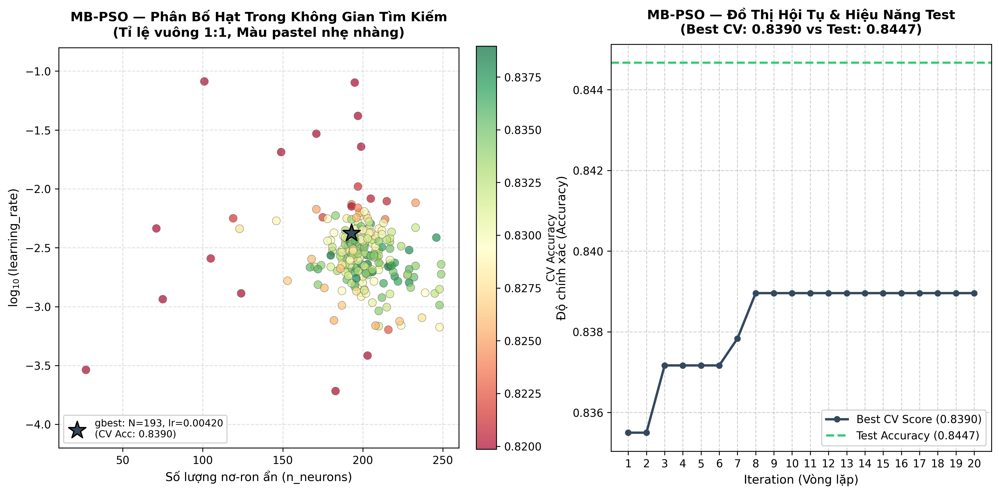

In [42]:
# Trực quan hóa Không gian tìm kiếm hạt MB-PSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_mb['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_mb['n_neurons'], np.log10(hist_mb['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_mb, np.log10(lr_mb), c='#34495e', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_mb}, lr={lr_mb:.5f}\n(CV Acc: {cv_mb:.4f})'
)
ax_sc.set_box_aspect(1)
ax_sc.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_sc.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
ax_sc.set_title('MB-PSO — Hyperparameter Search Space Distribution\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_sc.set_xlim(10, 260)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.grid(True, linestyle='--', alpha=0.4)
ax_sc.legend(loc='lower left', fontsize=9, framealpha=0.92)

# 2. Đồ thị hội tụ qua các vòng lặp
ax_conv = fig.add_subplot(gs[0, 1])
iters = range(1, len(conv_mb) + 1)
ax_conv.plot(iters, conv_mb, marker='o', markersize=5, lw=2.2, color='#34495e', label=f'Best CV Score ({cv_mb:.4f})')
ax_conv.axhline(test_mb, color='#2ecc71', ls='--', lw=2.0, label=f'Test Accuracy ({test_mb:.4f})')
ax_conv.set_xlabel('Iteration (Iteration)', fontsize=11)
ax_conv.set_ylabel('Accuracy (Accuracy)', fontsize=11)
ax_conv.set_title(f'MB-PSO — Convergence Trajectory & Generalization Performance\n(Best CV: {cv_mb:.4f} vs Test: {test_mb:.4f})', fontsize=12, fontweight='bold', pad=10)
ax_conv.set_xticks(list(iters))
ax_conv.grid(True, linestyle='--', alpha=0.6)
ax_conv.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.92)

plt.tight_layout()
plt.show()


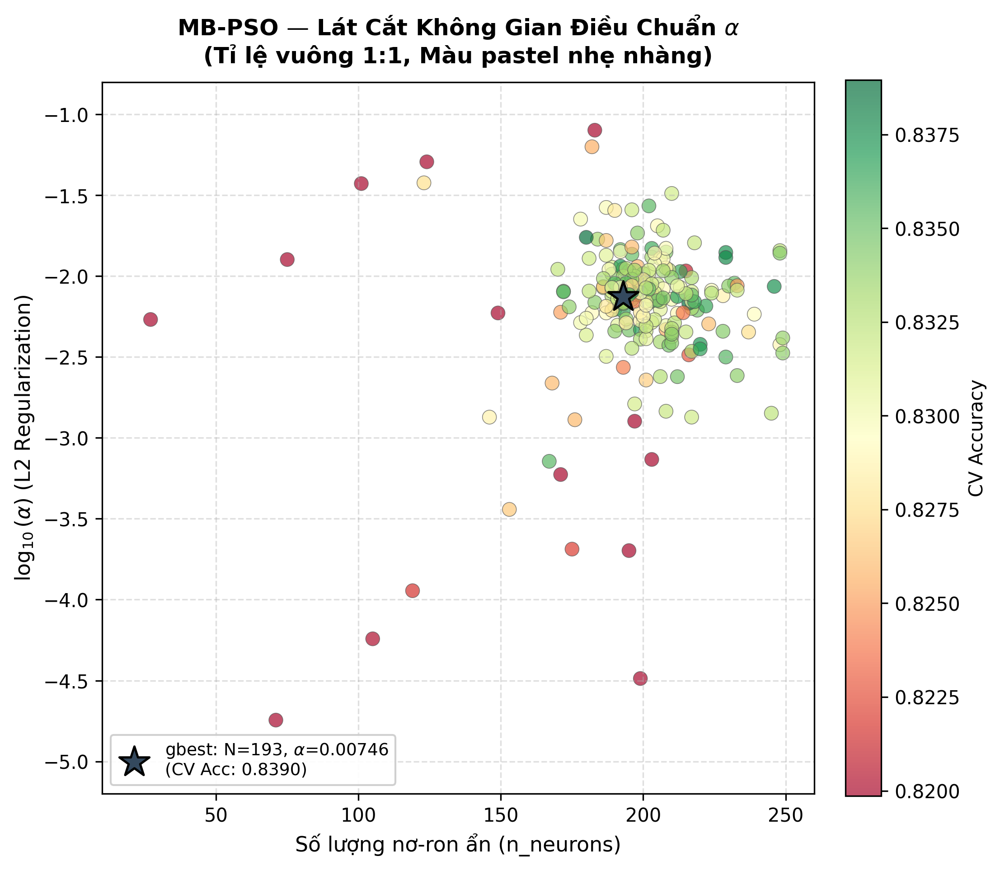

In [43]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - MB-PSO
fig, ax_al_mb = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_mb.scatter(
    hist_mb['n_neurons'], np.log10(hist_mb['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_mb, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_mb.scatter(
    n_mb, np.log10(al_mb), c='#34495e', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_mb}, $\alpha$={al_mb:.5f}\n(CV Acc: {cv_mb:.4f})'
)
ax_al_mb.set_box_aspect(1)
ax_al_mb.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
ax_al_mb.set_ylabel(r'$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_mb.set_title('MB-PSO — L2 Regularization Parameter Exploration Slice $\alpha$\n(1:1 Square Ratio, RdYlGn Colormap nhẹ nhàng)', fontsize=12, fontweight='bold', pad=10)
ax_al_mb.set_xlim(10, 260)
ax_al_mb.set_ylim(-5.2, -0.8)
ax_al_mb.grid(True, linestyle='--', alpha=0.4)
ax_al_mb.legend(loc='lower left', fontsize=9, framealpha=0.92)

plt.tight_layout()
plt.show()


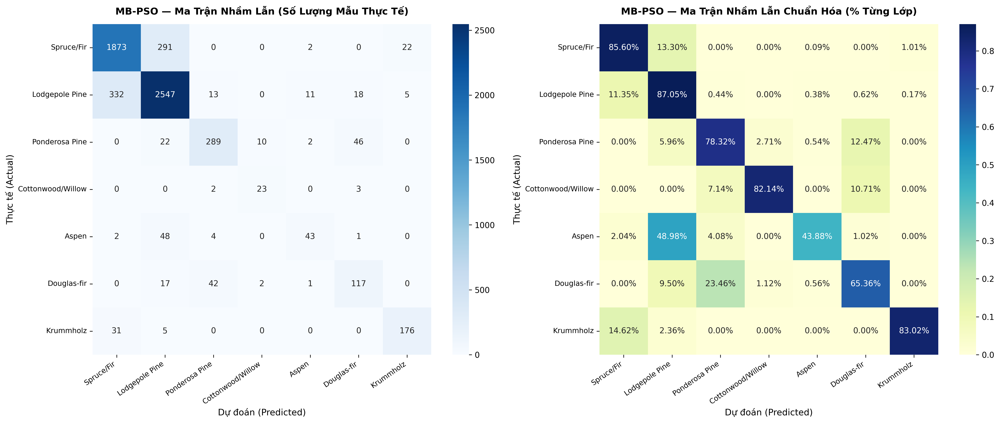

In [44]:
# Trực quan hoá Ma trận nhầm lẫn MB-PSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_mb = mlp_mb.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_mb = confusion_matrix(y_test, y_pred_mb)
cm_mb_norm = cm_mb.astype('float') / cm_mb.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_mb, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('MB-PSO — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm1.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm1.set_yticklabels(class_names, rotation=0, fontsize=9)

sns.heatmap(cm_mb_norm, annot=True, fmt='.2%', cmap='YlGnBu', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('MB-PSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (Actual)', fontsize=11)
ax_cm2.set_xticklabels(class_names, rotation=35, ha='right', fontsize=9)
ax_cm2.set_yticklabels(class_names, rotation=0, fontsize=9)

plt.tight_layout()
plt.show()


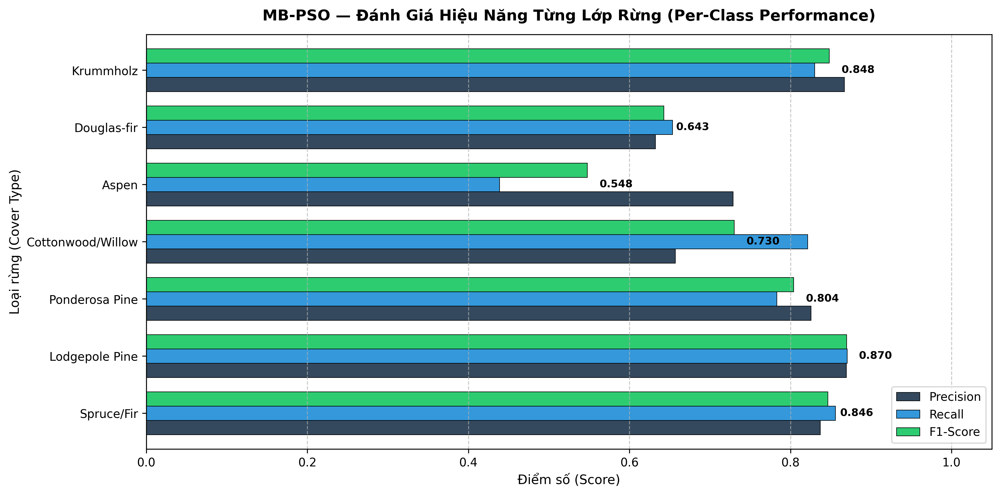


📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - MB-PSO:
                   precision    recall  f1-score   support

       Spruce/Fir     0.8369    0.8560    0.8464      2188
   Lodgepole Pine     0.8693    0.8705    0.8699      2926
   Ponderosa Pine     0.8257    0.7832    0.8039       369
Cottonwood/Willow     0.6571    0.8214    0.7302        28
            Aspen     0.7288    0.4388    0.5478        98
      Douglas-fir     0.6324    0.6536    0.6429       179
        Krummholz     0.8670    0.8302    0.8482       212

         accuracy                         0.8447      6000
        macro avg     0.7739    0.7505    0.7556      6000
     weighted avg     0.8444    0.8447    0.8438      6000


In [45]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho MB-PSO
report_mb_dict = classification_report(y_test, y_pred_mb, target_names=class_names, digits=4, output_dict=True)

metrics_mb_df = pd.DataFrame({
    'Precision': [report_mb_dict[c]['precision'] for c in class_names],
    'Recall': [report_mb_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_mb_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_mb_df.plot(kind='barh', ax=ax_metrics, color=['#34495e', '#3498db', '#2ecc71'], width=0.75, edgecolor='black', lw=0.5)

ax_metrics.set_title('MB-PSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_ylabel('Loại rừng (Cover Type)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.7)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white')

for i, (idx_name, row) in enumerate(metrics_mb_df.iterrows()):
    ax_metrics.text(row['F1-Score'] + 0.015, i, f"{row['F1-Score']:.3f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n📋 Báo Cáo Phân Loại Chi Tiết (Classification Report) - MB-PSO:")
print(classification_report(y_test, y_pred_mb, target_names=class_names, digits=4))


---
## ⚛️ 9. Đánh Giá Biến Thể Quantum-inspired PSO (QPSO)
Đánh giá mô hình MLPClassifier tối ưu bằng thuật toán **Quantum-inspired PSO (QPSO)** trên tập kiểm thử độc lập (Test Set: 6,000 mẫu).

In [35]:
# Nạp Checkpoint QPSO
ckpt_qpso_path = '../results/checkpoints/qpso.pkl'
if not os.path.exists(ckpt_qpso_path):
    ckpt_qpso_path = 'results/checkpoints/qpso.pkl'

if os.path.exists(ckpt_qpso_path):
    qpso_data = joblib.load(ckpt_qpso_path)
    gbest_qpso = qpso_data['gbest_pos']
    cv_qpso = qpso_data['cv_score']
    conv_qpso = qpso_data['convergence']
    hist_qpso = pd.DataFrame(qpso_data['history']) if isinstance(qpso_data['history'], list) else qpso_data['history']
    beta_hist_qpso = qpso_data.get('beta_history', None)

    n_qpso, lr_qpso, al_qpso = decode_position(gbest_qpso)

    print('✅ Nạp thành công checkpoint QPSO!')
    print(f'   Nghiệm tối ưu: Neurons={n_qpso}, lr={lr_qpso:.5f}, alpha={al_qpso:.6f}')
    print(f'   CV Score     : {cv_qpso:.4f}')
else:
    print(f'❌ Không tìm thấy checkpoint tại {ckpt_qpso_path}')

✅ Nạp thành công checkpoint QPSO!
   Nghiệm tối ưu: Neurons=256, lr=0.00234, alpha=0.001012
   CV Score     : 0.8421


In [36]:
# Đánh giá Test cho QPSO
mlp_qpso_ckpt = '../results/checkpoints/mlp_qpso.pkl'
if not os.path.exists(mlp_qpso_ckpt):
    mlp_qpso_ckpt = 'results/checkpoints/mlp_qpso.pkl'

if os.path.exists(mlp_qpso_ckpt):
    print('📦 Nạp mô hình MLP QPSO đã huấn luyện sẵn...')
    mlp_qpso = joblib.load(mlp_qpso_ckpt)
    test_qpso = mlp_qpso.score(X_test_sc, y_test)
    train_qpso = mlp_qpso.score(X_train_sc, y_train)
    print(f'  QPSO                      Train Acc = {train_qpso:.4f} | Test Acc = {test_qpso:.4f} ({test_qpso*100:.2f}%)')
    save_test_accuracy('QPSO', test_qpso, (n_qpso, lr_qpso, al_qpso), cv_score=cv_qpso)
else:
    mlp_qpso, test_qpso = train_and_evaluate(
        n_qpso, lr_qpso, al_qpso,
        X_train_sc, y_train, X_test_sc, y_test,
        RANDOM_SEED, 'QPSO', cv_score=cv_qpso
    )
    joblib.dump(mlp_qpso, mlp_qpso_ckpt)

📦 Nạp mô hình MLP QPSO đã huấn luyện sẵn...
  QPSO                      Train Acc = 0.9313 | Test Acc = 0.8467 (84.67%)
✅ Đã lưu kết quả 'QPSO' (Test Acc: 0.8467) vào ../results/test_results/test_accuracy.csv


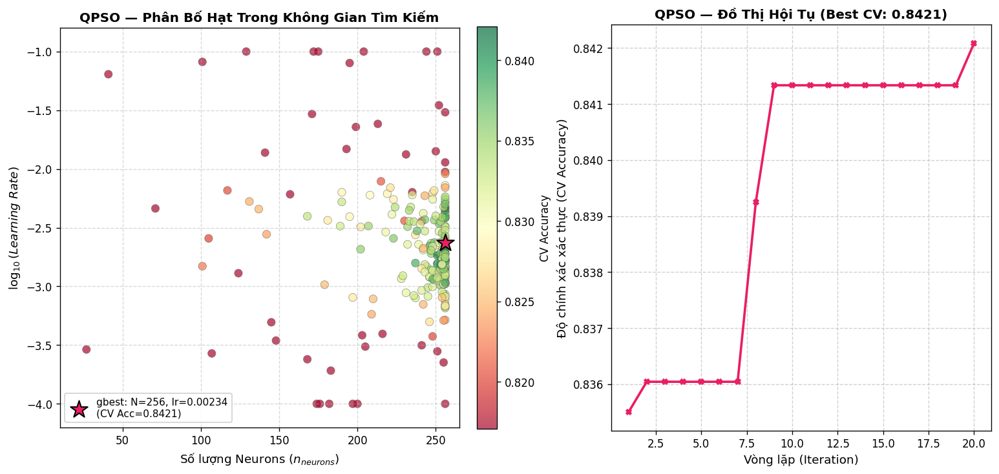

In [37]:
# Trực quan hóa Không gian tìm kiếm hạt QPSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_qpso['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_qpso['n_neurons'], np.log10(hist_qpso['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_qpso, np.log10(lr_qpso), c='#e91e63', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qpso}, lr={lr_qpso:.5f}\n(CV Acc={cv_qpso:.4f})'
)
ax_sc.set_xlim(10, 265)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.set_aspect(abs((265 - 10) / (-0.8 - (-4.2))))
ax_sc.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_sc.set_ylabel('$\log_{10}(Learning\ Rate)$', fontsize=11)
ax_sc.set_title('QPSO — Hyperparameter Search Space Distribution', fontsize=12, fontweight='bold')
ax_sc.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_sc.grid(True, linestyle='--', alpha=0.5)

# 2. Đồ thị hội tụ (Convergence curve)
ax_co = fig.add_subplot(gs[0, 1])
ax_co.plot(range(1, len(conv_qpso) + 1), conv_qpso, color='#e91e63', lw=2.2, marker='X', markersize=5)
ax_co.set_xlabel('Iteration', fontsize=11)
ax_co.set_ylabel('Accuracy xác thực (CV Accuracy)', fontsize=11)
ax_co.set_title(f'QPSO — Đồ Thị Hội Tụ (Best CV: {cv_qpso:.4f})', fontsize=12, fontweight='bold')
ax_co.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

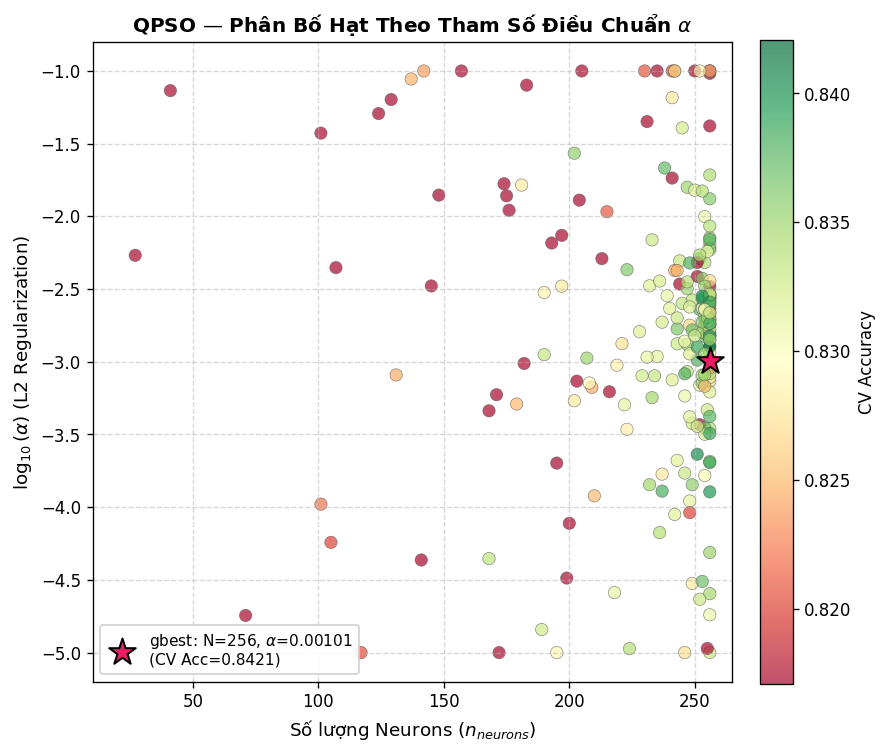

In [38]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - QPSO
fig, ax_al_qp = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_qp.scatter(
    hist_qpso['n_neurons'], np.log10(hist_qpso['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_qp, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_qp.scatter(
    n_qpso, np.log10(al_qpso), c='#e91e63', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qpso}, $\alpha$={al_qpso:.5f}\n(CV Acc={cv_qpso:.4f})'
)
ax_al_qp.set_xlim(10, 265)
ax_al_qp.set_ylim(-5.2, -0.8)
ax_al_qp.set_aspect(abs((265 - 10) / (-0.8 - (-5.2))))
ax_al_qp.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_al_qp.set_ylabel('$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_qp.set_title('QPSO — Particle Distribution across L2 Regularization Parameter $\alpha$', fontsize=12, fontweight='bold')
ax_al_qp.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_al_qp.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

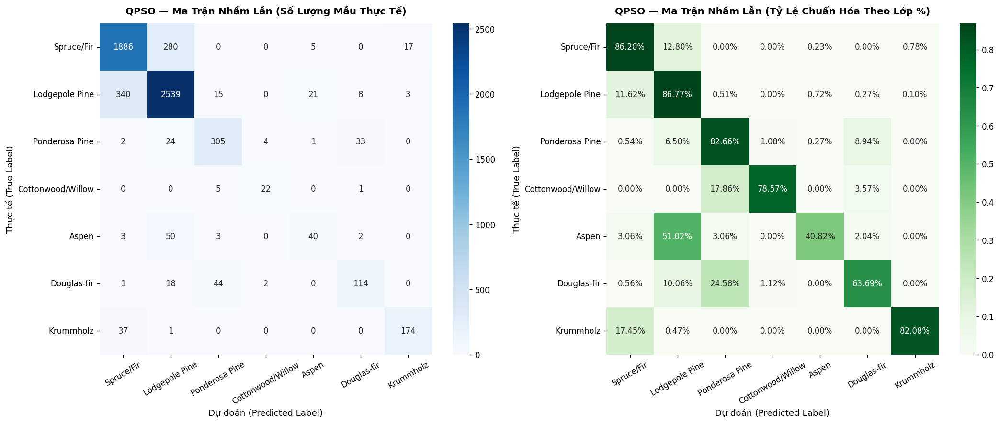

In [39]:
# Trực quan hoá Ma trận nhầm lẫn QPSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_qp = mlp_qpso.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_qp = confusion_matrix(y_test, y_pred_qp)
cm_qp_norm = cm_qp.astype('float') / cm_qp.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_qp, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('QPSO — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm1.tick_params(axis='x', rotation=30)

sns.heatmap(cm_qp_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('QPSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

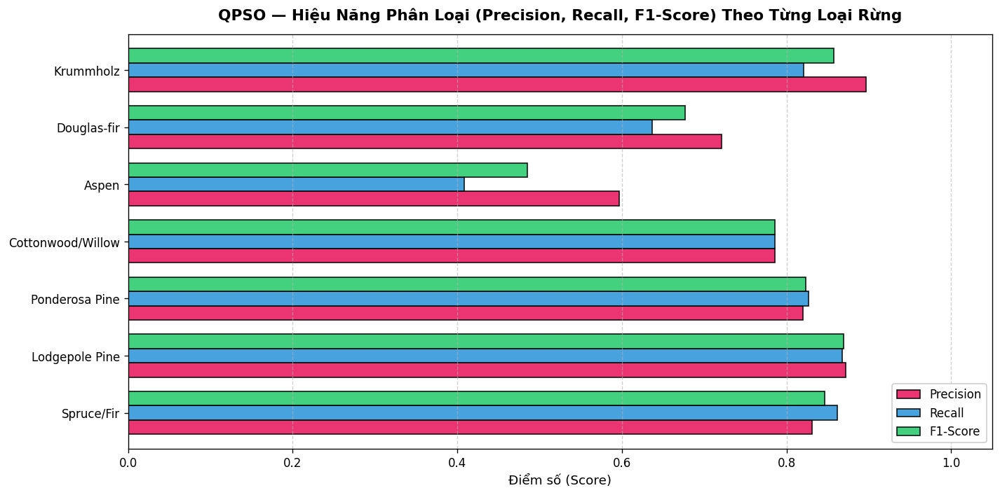

                   precision    recall  f1-score   support

       Spruce/Fir     0.8312    0.8620    0.8463      2188
   Lodgepole Pine     0.8719    0.8677    0.8698      2926
   Ponderosa Pine     0.8199    0.8266    0.8232       369
Cottonwood/Willow     0.7857    0.7857    0.7857        28
            Aspen     0.5970    0.4082    0.4848        98
      Douglas-fir     0.7215    0.6369    0.6766       179
        Krummholz     0.8969    0.8208    0.8571       212

         accuracy                         0.8467      6000
        macro avg     0.7892    0.7440    0.7634      6000
     weighted avg     0.8454    0.8467    0.8455      6000


In [40]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho QPSO
report_qp_dict = classification_report(y_test, y_pred_qp, target_names=class_names, digits=4, output_dict=True)

metrics_qp_df = pd.DataFrame({
    'Precision': [report_qp_dict[c]['precision'] for c in class_names],
    'Recall': [report_qp_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_qp_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_qp_df.plot(kind='barh', ax=ax_metrics, color=['#e91e63', '#3498db', '#2ecc71'], width=0.75, edgecolor='black', alpha=0.9)
ax_metrics.set_title('QPSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_qp, target_names=class_names, digits=4))

---
## 🟢 10. Đánh Giá Biến Thể Quantum + Linear Decay PSO (Q-LDPSO)
Đánh giá mô hình MLPClassifier tối ưu bằng thuật toán **Quantum + Linear Decay PSO (Q-LDPSO)** trên tập kiểm thử độc lập (Test Set: 6,000 mẫu).

In [ ]:
# Nạp Checkpoint Q-LDPSO
ckpt_qld_path = '../results/checkpoints/q_ldpso.pkl'
if not os.path.exists(ckpt_qld_path):
    ckpt_qld_path = 'results/checkpoints/q_ldpso.pkl'

if os.path.exists(ckpt_qld_path):
    qld_data = joblib.load(ckpt_qld_path)
    gbest_qld = qld_data['gbest_pos']
    cv_qld = qld_data['cv_score']
    conv_qld = qld_data['convergence']
    hist_qld = pd.DataFrame(qld_data['history']) if isinstance(qld_data['history'], list) else qld_data['history']

    n_qld, lr_qld, al_qld = decode_position(gbest_qld)

    print('✅ Nạp thành công checkpoint Q-LDPSO!')
    print(f'   Nghiệm tối ưu: Neurons={n_qld}, lr={lr_qld:.5f}, alpha={al_qld:.6f}')
    print(f'   CV Score     : {cv_qld:.4f}')
else:
    print(f'❌ Không tìm thấy checkpoint tại {ckpt_qld_path}')


✅ Nạp thành công checkpoint Q-LDPSO!
   Nghiệm tối ưu: Neurons=256, lr=0.00198, alpha=0.002754
   CV Score     : 0.8418


In [ ]:
# Đánh giá Test cho Q-LDPSO
mlp_qld_ckpt = '../results/checkpoints/mlp_q_ldpso.pkl'
if not os.path.exists(mlp_qld_ckpt):
    mlp_qld_ckpt = 'results/checkpoints/mlp_q_ldpso.pkl'

if os.path.exists(mlp_qld_ckpt):
    print('📦 Nạp mô hình MLP Q-LDPSO đã huấn luyện sẵn...')
    mlp_qld = joblib.load(mlp_qld_ckpt)
    test_qld = mlp_qld.score(X_test_sc, y_test)
    train_qld = mlp_qld.score(X_train_sc, y_train)
    print(f'  Q-LDPSO                   Train Acc = {train_qld:.4f} | Test Acc = {test_qld:.4f} ({test_qld*100:.2f}%)')
    save_test_accuracy('Q-LDPSO', test_qld, (n_qld, lr_qld, al_qld), cv_score=cv_qld)
else:
    mlp_qld, test_qld = train_and_evaluate(
        n_qld, lr_qld, al_qld,
        X_train_sc, y_train, X_test_sc, y_test,
        RANDOM_SEED, 'Q-LDPSO', cv_score=cv_qld
    )
    joblib.dump(mlp_qld, mlp_qld_ckpt)


📦 Nạp mô hình MLP Q-LDPSO đã huấn luyện sẵn...
  Q-LDPSO                   Train Acc = 0.9417 | Test Acc = 0.8542 (85.42%)
✅ Đã lưu kết quả 'Q-LDPSO' (Test Acc: 0.8542) vào ../results/test_results/test_accuracy.csv


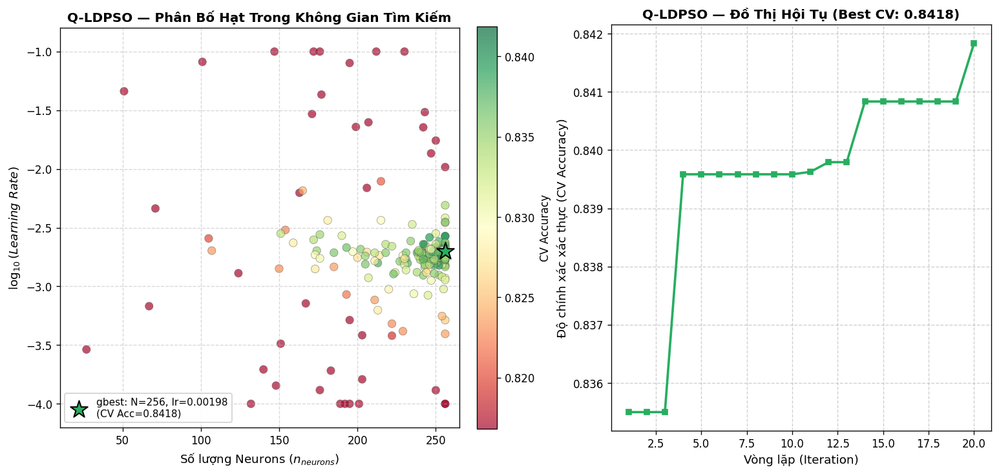

In [ ]:
# Trực quan hóa Không gian tìm kiếm hạt Q-LDPSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_qld['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_qld['n_neurons'], np.log10(hist_qld['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_qld, np.log10(lr_qld), c='#27ae60', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qld}, lr={lr_qld:.5f}\n(CV Acc={cv_qld:.4f})'
)
ax_sc.set_xlim(10, 265)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.set_aspect(abs((265 - 10) / (-0.8 - (-4.2))))
ax_sc.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_sc.set_ylabel('$\log_{10}(Learning\ Rate)$', fontsize=11)
ax_sc.set_title('Q-LDPSO — Hyperparameter Search Space Distribution', fontsize=12, fontweight='bold')
ax_sc.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_sc.grid(True, linestyle='--', alpha=0.5)

# 2. Đồ thị hội tụ (Convergence curve)
ax_co = fig.add_subplot(gs[0, 1])
ax_co.plot(range(1, len(conv_qld) + 1), conv_qld, color='#27ae60', lw=2.2, marker='s', markersize=5)
ax_co.set_xlabel('Iteration', fontsize=11)
ax_co.set_ylabel('Accuracy xác thực (CV Accuracy)', fontsize=11)
ax_co.set_title(f'Q-LDPSO — Đồ Thị Hội Tụ (Best CV: {cv_qld:.4f})', fontsize=12, fontweight='bold')
ax_co.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


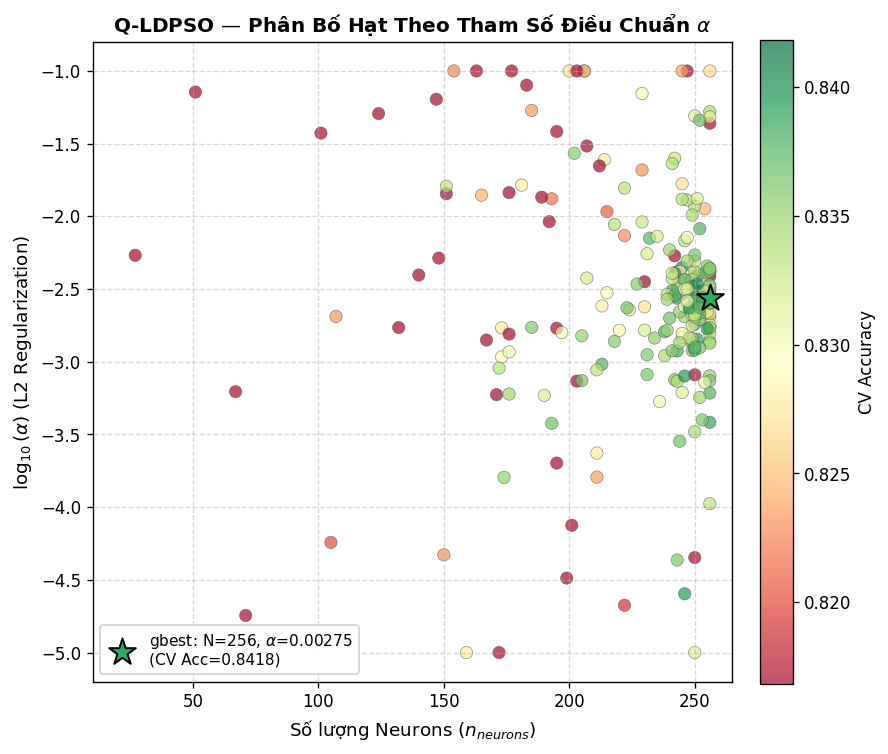

In [ ]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - Q-LDPSO
fig, ax_al_qld = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_qld.scatter(
    hist_qld['n_neurons'], np.log10(hist_qld['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_qld, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_qld.scatter(
    n_qld, np.log10(al_qld), c='#27ae60', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qld}, $\alpha$={al_qld:.5f}\n(CV Acc={cv_qld:.4f})'
)
ax_al_qld.set_xlim(10, 265)
ax_al_qld.set_ylim(-5.2, -0.8)
ax_al_qld.set_aspect(abs((265 - 10) / (-0.8 - (-5.2))))
ax_al_qld.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_al_qld.set_ylabel('$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_qld.set_title('Q-LDPSO — Particle Distribution across L2 Regularization Parameter $\alpha$', fontsize=12, fontweight='bold')
ax_al_qld.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_al_qld.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


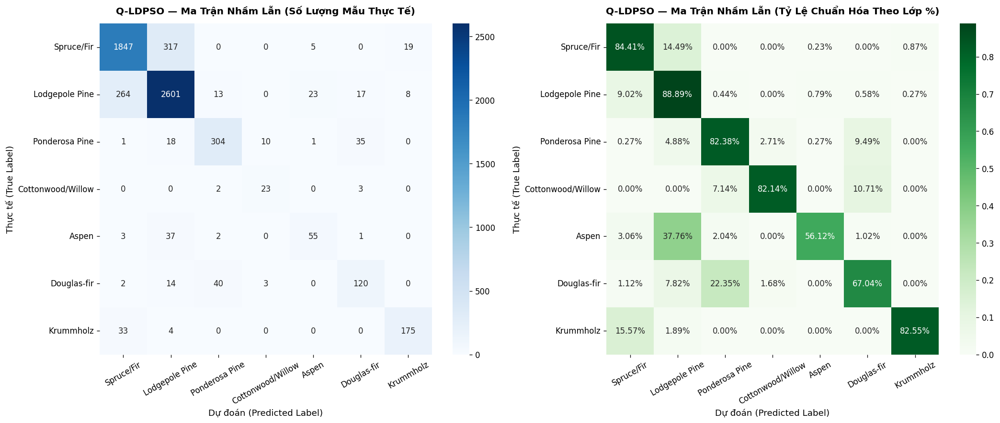

In [ ]:
# Trực quan hoá Ma trận nhầm lẫn Q-LDPSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_qld = mlp_qld.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_qld = confusion_matrix(y_test, y_pred_qld)
cm_qld_norm = cm_qld.astype('float') / cm_qld.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_qld, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('Q-LDPSO — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm1.tick_params(axis='x', rotation=30)

sns.heatmap(cm_qld_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('Q-LDPSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


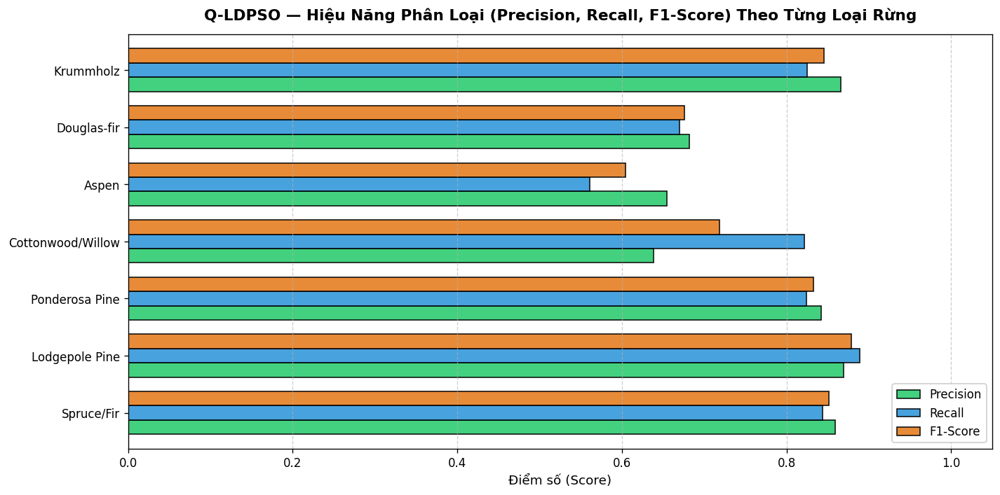

                   precision    recall  f1-score   support

       Spruce/Fir     0.8591    0.8441    0.8515      2188
   Lodgepole Pine     0.8696    0.8889    0.8792      2926
   Ponderosa Pine     0.8421    0.8238    0.8329       369
Cottonwood/Willow     0.6389    0.8214    0.7188        28
            Aspen     0.6548    0.5612    0.6044        98
      Douglas-fir     0.6818    0.6704    0.6761       179
        Krummholz     0.8663    0.8255    0.8454       212

         accuracy                         0.8542      6000
        macro avg     0.7732    0.7765    0.7726      6000
     weighted avg     0.8538    0.8542    0.8538      6000


In [ ]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho Q-LDPSO
report_qld_dict = classification_report(y_test, y_pred_qld, target_names=class_names, digits=4, output_dict=True)

metrics_qld_df = pd.DataFrame({
    'Precision': [report_qld_dict[c]['precision'] for c in class_names],
    'Recall': [report_qld_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_qld_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_qld_df.plot(kind='barh', ax=ax_metrics, color=['#2ecc71', '#3498db', '#e67e22'], width=0.75, edgecolor='black', alpha=0.9)
ax_metrics.set_title('Q-LDPSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_qld, target_names=class_names, digits=4))


---
## 🌀 11. Đánh Giá Biến Thể Quantum + Top-K Mean-Based PSO (Q-MBPSO)
Đánh giá mô hình MLPClassifier tối ưu bằng thuật toán **Quantum + Top-K Mean-Based PSO (Q-MBPSO)** trên tập kiểm thử độc lập (Test Set: 6,000 mẫu).

In [ ]:
# Nạp Checkpoint Q-MBPSO
ckpt_qmb_path = '../results/checkpoints/q_mbpso.pkl'
if not os.path.exists(ckpt_qmb_path):
    ckpt_qmb_path = 'results/checkpoints/q_mbpso.pkl'

if os.path.exists(ckpt_qmb_path):
    qmb_data = joblib.load(ckpt_qmb_path)
    gbest_qmb = qmb_data['gbest_pos']
    cv_qmb = qmb_data['cv_score']
    conv_qmb = qmb_data['convergence']
    hist_qmb = pd.DataFrame(qmb_data['history']) if isinstance(qmb_data['history'], list) else qmb_data['history']

    n_qmb, lr_qmb, al_qmb = decode_position(gbest_qmb)

    print('✅ Nạp thành công checkpoint Q-MBPSO!')
    print(f'   Nghiệm tối ưu: Neurons={n_qmb}, lr={lr_qmb:.5f}, alpha={al_qmb:.6f}')
    print(f'   CV Score     : {cv_qmb:.4f}')
else:
    print(f'❌ Không tìm thấy checkpoint tại {ckpt_qmb_path}')


✅ Nạp thành công checkpoint Q-MBPSO!
   Nghiệm tối ưu: Neurons=238, lr=0.00219, alpha=0.000952
   CV Score     : 0.8414


In [ ]:
# Đánh giá Test cho Q-MBPSO
mlp_qmb_ckpt = '../results/checkpoints/mlp_q_mbpso.pkl'
if not os.path.exists(mlp_qmb_ckpt):
    mlp_qmb_ckpt = 'results/checkpoints/mlp_q_mbpso.pkl'

if os.path.exists(mlp_qmb_ckpt):
    print('📦 Nạp mô hình MLP Q-MBPSO đã huấn luyện sẵn...')
    mlp_qmb = joblib.load(mlp_qmb_ckpt)
    test_qmb = mlp_qmb.score(X_test_sc, y_test)
    train_qmb = mlp_qmb.score(X_train_sc, y_train)
    print(f'  Q-MBPSO                   Train Acc = {train_qmb:.4f} | Test Acc = {test_qmb:.4f} ({test_qmb*100:.2f}%)')
    save_test_accuracy('Q-MBPSO', test_qmb, (n_qmb, lr_qmb, al_qmb), cv_score=cv_qmb)
else:
    mlp_qmb, test_qmb = train_and_evaluate(
        n_qmb, lr_qmb, al_qmb,
        X_train_sc, y_train, X_test_sc, y_test,
        RANDOM_SEED, 'Q-MBPSO', cv_score=cv_qmb
    )
    joblib.dump(mlp_qmb, mlp_qmb_ckpt)


📦 Nạp mô hình MLP Q-MBPSO đã huấn luyện sẵn...
  Q-MBPSO                   Train Acc = 0.9563 | Test Acc = 0.8520 (85.20%)
✅ Đã lưu kết quả 'Q-MBPSO' (Test Acc: 0.8520) vào ../results/test_results/test_accuracy.csv


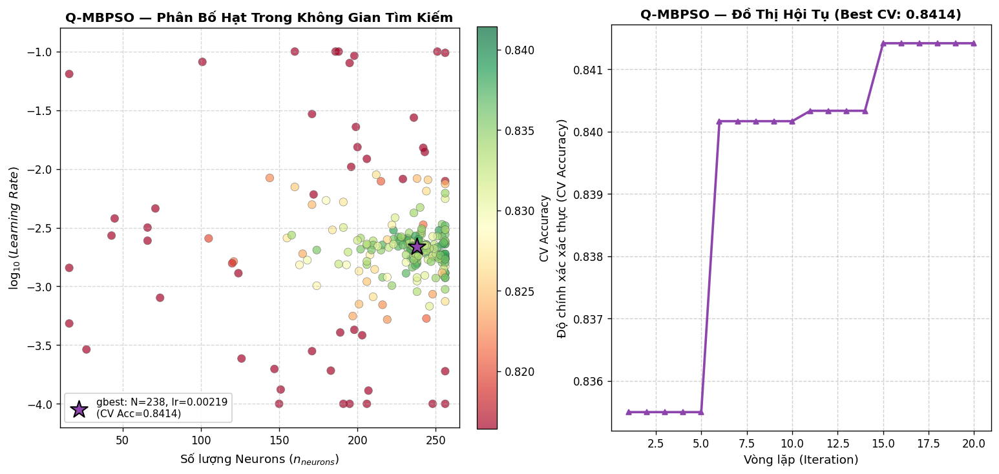

In [ ]:
# Trực quan hóa Không gian tìm kiếm hạt Q-MBPSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_qmb['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_qmb['n_neurons'], np.log10(hist_qmb['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_qmb, np.log10(lr_qmb), c='#8e44ad', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qmb}, lr={lr_qmb:.5f}\n(CV Acc={cv_qmb:.4f})'
)
ax_sc.set_xlim(10, 265)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.set_aspect(abs((265 - 10) / (-0.8 - (-4.2))))
ax_sc.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_sc.set_ylabel('$\log_{10}(Learning\ Rate)$', fontsize=11)
ax_sc.set_title('Q-MBPSO — Hyperparameter Search Space Distribution', fontsize=12, fontweight='bold')
ax_sc.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_sc.grid(True, linestyle='--', alpha=0.5)

# 2. Đồ thị hội tụ (Convergence curve)
ax_co = fig.add_subplot(gs[0, 1])
ax_co.plot(range(1, len(conv_qmb) + 1), conv_qmb, color='#8e44ad', lw=2.2, marker='^', markersize=5)
ax_co.set_xlabel('Iteration', fontsize=11)
ax_co.set_ylabel('Accuracy xác thực (CV Accuracy)', fontsize=11)
ax_co.set_title(f'Q-MBPSO — Đồ Thị Hội Tụ (Best CV: {cv_qmb:.4f})', fontsize=12, fontweight='bold')
ax_co.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


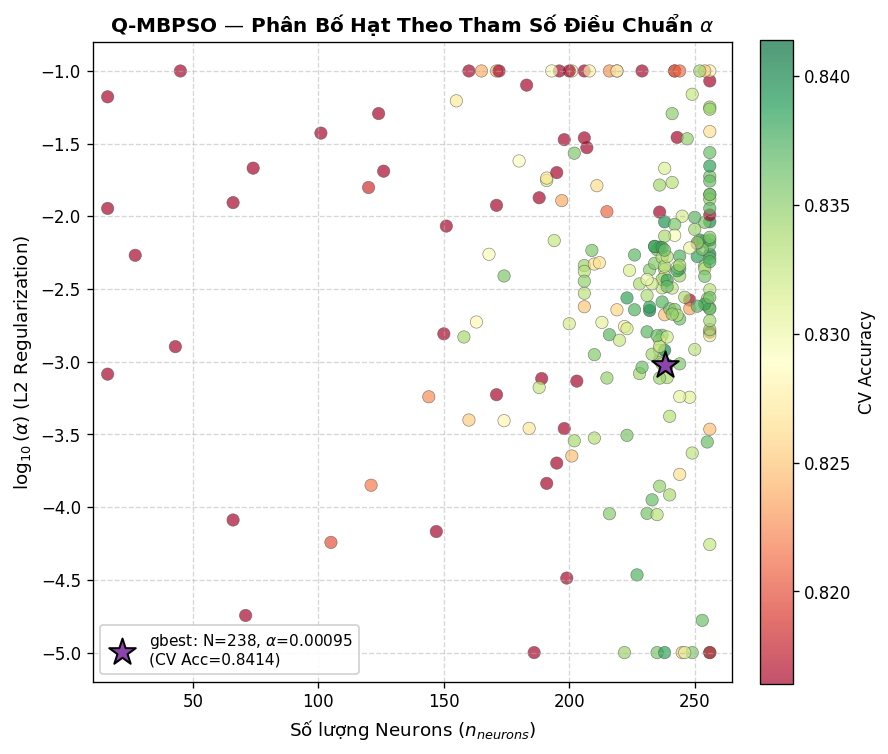

In [ ]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - Q-MBPSO
fig, ax_al_qmb = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_qmb.scatter(
    hist_qmb['n_neurons'], np.log10(hist_qmb['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_qmb, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_qmb.scatter(
    n_qmb, np.log10(al_qmb), c='#8e44ad', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qmb}, $\alpha$={al_qmb:.5f}\n(CV Acc={cv_qmb:.4f})'
)
ax_al_qmb.set_xlim(10, 265)
ax_al_qmb.set_ylim(-5.2, -0.8)
ax_al_qmb.set_aspect(abs((265 - 10) / (-0.8 - (-5.2))))
ax_al_qmb.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_al_qmb.set_ylabel('$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_qmb.set_title('Q-MBPSO — Particle Distribution across L2 Regularization Parameter $\alpha$', fontsize=12, fontweight='bold')
ax_al_qmb.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_al_qmb.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


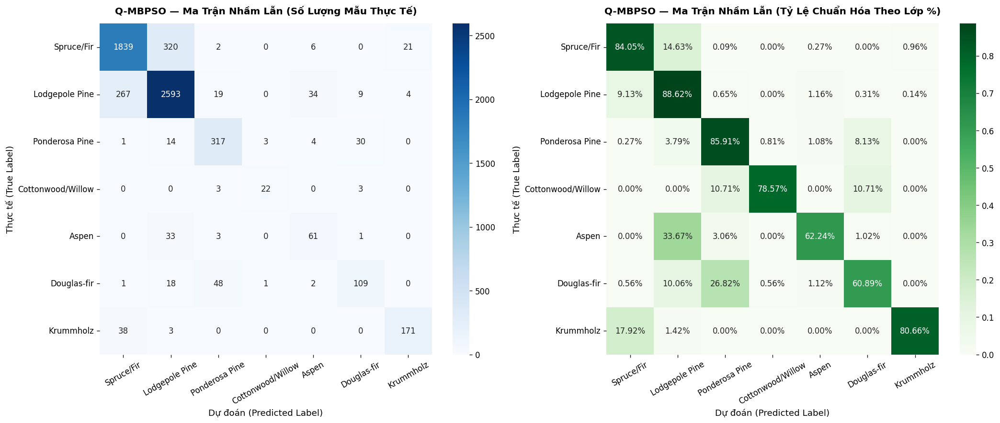

In [ ]:
# Trực quan hoá Ma trận nhầm lẫn Q-MBPSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_qmb = mlp_qmb.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_qmb = confusion_matrix(y_test, y_pred_qmb)
cm_qmb_norm = cm_qmb.astype('float') / cm_qmb.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_qmb, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('Q-MBPSO — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm1.tick_params(axis='x', rotation=30)

sns.heatmap(cm_qmb_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('Q-MBPSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


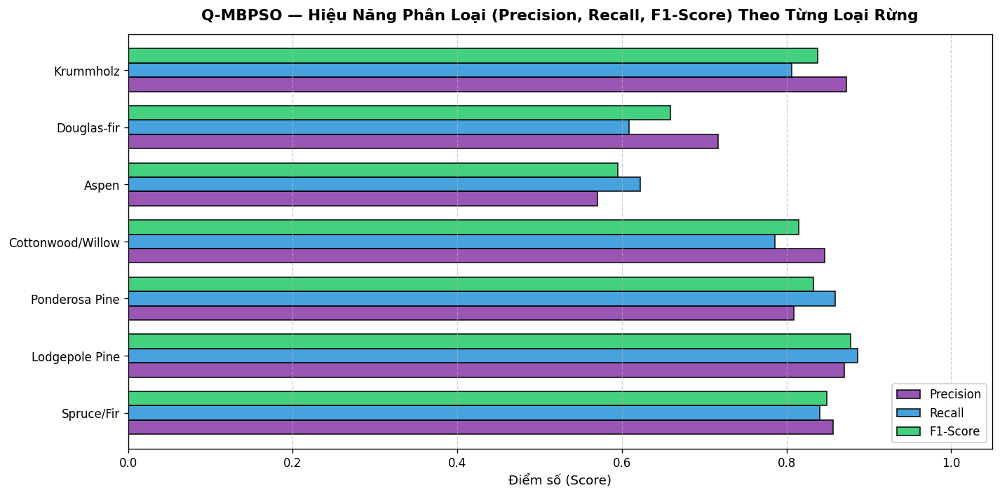

                   precision    recall  f1-score   support

       Spruce/Fir     0.8569    0.8405    0.8486      2188
   Lodgepole Pine     0.8698    0.8862    0.8779      2926
   Ponderosa Pine     0.8087    0.8591    0.8331       369
Cottonwood/Willow     0.8462    0.7857    0.8148        28
            Aspen     0.5701    0.6224    0.5951        98
      Douglas-fir     0.7171    0.6089    0.6586       179
        Krummholz     0.8724    0.8066    0.8382       212

         accuracy                         0.8520      6000
        macro avg     0.7916    0.7728    0.7809      6000
     weighted avg     0.8519    0.8520    0.8516      6000


In [ ]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho Q-MBPSO
report_qmb_dict = classification_report(y_test, y_pred_qmb, target_names=class_names, digits=4, output_dict=True)

metrics_qmb_df = pd.DataFrame({
    'Precision': [report_qmb_dict[c]['precision'] for c in class_names],
    'Recall': [report_qmb_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_qmb_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_qmb_df.plot(kind='barh', ax=ax_metrics, color=['#8e44ad', '#3498db', '#2ecc71'], width=0.75, edgecolor='black', alpha=0.9)
ax_metrics.set_title('Q-MBPSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_qmb, target_names=class_names, digits=4))


---
## 🚀 12. Đánh Giá Biến Thể QPSO với Adaptive $\beta$ Phi Tuyến (Cosine Annealing Beta)
Đánh giá mô hình MLPClassifier tối ưu bằng thuật toán **QPSO Nonlinear (Cosine Annealing Beta)** trên tập kiểm thử độc lập (Test Set: 6,000 mẫu).

In [50]:
# Nạp Checkpoint QPSO Nonlinear
ckpt_qpso_nl_path = '../results/checkpoints/qpso_nonlinear.pkl'
if not os.path.exists(ckpt_qpso_nl_path):
    ckpt_qpso_nl_path = 'results/checkpoints/qpso_nonlinear.pkl'

if os.path.exists(ckpt_qpso_nl_path):
    qpso_nl_data = joblib.load(ckpt_qpso_nl_path)
    gbest_qpso_nl = qpso_nl_data['gbest_pos']
    cv_qpso_nl = qpso_nl_data['cv_score']
    conv_qpso_nl = qpso_nl_data['convergence']
    hist_qpso_nl = pd.DataFrame(qpso_nl_data['history']) if isinstance(qpso_nl_data['history'], list) else qpso_nl_data['history']
    beta_hist_qpso_nl = qpso_nl_data.get('beta_history', None)

    n_qpso_nl, lr_qpso_nl, al_qpso_nl = decode_position(gbest_qpso_nl)

    print('✅ Nạp thành công checkpoint QPSO Nonlinear!')
    print(f'   Nghiệm tối ưu: Neurons={n_qpso_nl}, lr={lr_qpso_nl:.5f}, alpha={al_qpso_nl:.6f}')
    print(f'   CV Score     : {cv_qpso_nl:.4f}')
else:
    print(f'❌ Không tìm thấy checkpoint tại {ckpt_qpso_nl_path}')

✅ Nạp thành công checkpoint QPSO Nonlinear!
   Nghiệm tối ưu: Neurons=255, lr=0.00231, alpha=0.000010
   CV Score     : 0.8414


In [51]:
# Đánh giá Test cho QPSO Nonlinear
mlp_qpso_nl_ckpt = '../results/checkpoints/mlp_qpso_nonlinear.pkl'
if not os.path.exists(mlp_qpso_nl_ckpt):
    mlp_qpso_nl_ckpt = 'results/checkpoints/mlp_qpso_nonlinear.pkl'

if os.path.exists(mlp_qpso_nl_ckpt):
    print('📦 Nạp mô hình MLP QPSO Nonlinear đã huấn luyện sẵn...')
    mlp_qpso_nl = joblib.load(mlp_qpso_nl_ckpt)
    test_qpso_nl = mlp_qpso_nl.score(X_test_sc, y_test)
    train_qpso_nl = mlp_qpso_nl.score(X_train_sc, y_train)
    print(f'  QPSO Nonlinear            Train Acc = {train_qpso_nl:.4f} | Test Acc = {test_qpso_nl:.4f} ({test_qpso_nl*100:.2f}%)')
    save_test_accuracy('QPSO Nonlinear', test_qpso_nl, (n_qpso_nl, lr_qpso_nl, al_qpso_nl), cv_score=cv_qpso_nl)
else:
    mlp_qpso_nl, test_qpso_nl = train_and_evaluate(
        n_qpso_nl, lr_qpso_nl, al_qpso_nl,
        X_train_sc, y_train, X_test_sc, y_test,
        RANDOM_SEED, 'QPSO Nonlinear', cv_score=cv_qpso_nl
    )
    joblib.dump(mlp_qpso_nl, mlp_qpso_nl_ckpt)

📦 Nạp mô hình MLP QPSO Nonlinear đã huấn luyện sẵn...
  QPSO Nonlinear            Train Acc = 0.9565 | Test Acc = 0.8492 (84.92%)
✅ Đã lưu kết quả 'QPSO Nonlinear' (Test Acc: 0.8492) vào ../results/test_results/test_accuracy.csv


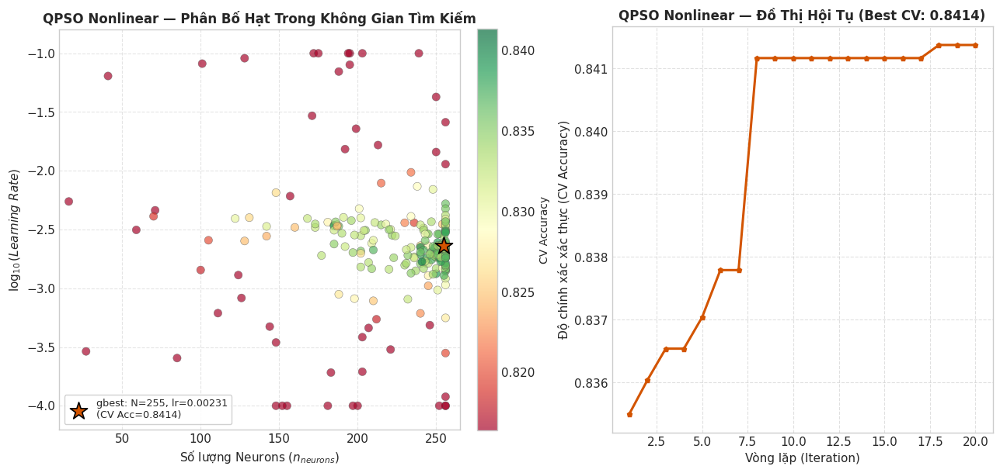

In [52]:
# Trực quan hóa Không gian tìm kiếm hạt QPSO Nonlinear (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_qpso_nl['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_qpso_nl['n_neurons'], np.log10(hist_qpso_nl['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_qpso_nl, np.log10(lr_qpso_nl), c='#d35400', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qpso_nl}, lr={lr_qpso_nl:.5f}\n(CV Acc={cv_qpso_nl:.4f})'
)
ax_sc.set_xlim(10, 265)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.set_aspect(abs((265 - 10) / (-0.8 - (-4.2))))
ax_sc.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_sc.set_ylabel('$\\log_{10}(Learning\\ Rate)$', fontsize=11)
ax_sc.set_title('QPSO Nonlinear — Hyperparameter Search Space Distribution', fontsize=12, fontweight='bold')
ax_sc.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_sc.grid(True, linestyle='--', alpha=0.5)

# 2. Đồ thị hội tụ (Convergence curve)
ax_co = fig.add_subplot(gs[0, 1])
ax_co.plot(range(1, len(conv_qpso_nl) + 1), conv_qpso_nl, color='#d35400', lw=2.2, marker='p', markersize=5)
ax_co.set_xlabel('Iteration', fontsize=11)
ax_co.set_ylabel('Accuracy xác thực (CV Accuracy)', fontsize=11)
ax_co.set_title(f'QPSO Nonlinear — Đồ Thị Hội Tụ (Best CV: {cv_qpso_nl:.4f})', fontsize=12, fontweight='bold')
ax_co.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

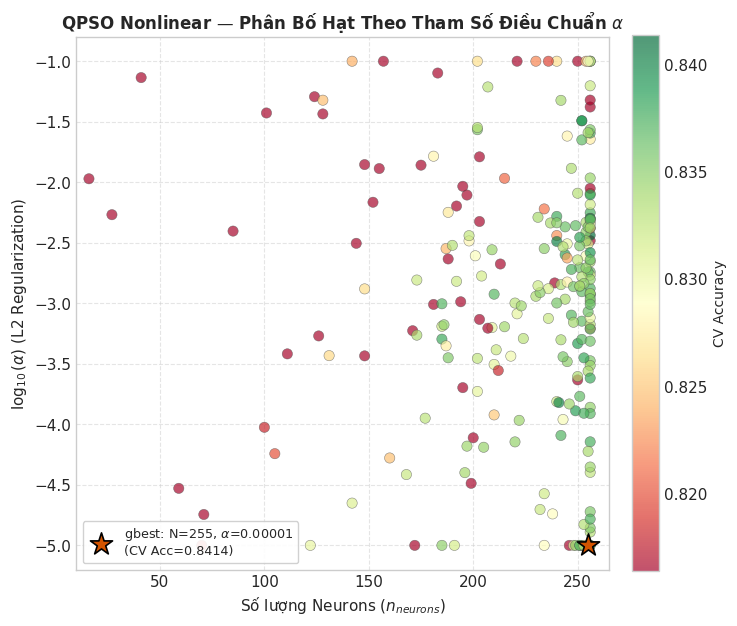

In [53]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - QPSO Nonlinear
fig, ax_al_qnl = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_qnl.scatter(
    hist_qpso_nl['n_neurons'], np.log10(hist_qpso_nl['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_qnl, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_qnl.scatter(
    n_qpso_nl, np.log10(al_qpso_nl), c='#d35400', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qpso_nl}, $\\alpha$={al_qpso_nl:.5f}\n(CV Acc={cv_qpso_nl:.4f})'
)
ax_al_qnl.set_xlim(10, 265)
ax_al_qnl.set_ylim(-5.2, -0.8)
ax_al_qnl.set_aspect(abs((265 - 10) / (-0.8 - (-5.2))))
ax_al_qnl.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_al_qnl.set_ylabel('$\\log_{10}(\\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_qnl.set_title('QPSO Nonlinear — Particle Distribution across L2 Regularization Parameter $\\alpha$', fontsize=12, fontweight='bold')
ax_al_qnl.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_al_qnl.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

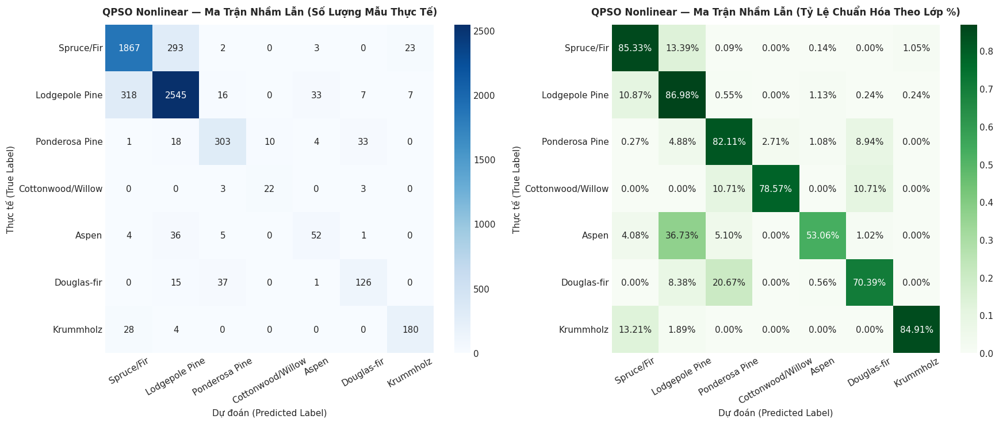

In [54]:
# Trực quan hoá Ma trận nhầm lẫn QPSO Nonlinear: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_qnl = mlp_qpso_nl.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_qnl = confusion_matrix(y_test, y_pred_qnl)
cm_qnl_norm = cm_qnl.astype('float') / cm_qnl.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_qnl, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('QPSO Nonlinear — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm1.tick_params(axis='x', rotation=30)

sns.heatmap(cm_qnl_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('QPSO Nonlinear — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

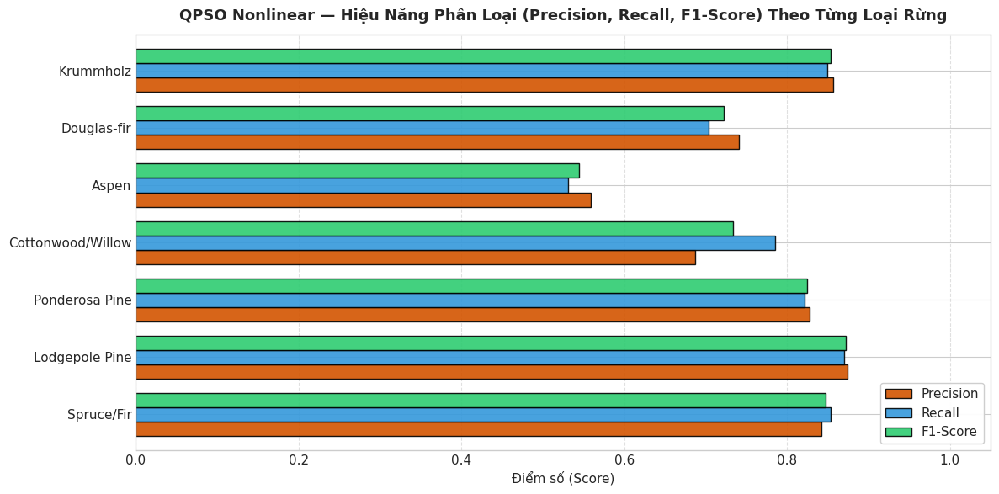

                   precision    recall  f1-score   support

       Spruce/Fir     0.8417    0.8533    0.8475      2188
   Lodgepole Pine     0.8743    0.8698    0.8720      2926
   Ponderosa Pine     0.8279    0.8211    0.8245       369
Cottonwood/Willow     0.6875    0.7857    0.7333        28
            Aspen     0.5591    0.5306    0.5445        98
      Douglas-fir     0.7412    0.7039    0.7221       179
        Krummholz     0.8571    0.8491    0.8531       212

         accuracy                         0.8492      6000
        macro avg     0.7698    0.7734    0.7710      6000
     weighted avg     0.8490    0.8492    0.8490      6000


In [55]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho QPSO Nonlinear
report_qnl_dict = classification_report(y_test, y_pred_qnl, target_names=class_names, digits=4, output_dict=True)

metrics_qnl_df = pd.DataFrame({
    'Precision': [report_qnl_dict[c]['precision'] for c in class_names],
    'Recall': [report_qnl_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_qnl_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_qnl_df.plot(kind='barh', ax=ax_metrics, color=['#d35400', '#3498db', '#2ecc71'], width=0.75, edgecolor='black', alpha=0.9)
ax_metrics.set_title('QPSO Nonlinear — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_qnl, target_names=class_names, digits=4))

---
## 🚀 13. Đánh Giá Biến Thể QPSO với Fitness-Adaptive $\beta$ (Thích ứng theo tiến trình hội tụ)
Đánh giá mô hình MLPClassifier tối ưu bằng thuật toán **QPSO Adaptive (Fitness-Adaptive Beta)** trên tập kiểm thử độc lập (Test Set: 6,000 mẫu).

In [56]:
# Nạp Checkpoint QPSO Adaptive
ckpt_qpso_ad_path = '../results/checkpoints/qpso_adaptive.pkl'
if not os.path.exists(ckpt_qpso_ad_path):
    ckpt_qpso_ad_path = 'results/checkpoints/qpso_adaptive.pkl'

if os.path.exists(ckpt_qpso_ad_path):
    qpso_ad_data = joblib.load(ckpt_qpso_ad_path)
    gbest_qpso_ad = qpso_ad_data['gbest_pos']
    cv_qpso_ad = qpso_ad_data['cv_score']
    conv_qpso_ad = qpso_ad_data['convergence']
    hist_qpso_ad = pd.DataFrame(qpso_ad_data['history']) if isinstance(qpso_ad_data['history'], list) else qpso_ad_data['history']
    beta_hist_qpso_ad = qpso_ad_data.get('beta_history', None)

    n_qpso_ad, lr_qpso_ad, al_qpso_ad = decode_position(gbest_qpso_ad)

    print('✅ Nạp thành công checkpoint QPSO Adaptive!')
    print(f'   Nghiệm tối ưu: Neurons={n_qpso_ad}, lr={lr_qpso_ad:.5f}, alpha={al_qpso_ad:.6f}')
    print(f'   CV Score     : {cv_qpso_ad:.4f}')
else:
    print(f'❌ Không tìm thấy checkpoint tại {ckpt_qpso_ad_path}')

✅ Nạp thành công checkpoint QPSO Adaptive!
   Nghiệm tối ưu: Neurons=256, lr=0.00121, alpha=0.014380
   CV Score     : 0.8409


In [57]:
# Đánh giá Test cho QPSO Adaptive
mlp_qpso_ad_ckpt = '../results/checkpoints/mlp_qpso_adaptive.pkl'
if not os.path.exists(mlp_qpso_ad_ckpt):
    mlp_qpso_ad_ckpt = 'results/checkpoints/mlp_qpso_adaptive.pkl'

if os.path.exists(mlp_qpso_ad_ckpt):
    print('📦 Nạp mô hình MLP QPSO Adaptive đã huấn luyện sẵn...')
    mlp_qpso_ad = joblib.load(mlp_qpso_ad_ckpt)
    test_qpso_ad = mlp_qpso_ad.score(X_test_sc, y_test)
    train_qpso_ad = mlp_qpso_ad.score(X_train_sc, y_train)
    print(f'  QPSO Adaptive             Train Acc = {train_qpso_ad:.4f} | Test Acc = {test_qpso_ad:.4f} ({test_qpso_ad*100:.2f}%)')
    save_test_accuracy('QPSO Adaptive', test_qpso_ad, (n_qpso_ad, lr_qpso_ad, al_qpso_ad), cv_score=cv_qpso_ad)
else:
    mlp_qpso_ad, test_qpso_ad = train_and_evaluate(
        n_qpso_ad, lr_qpso_ad, al_qpso_ad,
        X_train_sc, y_train, X_test_sc, y_test,
        RANDOM_SEED, 'QPSO Adaptive', cv_score=cv_qpso_ad
    )
    joblib.dump(mlp_qpso_ad, mlp_qpso_ad_ckpt)

📦 Nạp mô hình MLP QPSO Adaptive đã huấn luyện sẵn...
  QPSO Adaptive             Train Acc = 0.9432 | Test Acc = 0.8490 (84.90%)
✅ Đã lưu kết quả 'QPSO Adaptive' (Test Acc: 0.8490) vào ../results/test_results/test_accuracy.csv


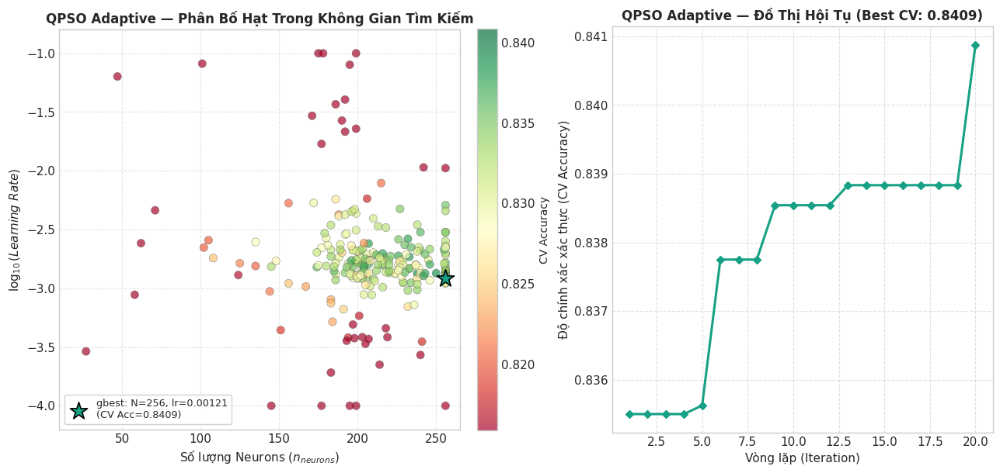

In [58]:
# Trực quan hóa Không gian tìm kiếm hạt QPSO Adaptive (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_qpso_ad['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_qpso_ad['n_neurons'], np.log10(hist_qpso_ad['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_qpso_ad, np.log10(lr_qpso_ad), c='#16a085', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qpso_ad}, lr={lr_qpso_ad:.5f}\n(CV Acc={cv_qpso_ad:.4f})'
)
ax_sc.set_xlim(10, 265)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.set_aspect(abs((265 - 10) / (-0.8 - (-4.2))))
ax_sc.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_sc.set_ylabel('$\\log_{10}(Learning\\ Rate)$', fontsize=11)
ax_sc.set_title('QPSO Adaptive — Hyperparameter Search Space Distribution', fontsize=12, fontweight='bold')
ax_sc.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_sc.grid(True, linestyle='--', alpha=0.5)

# 2. Đồ thị hội tụ (Convergence curve)
ax_co = fig.add_subplot(gs[0, 1])
ax_co.plot(range(1, len(conv_qpso_ad) + 1), conv_qpso_ad, color='#16a085', lw=2.2, marker='D', markersize=5)
ax_co.set_xlabel('Iteration', fontsize=11)
ax_co.set_ylabel('Accuracy xác thực (CV Accuracy)', fontsize=11)
ax_co.set_title(f'QPSO Adaptive — Đồ Thị Hội Tụ (Best CV: {cv_qpso_ad:.4f})', fontsize=12, fontweight='bold')
ax_co.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

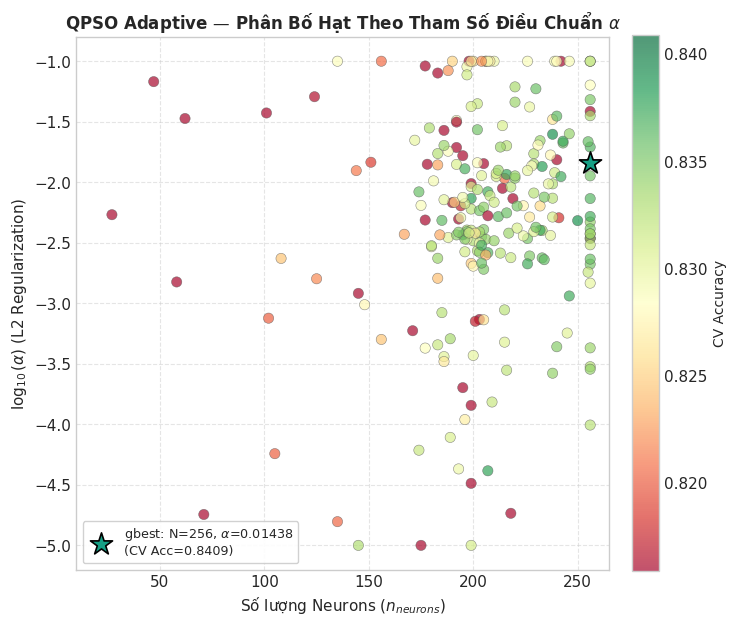

In [59]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - QPSO Adaptive
fig, ax_al_qad = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_qad.scatter(
    hist_qpso_ad['n_neurons'], np.log10(hist_qpso_ad['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_qad, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_qad.scatter(
    n_qpso_ad, np.log10(al_qpso_ad), c='#16a085', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qpso_ad}, $\\alpha$={al_qpso_ad:.5f}\n(CV Acc={cv_qpso_ad:.4f})'
)
ax_al_qad.set_xlim(10, 265)
ax_al_qad.set_ylim(-5.2, -0.8)
ax_al_qad.set_aspect(abs((265 - 10) / (-0.8 - (-5.2))))
ax_al_qad.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_al_qad.set_ylabel('$\\log_{10}(\\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_qad.set_title('QPSO Adaptive — Particle Distribution across L2 Regularization Parameter $\\alpha$', fontsize=12, fontweight='bold')
ax_al_qad.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_al_qad.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

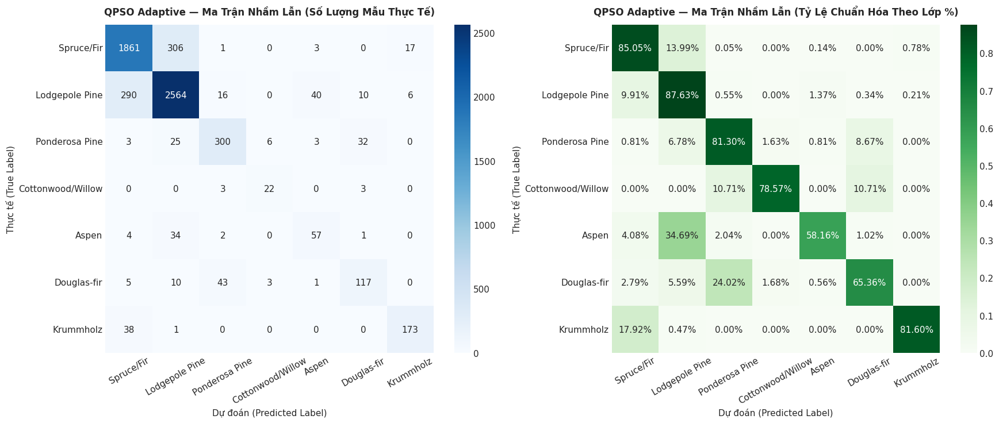

In [60]:
# Trực quan hoá Ma trận nhầm lẫn QPSO Adaptive: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_qad = mlp_qpso_ad.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_qad = confusion_matrix(y_test, y_pred_qad)
cm_qad_norm = cm_qad.astype('float') / cm_qad.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_qad, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('QPSO Adaptive — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm1.tick_params(axis='x', rotation=30)

sns.heatmap(cm_qad_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('QPSO Adaptive — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

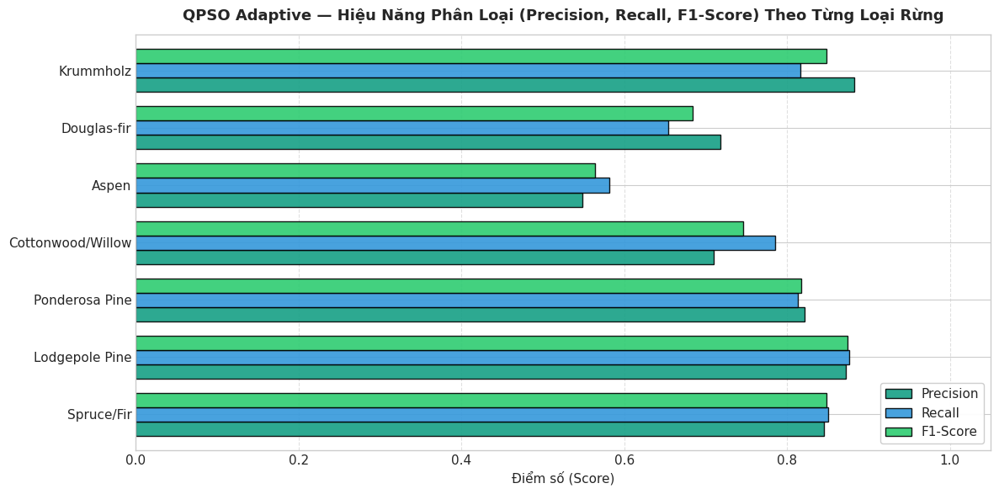

                   precision    recall  f1-score   support

       Spruce/Fir     0.8455    0.8505    0.8480      2188
   Lodgepole Pine     0.8721    0.8763    0.8742      2926
   Ponderosa Pine     0.8219    0.8130    0.8174       369
Cottonwood/Willow     0.7097    0.7857    0.7458        28
            Aspen     0.5481    0.5816    0.5644        98
      Douglas-fir     0.7178    0.6536    0.6842       179
        Krummholz     0.8827    0.8160    0.8480       212

         accuracy                         0.8490      6000
        macro avg     0.7711    0.7681    0.7689      6000
     weighted avg     0.8490    0.8490    0.8489      6000


In [61]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho QPSO Adaptive
report_qad_dict = classification_report(y_test, y_pred_qad, target_names=class_names, digits=4, output_dict=True)

metrics_qad_df = pd.DataFrame({
    'Precision': [report_qad_dict[c]['precision'] for c in class_names],
    'Recall': [report_qad_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_qad_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_qad_df.plot(kind='barh', ax=ax_metrics, color=['#16a085', '#3498db', '#2ecc71'], width=0.75, edgecolor='black', alpha=0.9)
ax_metrics.set_title('QPSO Adaptive — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_qad, target_names=class_names, digits=4))

---
## 🚀 14. Đánh Giá Biến Thể QPSO với Per-particle $\beta$ (Thích ứng theo khoảng cách từng hạt)
Đánh giá mô hình MLPClassifier tối ưu bằng thuật toán **QPSO Per-Particle** trên tập kiểm thử độc lập (Test Set: 6,000 mẫu).

In [62]:
# Nạp Checkpoint QPSO Per-Particle
ckpt_qpso_pp_path = '../results/checkpoints/qpso_per_particle.pkl'
if not os.path.exists(ckpt_qpso_pp_path):
    ckpt_qpso_pp_path = 'results/checkpoints/qpso_per_particle.pkl'

if os.path.exists(ckpt_qpso_pp_path):
    qpso_pp_data = joblib.load(ckpt_qpso_pp_path)
    gbest_qpso_pp = qpso_pp_data['gbest_pos']
    cv_qpso_pp = qpso_pp_data['cv_score']
    conv_qpso_pp = qpso_pp_data['convergence']
    hist_qpso_pp = pd.DataFrame(qpso_pp_data['history']) if isinstance(qpso_pp_data['history'], list) else qpso_pp_data['history']
    beta_hist_qpso_pp = qpso_pp_data.get('avg_beta_history', None)

    n_qpso_pp, lr_qpso_pp, al_qpso_pp = decode_position(gbest_qpso_pp)

    print('✅ Nạp thành công checkpoint QPSO Per-Particle!')
    print(f'   Nghiệm tối ưu: Neurons={n_qpso_pp}, lr={lr_qpso_pp:.5f}, alpha={al_qpso_pp:.6f}')
    print(f'   CV Score     : {cv_qpso_pp:.4f}')
else:
    print(f'❌ Không tìm thấy checkpoint tại {ckpt_qpso_pp_path}')

✅ Nạp thành công checkpoint QPSO Per-Particle!
   Nghiệm tối ưu: Neurons=252, lr=0.00111, alpha=0.003336
   CV Score     : 0.8410


In [63]:
# Đánh giá Test cho QPSO Per-Particle
mlp_qpso_pp_ckpt = '../results/checkpoints/mlp_qpso_per_particle.pkl'
if not os.path.exists(mlp_qpso_pp_ckpt):
    mlp_qpso_pp_ckpt = 'results/checkpoints/mlp_qpso_per_particle.pkl'

if os.path.exists(mlp_qpso_pp_ckpt):
    print('📦 Nạp mô hình MLP QPSO Per-Particle đã huấn luyện sẵn...')
    mlp_qpso_pp = joblib.load(mlp_qpso_pp_ckpt)
    test_qpso_pp = mlp_qpso_pp.score(X_test_sc, y_test)
    train_qpso_pp = mlp_qpso_pp.score(X_train_sc, y_train)
    print(f'  QPSO Per-Particle         Train Acc = {train_qpso_pp:.4f} | Test Acc = {test_qpso_pp:.4f} ({test_qpso_pp*100:.2f}%)')
    save_test_accuracy('QPSO Per-Particle', test_qpso_pp, (n_qpso_pp, lr_qpso_pp, al_qpso_pp), cv_score=cv_qpso_pp)
else:
    mlp_qpso_pp, test_qpso_pp = train_and_evaluate(
        n_qpso_pp, lr_qpso_pp, al_qpso_pp,
        X_train_sc, y_train, X_test_sc, y_test,
        RANDOM_SEED, 'QPSO Per-Particle', cv_score=cv_qpso_pp
    )
    joblib.dump(mlp_qpso_pp, mlp_qpso_pp_ckpt)

📦 Nạp mô hình MLP QPSO Per-Particle đã huấn luyện sẵn...
  QPSO Per-Particle         Train Acc = 0.9346 | Test Acc = 0.8515 (85.15%)
✅ Đã lưu kết quả 'QPSO Per-Particle' (Test Acc: 0.8515) vào ../results/test_results/test_accuracy.csv


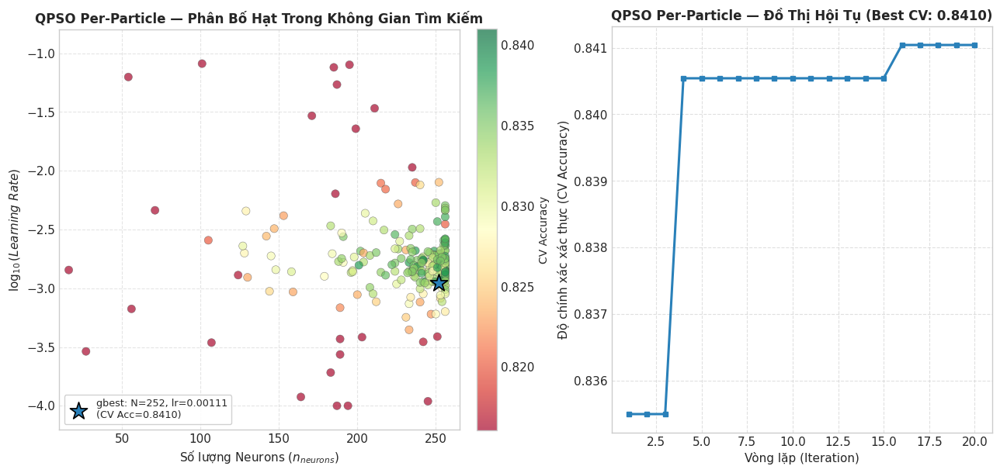

In [64]:
# Trực quan hóa Không gian tìm kiếm hạt QPSO Per-Particle (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_qpso_pp['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_qpso_pp['n_neurons'], np.log10(hist_qpso_pp['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_qpso_pp, np.log10(lr_qpso_pp), c='#2980b9', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qpso_pp}, lr={lr_qpso_pp:.5f}\n(CV Acc={cv_qpso_pp:.4f})'
)
ax_sc.set_xlim(10, 265)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.set_aspect(abs((265 - 10) / (-0.8 - (-4.2))))
ax_sc.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_sc.set_ylabel('$\\log_{10}(Learning\\ Rate)$', fontsize=11)
ax_sc.set_title('QPSO Per-Particle — Hyperparameter Search Space Distribution', fontsize=12, fontweight='bold')
ax_sc.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_sc.grid(True, linestyle='--', alpha=0.5)

# 2. Đồ thị hội tụ (Convergence curve)
ax_co = fig.add_subplot(gs[0, 1])
ax_co.plot(range(1, len(conv_qpso_pp) + 1), conv_qpso_pp, color='#2980b9', lw=2.2, marker='s', markersize=5)
ax_co.set_xlabel('Iteration', fontsize=11)
ax_co.set_ylabel('Accuracy xác thực (CV Accuracy)', fontsize=11)
ax_co.set_title(f'QPSO Per-Particle — Đồ Thị Hội Tụ (Best CV: {cv_qpso_pp:.4f})', fontsize=12, fontweight='bold')
ax_co.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

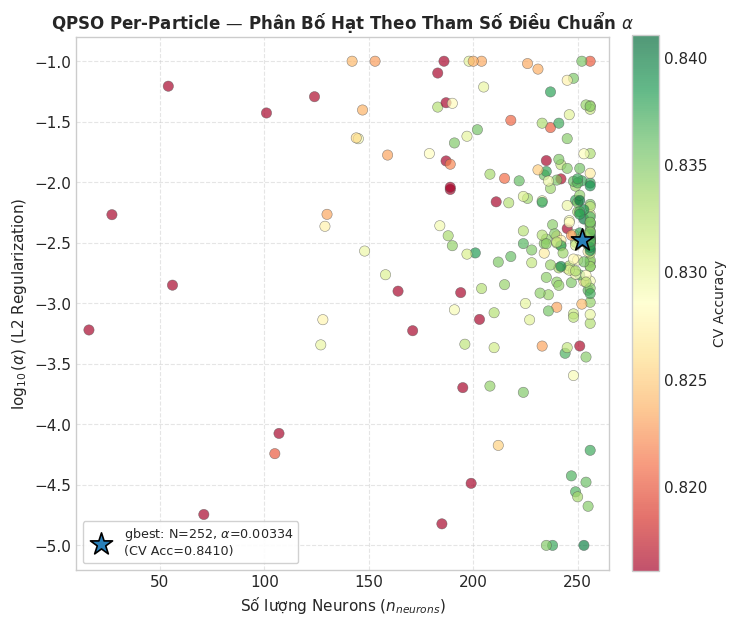

In [65]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - QPSO Per-Particle
fig, ax_al_qpp = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_qpp.scatter(
    hist_qpso_pp['n_neurons'], np.log10(hist_qpso_pp['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_qpp, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_qpp.scatter(
    n_qpso_pp, np.log10(al_qpso_pp), c='#2980b9', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_qpso_pp}, $\\alpha$={al_qpso_pp:.5f}\n(CV Acc={cv_qpso_pp:.4f})'
)
ax_al_qpp.set_xlim(10, 265)
ax_al_qpp.set_ylim(-5.2, -0.8)
ax_al_qpp.set_aspect(abs((265 - 10) / (-0.8 - (-5.2))))
ax_al_qpp.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_al_qpp.set_ylabel('$\\log_{10}(\\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_qpp.set_title('QPSO Per-Particle — Particle Distribution across L2 Regularization Parameter $\\alpha$', fontsize=12, fontweight='bold')
ax_al_qpp.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_al_qpp.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

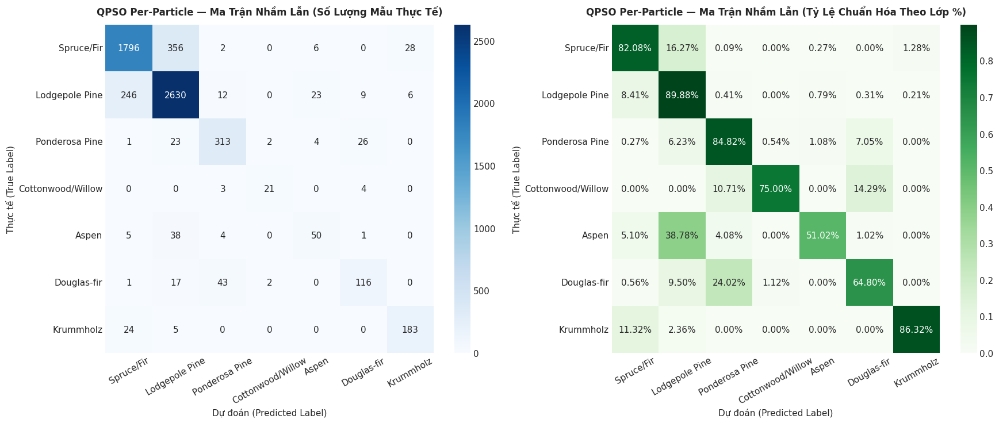

In [66]:
# Trực quan hoá Ma trận nhầm lẫn QPSO Per-Particle: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_qpp = mlp_qpso_pp.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_qpp = confusion_matrix(y_test, y_pred_qpp)
cm_qpp_norm = cm_qpp.astype('float') / cm_qpp.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_qpp, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('QPSO Per-Particle — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm1.tick_params(axis='x', rotation=30)

sns.heatmap(cm_qpp_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('QPSO Per-Particle — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

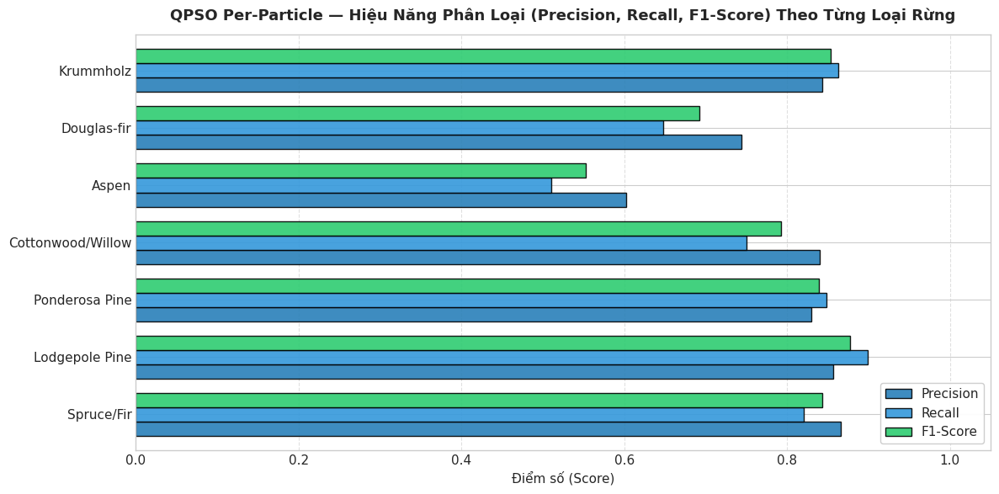

                   precision    recall  f1-score   support

       Spruce/Fir     0.8664    0.8208    0.8430      2188
   Lodgepole Pine     0.8570    0.8988    0.8774      2926
   Ponderosa Pine     0.8302    0.8482    0.8391       369
Cottonwood/Willow     0.8400    0.7500    0.7925        28
            Aspen     0.6024    0.5102    0.5525        98
      Douglas-fir     0.7436    0.6480    0.6925       179
        Krummholz     0.8433    0.8632    0.8531       212

         accuracy                         0.8515      6000
        macro avg     0.7976    0.7628    0.7786      6000
     weighted avg     0.8506    0.8515    0.8504      6000


In [67]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho QPSO Per-Particle
report_qpp_dict = classification_report(y_test, y_pred_qpp, target_names=class_names, digits=4, output_dict=True)

metrics_qpp_df = pd.DataFrame({
    'Precision': [report_qpp_dict[c]['precision'] for c in class_names],
    'Recall': [report_qpp_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_qpp_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_qpp_df.plot(kind='barh', ax=ax_metrics, color=['#2980b9', '#3498db', '#2ecc71'], width=0.75, edgecolor='black', alpha=0.9)
ax_metrics.set_title('QPSO Per-Particle — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_qpp, target_names=class_names, digits=4))

---
## 🚀 15. Đánh Giá Biến Thể Opposition-Based Quantum PSO (OQ-PSO)
Đánh giá mô hình MLPClassifier tối ưu bằng thuật toán **OQ-PSO (Opposition-Based Quantum PSO)** trên tập kiểm thử độc lập (Test Set: 6,000 mẫu).

In [68]:
# Nạp Checkpoint OQ-PSO
ckpt_oq_pso_path = '../results/checkpoints/oq_pso.pkl'
if not os.path.exists(ckpt_oq_pso_path):
    ckpt_oq_pso_path = 'results/checkpoints/oq_pso.pkl'

if os.path.exists(ckpt_oq_pso_path):
    oqpso_data = joblib.load(ckpt_oq_pso_path)
    gbest_oqpso = oqpso_data['gbest_pos']
    cv_oqpso = oqpso_data['cv_score']
    conv_oqpso = oqpso_data['convergence']
    hist_oqpso = pd.DataFrame(oqpso_data['history']) if isinstance(oqpso_data['history'], list) else oqpso_data['history']

    n_oqpso, lr_oqpso, al_oqpso = decode_position(gbest_oqpso)

    print('✅ Nạp thành công checkpoint OQ-PSO!')
    print(f'   Nghiệm tối ưu: Neurons={n_oqpso}, lr={lr_oqpso:.5f}, alpha={al_oqpso:.6f}')
    print(f'   CV Score     : {cv_oqpso:.4f}')
else:
    print(f'❌ Không tìm thấy checkpoint tại {ckpt_oq_pso_path}')

✅ Nạp thành công checkpoint OQ-PSO!
   Nghiệm tối ưu: Neurons=250, lr=0.00260, alpha=0.000208
   CV Score     : 0.8399


In [69]:
# Đánh giá Test cho OQ-PSO
mlp_oqpso_ckpt = '../results/checkpoints/mlp_oq_pso.pkl'
if not os.path.exists(mlp_oqpso_ckpt):
    mlp_oqpso_ckpt = 'results/checkpoints/mlp_oq_pso.pkl'

if os.path.exists(mlp_oqpso_ckpt):
    print('📦 Nạp mô hình MLP OQ-PSO đã huấn luyện sẵn...')
    mlp_oqpso = joblib.load(mlp_oqpso_ckpt)
    test_oqpso = mlp_oqpso.score(X_test_sc, y_test)
    train_oqpso = mlp_oqpso.score(X_train_sc, y_train)
    print(f'  OQ-PSO                    Train Acc = {train_oqpso:.4f} | Test Acc = {test_oqpso:.4f} ({test_oqpso*100:.2f}%)')
    save_test_accuracy('OQ-PSO', test_oqpso, (n_oqpso, lr_oqpso, al_oqpso), cv_score=cv_oqpso)
else:
    mlp_oqpso, test_oqpso = train_and_evaluate(
        n_oqpso, lr_oqpso, al_oqpso,
        X_train_sc, y_train, X_test_sc, y_test,
        RANDOM_SEED, 'OQ-PSO', cv_score=cv_oqpso
    )
    joblib.dump(mlp_oqpso, mlp_oqpso_ckpt)

📦 Nạp mô hình MLP OQ-PSO đã huấn luyện sẵn...
  OQ-PSO                    Train Acc = 0.9334 | Test Acc = 0.8497 (84.97%)
✅ Đã lưu kết quả 'OQ-PSO' (Test Acc: 0.8497) vào ../results/test_results/test_accuracy.csv


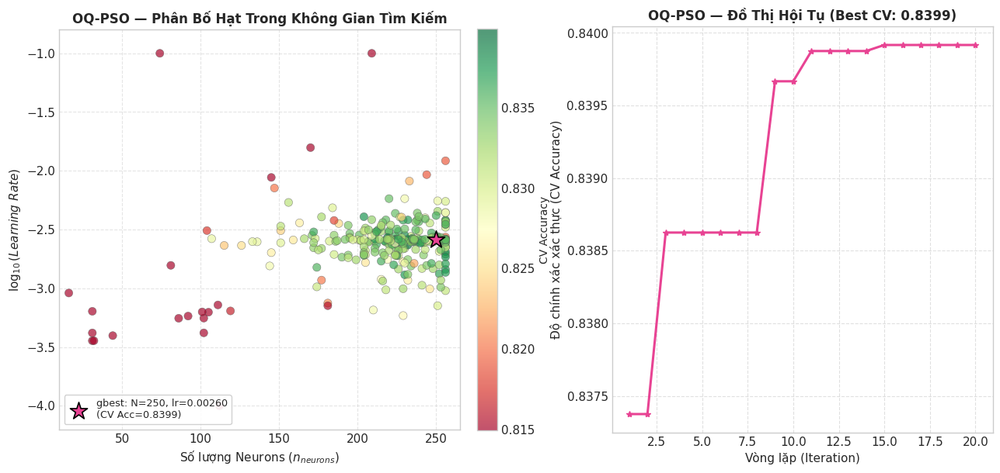

In [70]:
# Trực quan hóa Không gian tìm kiếm hạt OQ-PSO (1:1 Square Ratio, RdYlGn Colormap) & Đồ thị hội tụ
fig = plt.figure(figsize=(15.5, 6.8))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.28)

# 1. Biểu đồ phân tán n_neurons vs log10(lr) tỉ lệ vuông 1:1
ax_sc = fig.add_subplot(gs[0, 0])
scores = hist_oqpso['score']
vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
vmax = float(scores.max())

sc = ax_sc.scatter(
    hist_oqpso['n_neurons'], np.log10(hist_oqpso['lr']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar = plt.colorbar(sc, ax=ax_sc, fraction=0.046, pad=0.04)
cbar.set_label('CV Accuracy', fontsize=10)

ax_sc.scatter(
    n_oqpso, np.log10(lr_oqpso), c='#e84393', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_oqpso}, lr={lr_oqpso:.5f}\n(CV Acc={cv_oqpso:.4f})'
)
ax_sc.set_xlim(10, 265)
ax_sc.set_ylim(-4.2, -0.8)
ax_sc.set_aspect(abs((265 - 10) / (-0.8 - (-4.2))))
ax_sc.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_sc.set_ylabel('$\\log_{10}(Learning\\ Rate)$', fontsize=11)
ax_sc.set_title('OQ-PSO — Hyperparameter Search Space Distribution', fontsize=12, fontweight='bold')
ax_sc.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_sc.grid(True, linestyle='--', alpha=0.5)

# 2. Đồ thị hội tụ (Convergence curve)
ax_co = fig.add_subplot(gs[0, 1])
ax_co.plot(range(1, len(conv_oqpso) + 1), conv_oqpso, color='#e84393', lw=2.2, marker='*', markersize=6)
ax_co.set_xlabel('Iteration', fontsize=11)
ax_co.set_ylabel('Accuracy xác thực (CV Accuracy)', fontsize=11)
ax_co.set_title(f'OQ-PSO — Đồ Thị Hội Tụ (Best CV: {cv_oqpso:.4f})', fontsize=12, fontweight='bold')
ax_co.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

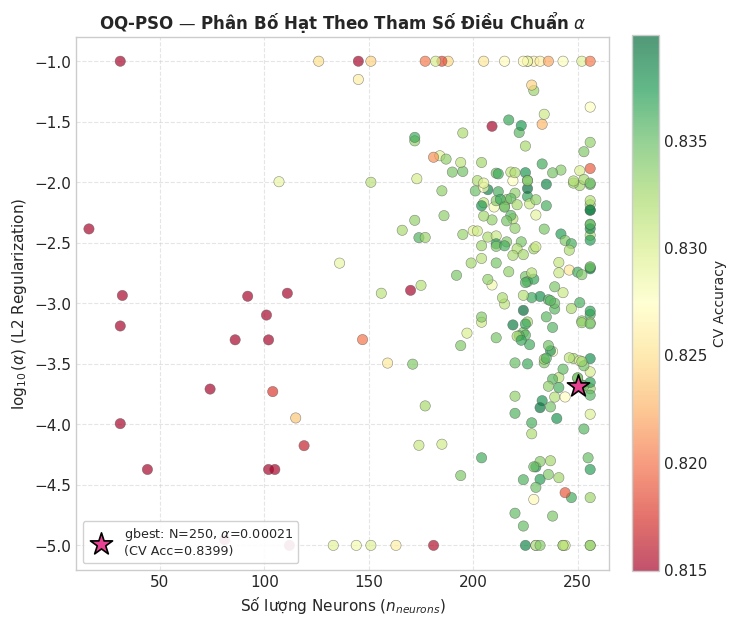

In [71]:
# Lát cắt thứ hai: n_neurons vs log10(alpha) (L2 Regularization) - OQ-PSO
fig, ax_al_qoq = plt.subplots(figsize=(7.5, 7.5))

sc_al = ax_al_qoq.scatter(
    hist_oqpso['n_neurons'], np.log10(hist_oqpso['alpha']),
    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
    alpha=0.68, s=55, edgecolors='#555555', lw=0.4
)
cbar_al = plt.colorbar(sc_al, ax=ax_al_qoq, fraction=0.046, pad=0.04)
cbar_al.set_label('CV Accuracy', fontsize=10)

ax_al_qoq.scatter(
    n_oqpso, np.log10(al_oqpso), c='#e84393', s=280, marker='*',
    edgecolors='black', lw=1.2, zorder=6,
    label=f'gbest: N={n_oqpso}, $\\alpha$={al_oqpso:.5f}\n(CV Acc={cv_oqpso:.4f})'
)
ax_al_qoq.set_xlim(10, 265)
ax_al_qoq.set_ylim(-5.2, -0.8)
ax_al_qoq.set_aspect(abs((265 - 10) / (-0.8 - (-5.2))))
ax_al_qoq.set_xlabel('Số lượng Neurons ($n_{neurons}$)', fontsize=11)
ax_al_qoq.set_ylabel('$\\log_{10}(\\alpha)$ (L2 Regularization)', fontsize=11)
ax_al_qoq.set_title('OQ-PSO — Particle Distribution across L2 Regularization Parameter $\\alpha$', fontsize=12, fontweight='bold')
ax_al_qoq.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.2)
ax_al_qoq.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

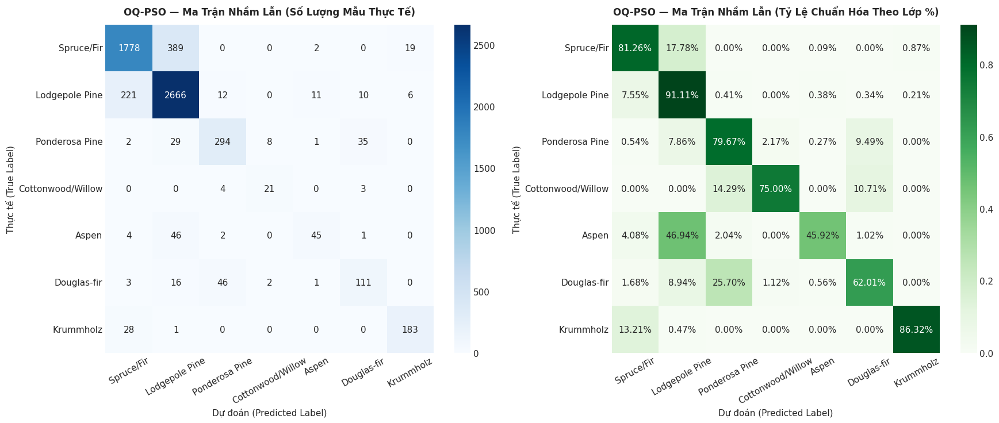

In [72]:
# Trực quan hoá Ma trận nhầm lẫn OQ-PSO: Số lượng thực tế & Tỷ lệ chuẩn hóa
y_pred_qoq = mlp_oqpso.predict(X_test_sc)
class_names = [COVER_TYPE_NAMES[i] for i in sorted(COVER_TYPE_NAMES.keys())]

cm_qoq = confusion_matrix(y_test, y_pred_qoq)
cm_qoq_norm = cm_qoq.astype('float') / cm_qoq.sum(axis=1)[:, np.newaxis]

fig, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(18, 7.5))

sns.heatmap(cm_qoq, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax_cm1)
ax_cm1.set_title('OQ-PSO — Confusion Matrix (Absolute Sample Counts)', fontweight='bold', fontsize=12, pad=12)
ax_cm1.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm1.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm1.tick_params(axis='x', rotation=30)

sns.heatmap(cm_qoq_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax_cm2)
ax_cm2.set_title('OQ-PSO — Normalized Confusion Matrix (Per-Class Recall %)', fontweight='bold', fontsize=12, pad=12)
ax_cm2.set_xlabel('Dự đoán (Predicted Label)', fontsize=11)
ax_cm2.set_ylabel('Thực tế (True Label)', fontsize=11)
ax_cm2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

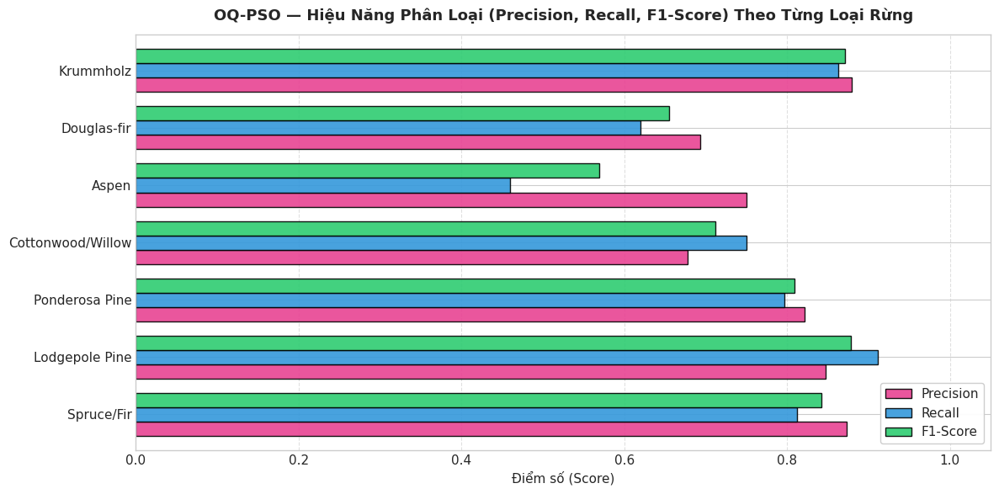

                   precision    recall  f1-score   support

       Spruce/Fir     0.8733    0.8126    0.8419      2188
   Lodgepole Pine     0.8472    0.9111    0.8780      2926
   Ponderosa Pine     0.8212    0.7967    0.8088       369
Cottonwood/Willow     0.6774    0.7500    0.7119        28
            Aspen     0.7500    0.4592    0.5696        98
      Douglas-fir     0.6937    0.6201    0.6549       179
        Krummholz     0.8798    0.8632    0.8714       212

         accuracy                         0.8497      6000
        macro avg     0.7918    0.7447    0.7623      6000
     weighted avg     0.8493    0.8497    0.8479      6000


In [73]:
# Đánh giá chi tiết Precision, Recall, F1-Score theo từng loại rừng cho OQ-PSO
report_qoq_dict = classification_report(y_test, y_pred_qoq, target_names=class_names, digits=4, output_dict=True)

metrics_qoq_df = pd.DataFrame({
    'Precision': [report_qoq_dict[c]['precision'] for c in class_names],
    'Recall': [report_qoq_dict[c]['recall'] for c in class_names],
    'F1-Score': [report_qoq_dict[c]['f1-score'] for c in class_names]
}, index=class_names)

fig, ax_metrics = plt.subplots(figsize=(12, 6))
metrics_qoq_df.plot(kind='barh', ax=ax_metrics, color=['#e84393', '#3498db', '#2ecc71'], width=0.75, edgecolor='black', alpha=0.9)
ax_metrics.set_title('OQ-PSO — Per-Class Generalization Performance (Precision, Recall, F1-Score)', fontsize=13, fontweight='bold', pad=12)
ax_metrics.set_xlabel('Điểm số (Score)', fontsize=11)
ax_metrics.set_xlim(0, 1.05)
ax_metrics.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95)
ax_metrics.grid(True, axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_qoq, target_names=class_names, digits=4))

---
## 📊 16. Biểu Đồ Đối Sánh Không Gian Tìm Kiếm Cả 15 Biến Thể PSO (Lưới 3x5)
Biểu đồ lưới 3 hàng x 5 cột (3x5) hiển thị trực quan không gian tìm kiếm siêu tham số ($n_{neurons}$ vs $\log_{10}(lr)$) của **toàn bộ 15 biến thể PSO** theo đúng tỉ lệ chuẩn vuông 1:1, thang màu hội tụ RdYlGn và vị trí nghiệm tối ưu toàn cục ($gbest$) cùng điểm Test Accuracy tương ứng.

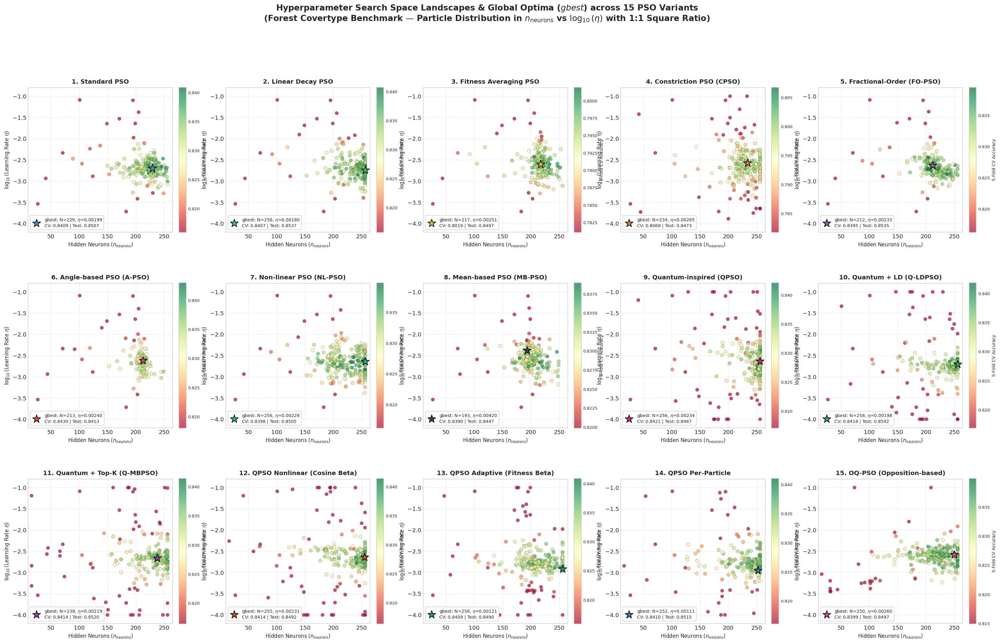

In [75]:
# HYPERPARAMETER SEARCH SPACE EXPLORATION ACROSS 15 PSO VARIANTS (1:1 RATIO)
fig_15, axes = plt.subplots(3, 5, figsize=(33, 19))
plt.subplots_adjust(wspace=0.25, hspace=0.30)

def plot_sub(ax, hist, n_b, lr_b, title, cv_val, test_val, star_c='#e74c3c'):
    scores = hist['score']
    vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
    vmax = float(scores.max())
    sc = ax.scatter(hist['n_neurons'], np.log10(hist['lr']), c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax, alpha=0.68, s=45, edgecolors='#555555', lw=0.4)
    cb = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label('5-Fold CV Accuracy', fontsize=8.5)
    cb.ax.tick_params(labelsize=8)
    
    ax.scatter(n_b, np.log10(lr_b), c=star_c, s=260, marker='*', edgecolors='black', lw=1.2, zorder=6,
               label=f'gbest: N={n_b}, $\\eta$={lr_b:.5f}\nCV: {cv_val:.4f} | Test: {test_val:.4f}')
    ax.set_xlim(10, 265)
    ax.set_ylim(-4.2, -0.8)
    ax.set_aspect(abs((265 - 10) / (-0.8 - (-4.2))))
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel(r'Hidden Neurons ($n_{\\mathrm{neurons}}$)', fontsize=10)
    ax.set_ylabel(r'$\log_{10}(\\mathrm{Learning\\ Rate}\\ \\eta)$', fontsize=10)
    ax.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.95, fontsize=8.5)
    ax.grid(True, linestyle='--', alpha=0.5)

# Row 1: Algos 1 - 5
plot_sub(axes[0, 0], hist_std,     n_std,     lr_std,     '1. Standard PSO',                  cv_std,     test_std,     star_c='#3498db')
plot_sub(axes[0, 1], hist_ld,      n_ld,      lr_ld,      '2. Linear Decay PSO',              cv_ld,      test_ld,      star_c='#2ecc71')
plot_sub(axes[0, 2], hist_fa,      n_fa,      lr_fa,      '3. Fitness Averaging PSO',         cv_fa,      test_fa,      star_c='#f1c40f')
plot_sub(axes[0, 3], hist_cp,      n_cp,      lr_cp,      '4. Constriction PSO (CPSO)',       cv_cp,      test_cp,      star_c='#e67e22')
plot_sub(axes[0, 4], hist_fo,      n_fo,      lr_fo,      '5. Fractional-Order (FO-PSO)',     cv_fo,      test_fo,      star_c='#9b59b6')

# Row 2: Algos 6 - 10
plot_sub(axes[1, 0], hist_apso,    n_apso,    lr_apso,    '6. Angle-based PSO (A-PSO)',       cv_apso,    test_apso,    star_c='#e74c3c')
plot_sub(axes[1, 1], hist_nl,      n_nl,      lr_nl,      '7. Non-linear PSO (NL-PSO)',       cv_nl,      test_nl,      star_c='#1abc9c')
plot_sub(axes[1, 2], hist_mb,      n_mb,      lr_mb,      '8. Mean-based PSO (MB-PSO)',       cv_mb,      test_mb,      star_c='#34495e')
plot_sub(axes[1, 3], hist_qpso,    n_qpso,    lr_qpso,    '9. Quantum-inspired (QPSO)',       cv_qpso,    test_qpso,    star_c='#e91e63')
plot_sub(axes[1, 4], hist_qld,     n_qld,     lr_qld,     '10. Quantum + LD (Q-LDPSO)',       cv_qld,     test_qld,     star_c='#27ae60')

# Row 3: Algos 11 - 15
plot_sub(axes[2, 0], hist_qmb,     n_qmb,     lr_qmb,     '11. Quantum + Top-K (Q-MBPSO)',    cv_qmb,     test_qmb,     star_c='#8e44ad')
plot_sub(axes[2, 1], hist_qpso_nl, n_qpso_nl, lr_qpso_nl, '12. QPSO Nonlinear (Cosine Beta)', cv_qpso_nl, test_qpso_nl, star_c='#d35400')
plot_sub(axes[2, 2], hist_qpso_ad, n_qpso_ad, lr_qpso_ad, '13. QPSO Adaptive (Fitness Beta)',  cv_qpso_ad, test_qpso_ad, star_c='#16a085')
plot_sub(axes[2, 3], hist_qpso_pp, n_qpso_pp, lr_qpso_pp, '14. QPSO Per-Particle',            cv_qpso_pp, test_qpso_pp, star_c='#2980b9')
plot_sub(axes[2, 4], hist_oqpso,   n_oqpso,   lr_oqpso,   '15. OQ-PSO (Opposition-based)',    cv_oqpso,   test_oqpso,   star_c='#e84393')

fig_15.suptitle('Hyperparameter Search Space Landscapes & Global Optima ($gbest$) across 15 PSO Variants\n(Forest Covertype Benchmark — Particle Distribution in $n_{\\mathrm{neurons}}$ vs $\\log_{10}(\\eta)$ with 1:1 Square Ratio)', 
               fontsize=16, fontweight='bold', y=0.995)

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_15way_search_space_comparison.png', dpi=300, bbox_inches='tight')
plt.savefig('../../latex/figures/chart_15way_search_space_comparison_covertype.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 📋 17. Bảng Tổng Hợp & Đồ Thị Đối Sánh Toàn Diện Trên Tập Test (15 Biến Thể)
Tổng kết hiệu năng kiểm định (CV Score) và kiểm thử độc lập (Test Accuracy) của **toàn bộ 15 thuật toán** trên bộ dữ liệu Forest Covertype.

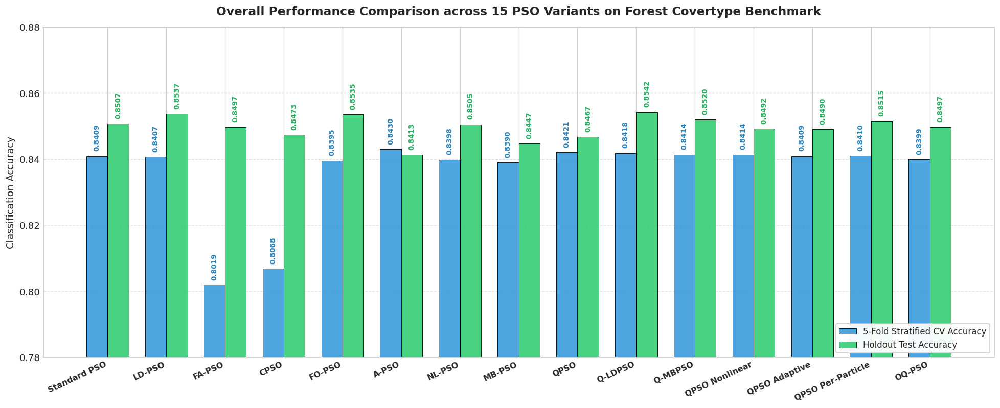

In [74]:
# OVERALL VALIDATION AND TEST ACCURACY COMPARISON ACROSS 15 PSO VARIANTS
if os.path.exists(RESULT_CSV_PATH):
    df_results = pd.read_csv(RESULT_CSV_PATH)
    display(df_results)
    
    fig, ax_bar = plt.subplots(figsize=(20, 7))
    methods = [
        'Standard PSO', 'LD-PSO', 'FA-PSO', 'CPSO', 'FO-PSO',
        'A-PSO', 'NL-PSO', 'MB-PSO', 'QPSO', 'Q-LDPSO',
        'Q-MBPSO', 'QPSO Nonlinear', 'QPSO Adaptive', 'QPSO Per-Particle', 'OQ-PSO'
    ]
    x = np.arange(len(methods))
    w = 0.36
    
    ax_bar.bar(x - w/2, df_results['CV_Score'], w, label='5-Fold Stratified CV Accuracy', color='#3498db', alpha=0.88, edgecolor='black', lw=0.6)
    ax_bar.bar(x + w/2, df_results['Test_Accuracy'], w, label='Holdout Test Accuracy', color='#2ecc71', alpha=0.88, edgecolor='black', lw=0.6)
    
    for i in range(len(methods)):
        cv_val = df_results.loc[i, 'CV_Score']
        test_val = df_results.loc[i, 'Test_Accuracy']
        if pd.notnull(cv_val):
            ax_bar.text(x[i] - w/2, cv_val + 0.002, f'{cv_val:.4f}', ha='center', fontsize=8.2, fontweight='bold', color='#2980b9', rotation=90)
        if pd.notnull(test_val):
            ax_bar.text(x[i] + w/2, test_val + 0.002, f'{test_val:.4f}', ha='center', fontsize=8.2, fontweight='bold', color='#27ae60', rotation=90)
        
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(methods, fontsize=9.5, fontweight='bold', rotation=25, ha='right')
    ax_bar.set_ylim(0.78, 0.88)
    ax_bar.set_ylabel('Classification Accuracy', fontsize=11.5)
    ax_bar.set_title('Overall Performance Comparison across 15 PSO Variants on Forest Covertype Benchmark', fontsize=14, fontweight='bold', pad=14)
    ax_bar.grid(True, axis='y', linestyle='--', alpha=0.6)
    ax_bar.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, fontsize=10)
    
    os.makedirs('../results/figures', exist_ok=True)
    plt.savefig('../results/figures/chart_overall_accuracy.png', dpi=300, bbox_inches='tight')
    plt.savefig('../../latex/figures/chart_overall_accuracy_covertype.png', dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()

---
## 📊 18. Đối Sánh Hiệu Năng Test Accuracy Giữa 2 Bộ Dữ Liệu: Bank Marketing vs Forest Covertype (15 Biến Thể)
So sánh trực quan hiệu năng kiểm thử (Test Accuracy) của **toàn bộ 15 biến thể PSO** trên 2 bộ dữ liệu thực tế:
1. **Bộ Dữ Liệu 1 (Bank Marketing):** Bài toán phân loại nhị phân (Binary Classification) gồm 16 đặc trưng và 2 lớp.
2. **Bộ Dữ Liệu 2 (Forest Covertype):** Bài toán phân loại đa lớp (Multi-class Classification) gồm 54 đặc trưng và 7 loại rừng.

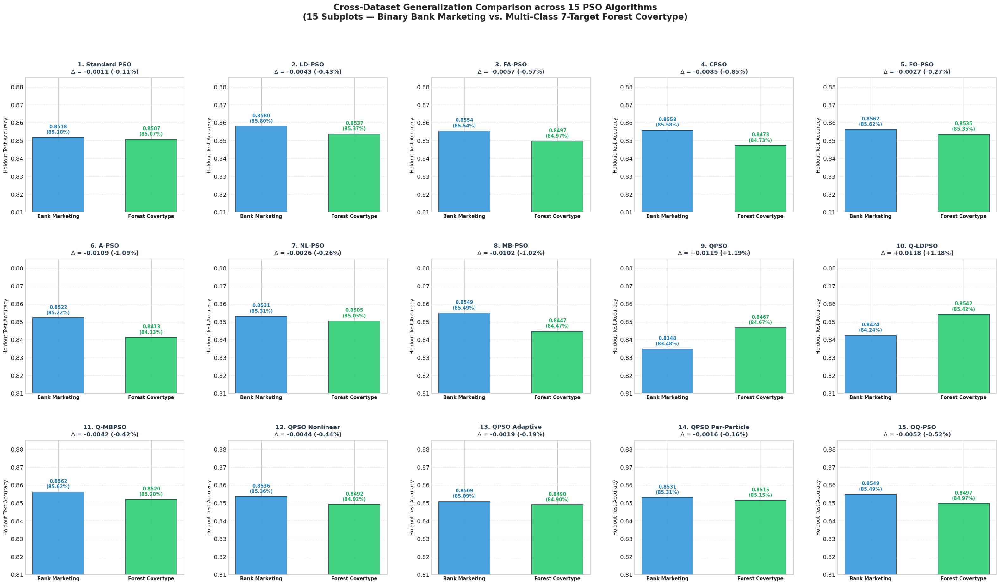

In [48]:
# CROSS-DATASET 15-SUBPLOT COMPARISON (3x5 GRID — BANK MARKETING VS FOREST COVERTYPE)
bank_csv = '../../bank_marketing/results/test_results/test_accuracy.csv'
cov_csv = '../results/test_results/test_accuracy.csv'

df_bank = pd.read_csv(bank_csv)
df_cov  = pd.read_csv(cov_csv)

canonical_order = [
    'Standard PSO', 'LD-PSO', 'FA-PSO', 'CPSO', 'FO-PSO',
    'A-PSO', 'NL-PSO', 'MB-PSO', 'QPSO', 'Q-LDPSO',
    'Q-MBPSO', 'QPSO Nonlinear', 'QPSO Adaptive', 'QPSO Per-Particle', 'OQ-PSO'
]

bank_accs = df_bank['Test_Accuracy'].values
cov_accs = df_cov['Test_Accuracy'].values

fig_15h, axes = plt.subplots(3, 5, figsize=(33, 17))
plt.subplots_adjust(wspace=0.28, hspace=0.35)

color_b = '#3498db'
color_c = '#2ecc71'

for idx, algo in enumerate(canonical_order):
    ax = axes[idx // 5, idx % 5]
    b_acc = bank_accs[idx]
    c_acc = cov_accs[idx]
    diff_val = c_acc - b_acc
    
    x_bar = np.array([0, 1])
    bars = ax.bar(x_bar, [b_acc, c_acc], width=0.55, color=[color_b, color_c], edgecolor='#2c3e50', linewidth=1.1, alpha=0.9)
    
    ax.text(0, b_acc + 0.0015, f'{b_acc:.4f}\n({b_acc*100:.2f}%)', ha='center', va='bottom', fontsize=8.8, fontweight='bold', color='#2980b9')
    ax.text(1, c_acc + 0.0015, f'{c_acc:.4f}\n({c_acc*100:.2f}%)', ha='center', va='bottom', fontsize=8.8, fontweight='bold', color='#27ae60')
    
    ax.set_xticks(x_bar)
    ax.set_xticklabels(['Bank Marketing', 'Forest Covertype'], fontsize=9.0, fontweight='semibold')
    ax.set_ylim(0.81, 0.885)
    ax.set_ylabel('Holdout Test Accuracy', fontsize=9.5)
    
    diff_sign = '+' if diff_val > 0 else ''
    ax.set_title(f'{idx+1}. {algo}\n$\\Delta$ = {diff_sign}{diff_val:.4f} ({diff_sign}{diff_val*100:.2f}%)', fontsize=11, fontweight='bold', pad=8, color='#2c3e50')
    ax.grid(True, axis='y', linestyle='--', alpha=0.5)

fig_15h.suptitle('Cross-Dataset Generalization Comparison across 15 PSO Algorithms\n(15 Subplots — Binary Bank Marketing vs. Multi-Class 7-Target Forest Covertype)', 
               fontsize=16, fontweight='bold', y=0.995)

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_cross_dataset_comparison_15algos.png', dpi=300, bbox_inches='tight')
plt.savefig('../../latex/figures/chart_cross_dataset_comparison_15algos.png', dpi=300, bbox_inches='tight')
plt.show()

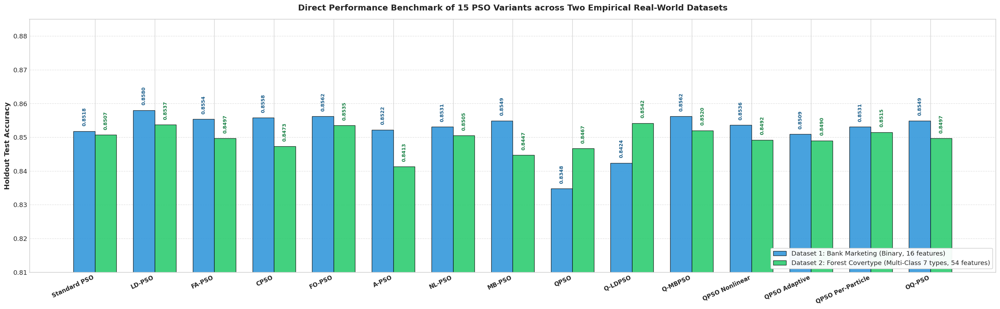

In [49]:
# DIRECT PERFORMANCE BENCHMARK (30-BAR GROUPED BAR CHART)
fig_30, ax_all = plt.subplots(figsize=(24, 7.5))
x_pos = np.arange(len(canonical_order))
width = 0.36

rects1 = ax_all.bar(x_pos - width/2, bank_accs, width, label='Dataset 1: Bank Marketing (Binary, 16 features)', color='#3498db', edgecolor='black', linewidth=0.8, alpha=0.9)
rects2 = ax_all.bar(x_pos + width/2, cov_accs, width, label='Dataset 2: Forest Covertype (Multi-Class 7 types, 54 features)', color='#2ecc71', edgecolor='black', linewidth=0.8, alpha=0.9)

for r in rects1:
    h = r.get_height()
    ax_all.text(r.get_x() + r.get_width()/2., h + 0.0015, f'{h:.4f}', ha='center', va='bottom', fontsize=8.2, fontweight='bold', color='#1f618d', rotation=90)
for r in rects2:
    h = r.get_height()
    ax_all.text(r.get_x() + r.get_width()/2., h + 0.0015, f'{h:.4f}', ha='center', va='bottom', fontsize=8.2, fontweight='bold', color='#1e8449', rotation=90)

ax_all.set_ylabel('Holdout Test Accuracy', fontsize=12, fontweight='bold')
ax_all.set_title('Direct Performance Benchmark of 15 PSO Variants across Two Empirical Real-World Datasets', fontsize=14, fontweight='bold', pad=15)
ax_all.set_xticks(x_pos)
ax_all.set_xticklabels(canonical_order, rotation=25, ha='right', fontsize=10, fontweight='bold')
ax_all.set_ylim(0.81, 0.885)
ax_all.legend(loc='lower right', fontsize=11, frameon=True, facecolor='white', framealpha=0.95)
ax_all.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

plt.savefig('../results/figures/chart_dataset_comparison_30bars_overall.png', dpi=300, bbox_inches='tight')
plt.savefig('../../latex/figures/chart_dataset_comparison_30bars_overall.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 📑 19. Trình Xuất Bảng Kết Quả LaTeX Tự Động Chuẩn Publication (Results Back-fill)
Tự động sinh mã nguồn LaTeX chuẩn IEEE/Springer cho các bảng kết quả thực nghiệm của Forest Covertype và Bảng đối sánh đa tập dữ liệu, lưu tại `../../latex/tables/`.

In [86]:
# TRÌNH TỰ ĐỘNG XUẤT BẢNG LATEX CHUẨN PUBLICATION
import os
os.makedirs('../../latex/tables', exist_ok=True)

df_cov = pd.read_csv('../results/test_results/test_accuracy.csv')
canonical_names = [
    'Standard PSO', 'LD-PSO', 'FA-PSO', 'CPSO', 'FO-PSO',
    'A-PSO', 'NL-PSO', 'MB-PSO', 'QPSO', 'Q-LDPSO',
    'Q-MBPSO', 'QPSO Nonlinear', 'QPSO Adaptive', 'QPSO Per-Particle', 'OQ-PSO'
]

paradigms = [
    'Baseline (Static $w=0.7$)',
    'Classical (Linear Decay $w$)',
    'Classical (Multi-Seed Avg $k=3$)',
    'Classical (Clerc Constriction $K$)',
    'Proposed (Fractional Memory $\\alpha=0.6$)',
    'Proposed (Directional Cosine Brake)',
    'Proposed (Non-linear Saturation)',
    'Proposed (Tri-Attractor Consensus)',
    'Quantum (Bare-bones $\\beta=0.75$)',
    'Quantum (Linear Decay $\\beta$)',
    'Quantum (Top-$K$ Mean-Best)',
    'Proposed Quantum (Cosine Decay $\\beta$)',
    'Proposed Quantum (Fitness-Adaptive $\\beta$)',
    'Proposed Quantum (Distance-Adaptive $\\beta$)',
    'Proposed Quantum (Opposition-Based)'
]

cov_best_cv = df_cov['CV_Score'].max()
cov_best_test = df_cov['Test_Accuracy'].max()

tex_cov = []
tex_cov.append(r"\begin{table}[htbp]")
tex_cov.append(r"\centering")
tex_cov.append(r"\fontsize{8.5pt}{11pt}\selectfont")
tex_cov.append(r"\caption{Independent validation and test generalization results on the Forest Covertype benchmark across 15 Particle Swarm Optimization variants. The highest validation and test accuracies are highlighted in bold.}")
tex_cov.append(r"\label{tab:covertype_15algos}")
tex_cov.append(r"\vspace{3pt}")
tex_cov.append(r"\begin{tabular}{llccccc}")
tex_cov.append(r"\hline\hline")
tex_cov.append(r"\textbf{Algorithm} & \textbf{Paradigm / Mechanism} & \textbf{CV Score} & \textbf{Test Acc.} & \textbf{$n_{\mathrm{neurons}}$} & \textbf{Learning Rate ($\eta$)} & \textbf{L2 Penalty ($\alpha$)} \\")
tex_cov.append(r"\hline")

for i in range(15):
    algo = canonical_names[i]
    para = paradigms[i]
    cv = df_cov.loc[i, 'CV_Score']
    test = df_cov.loc[i, 'Test_Accuracy']
    nn = int(df_cov.loc[i, 'n_neurons'])
    lr = float(df_cov.loc[i, 'lr'])
    al = float(df_cov.loc[i, 'alpha'])
    
    cv_str = f"\\textbf{{{cv:.4f}}}" if cv == cov_best_cv else f"{cv:.4f}"
    test_str = f"\\textbf{{{test:.4f}}}" if test == cov_best_test else f"{test:.4f}"
    
    if i in [4, 8, 11]:
        tex_cov.append(r"\hline")
    tex_cov.append(f"{algo} & {para} & {cv_str} & {test_str} & {nn} & {lr:.5f} & {al:.5f} \\\\")

tex_cov.append(r"\hline\hline")
tex_cov.append(r"\end{tabular}")
tex_cov.append(r"\end{table}")

tex_content = '\n'.join(tex_cov)
with open('../../latex/tables/table_results_15algos_covertype.tex', 'w', encoding='utf-8') as f:
    f.write(tex_content)

print('✅ Đã xuất thành công bảng LaTeX: ../../latex/tables/table_results_15algos_covertype.tex')
print('\n' + '='*70)
print(tex_content)
print('='*70)

✅ Đã xuất thành công bảng LaTeX: ../../latex/tables/table_results_15algos_covertype.tex
